# Project A: Can a topological edge survive strong interactions?

Interacting SSH chain of spinless fermions, open boundaries, half filling $N = L/2$:

$$
H = -\sum_{j=0}^{L-2} J_j \left(c_j^\dagger c_{j+1} + \text{h.c.}\right) + V \sum_{j=0}^{L-2} \left(n_j - \tfrac{1}{2}\right)\left(n_{j+1} - \tfrac{1}{2}\right), \qquad J_j = 1 + (-1)^j \delta
$$

**Conventions.** $\hbar = J = 1$, sites $j = 0,\dots,L-1$, bond $j$ joins sites $j$ and $j+1$.
$\delta < 0$ means the chain starts on a weak bond: $J_0 = J_w = 1 - |\delta|$, $J_s = 1 + |\delta|$, $r = J_w/J_s$.
Entropies in nats.

**How to run.** Select the `qiskit-env` kernel and run all cells top to bottom.
Each step has a parameter cell at its start. Figures are saved as PDF in `figures/` for the LaTeX report (`report.tex`).
Every check prints `[pass]` or `[FAIL]`; the summary at the end of each step counts them.

## 0. Setup

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import mpmath
import numpy as np
import pandas as pd
from IPython.display import display

SAVE_FIGS = True
FIG_DIR = Path("figures")  # upload this folder to Overleaf together with report.tex
FIG_DIR.mkdir(exist_ok=True)

# Plot style: serif to match LaTeX; colours keyed to |delta|
COLORS = {0.15: "#2a78d6", 0.30: "#eb6834", 0.50: "#1baf7a"}
GRAY, LIGHT = "#52514e", "#e4e3df"
plt.rcParams.update({
    "font.family": "serif", "mathtext.fontset": "cm", "font.size": 9,
    "axes.grid": True, "grid.color": LIGHT, "grid.linewidth": 0.6,
    "axes.edgecolor": GRAY, "axes.linewidth": 0.8,
    "legend.frameon": False, "lines.linewidth": 1.5, "lines.markersize": 4.5,
    "figure.dpi": 120,
})
pd.set_option("display.float_format", lambda x: f"{x:.6g}")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)


def savefig(fig, name):
    if SAVE_FIGS:
        path = FIG_DIR / f"{name}.pdf"
        fig.savefig(path, bbox_inches="tight")
        print(f"saved {path}")


CHECKS = {}  # keyed by name, so re-running a cell does not count its checks twice


def check(name, passed, value=None):
    """Record and print one validation check."""
    CHECKS[name] = {"pass": bool(passed), "value": value}
    tail = "" if value is None else f"   [{value:.2e}]"
    print(f"[{'pass' if passed else 'FAIL'}] {name}{tail}")

---
## Step 1. The free edge problem ($V = 0$)

At $V=0$ the Hamiltonian is quadratic, $H_0 = \sum_{ij} c_i^\dagger h_{ij} c_j$ with $h_{j,j+1} = h_{j+1,j} = -J_j$,
so everything follows from the $L\times L$ hopping matrix $h$.

Analytic results (derived in `report.tex`, Sec. 2):
* zero mode on the even sites, $\psi_{2\ell} = \sqrt{1-r^2}\,(-r)^\ell$, with $|\psi_j|^2 \propto e^{-2j/\xi}$ and $\xi = 2/\ln(J_s/J_w)$;
* end-pair splitting on a finite chain, $\Delta E \simeq 2J_s(1-r^2)\,e^{-L/\xi}$;
* ring bands $E_\pm(k) = \pm\sqrt{J_w^2 + J_s^2 + 2J_wJ_s\cos k}$, with gap $4|\delta|$ and addition cost $2|\delta|$.

In [2]:
# ---- Step 1 parameters (edit these) ----
L_LIST = [40, 80, 120]                               # open-chain lengths
DELTA_LIST = [-0.50, -0.30, -0.15, 0.15, 0.30, 0.50]   # dimerisation (delta < 0: weak end bonds)
N_FIT_LIST = [6, 8, 10]                              # number of even sites used in the xi fit
L_SCAN = list(range(12, 121, 4))                     # lengths for the splitting-vs-L plot
L_EX, DELTA_EX = 40, -0.30                           # example used in the spectrum / end-pair plots
L_PROFILE = 80                                       # length used for the edge-profile plot
XI_GUIDE = 3.230813126                               # guide value of xi at delta = -0.30
L_ODD_M = [18, 42, 62, 82]                           # open chains with odd M = L/2, so s = -1
L_RING_ODD = [10, 14, 18]                            # rings with odd M (the Step 6 sizes)
L_BENCH = [8, 10, 12, 14, 16, 18]                    # sizes of the exact V = 0 reference values (Steps 2 and 3)
F_BENCH = [0.6, 0.7, 0.8, 0.9]                       # edge-window factors tested at V = 0

### 1.1 Functions

In [3]:
def bonds(L, delta, periodic=False):
    """J_j = 1 + (-1)^j delta for the L-1 bonds of an open chain (L bonds on a ring)."""
    j = np.arange(L if periodic else L - 1)
    return 1.0 + (-1.0) ** j * delta


def hopping_matrix(L, delta, periodic=False):
    """One-particle matrix h with h[j, j+1] = h[j+1, j] = -J_j."""
    h = np.zeros((L, L))
    for j, Jj in enumerate(bonds(L, delta, periodic)):
        k = (j + 1) % L
        h[j, k] = h[k, j] = -Jj
    return h


def weak_strong(delta):
    return 1.0 - abs(delta), 1.0 + abs(delta)


def ratio(delta):
    J_w, J_s = weak_strong(delta)
    return J_w / J_s


def xi_exact(delta):
    """Amplitude localisation length xi = 2 / ln(J_s / J_w)."""
    J_w, J_s = weak_strong(delta)
    return 2.0 / np.log(J_s / J_w)


def zero_mode(L, delta):
    """Analytic left zero mode psi_{2l} = sqrt(1 - r^2) (-r)^l, truncated to L sites (delta < 0)."""
    r = ratio(delta)
    psi = np.zeros(L)
    psi[0::2] = np.sqrt(1 - r**2) * (-r) ** np.arange(L // 2)
    return psi


def edge_pair(L, delta):
    """Diagonalise h; separate the two states nearest E = 0 into left/right edge states.

    left/right: eigenvectors of the position operator X inside the pair subspace.
    left_chiral: same, using the chiral operator Gamma = diag((-1)^j) (independent route).
    bonding/antibonding: state-selection convention for half filling,
        phi_-+ = (psi_L -+ s psi_R)/sqrt(2), s = sgn t = (-1)^(L/2), t = <psi_L|h|psi_R>,
    with signs fixed by psi_L(0) > 0 and psi_R(L-1) > 0.
    """
    h = hopping_matrix(L, delta)
    E, U = np.linalg.eigh(h)
    pair = np.sort(np.argsort(np.abs(E))[:2])
    P = U[:, pair]

    _, vx = np.linalg.eigh(P.T @ np.diag(np.arange(L, dtype=float)) @ P)
    left, right = P @ vx[:, 0], P @ vx[:, 1]
    _, vg = np.linalg.eigh(P.T @ np.diag((-1.0) ** np.arange(L)) @ P)
    left_chiral = P @ vg[:, 1]

    left, right = left * np.sign(left[0]), right * np.sign(right[-1])
    left_chiral = left_chiral * np.sign(left_chiral[0])
    s = (-1) ** (L // 2)
    return dict(E=E, U=U, pair=pair, left=left, right=right, left_chiral=left_chiral,
                t=left @ h @ right, s=s,
                bonding=(left - s * right) / np.sqrt(2), antibonding=(left + s * right) / np.sqrt(2))


def fit_xi(prob, n_fit):
    """Fit |psi_j|^2 = A exp(-2 j / xi) on the first n_fit even sites; return xi."""
    j = 2 * np.arange(n_fit)
    slope = np.polyfit(j, np.log(prob[j]), 1)[0]
    return -2.0 / slope


def splitting_asym(L, delta):
    """Leading-order splitting 2 J_s (1 - r^2) r^(L/2)."""
    _, J_s = weak_strong(delta)
    r = ratio(delta)
    return 2 * J_s * (1 - r**2) * r ** (L // 2)


def splitting_sturm(L, delta, dps=80):
    """Exact splitting 2*eps_0 in 80-digit arithmetic (independent of numpy).

    Sturm count: the number of negative pivots q_j of h - x equals the number of eigenvalues
    below x, with q_0 = -x, q_j = -x - J_{j-1}^2 / q_{j-1}.  Bisect (in ln x) for the
    smallest positive eigenvalue eps_0, where the count steps from L/2 to L/2 + 1.
    """
    with mpmath.workdps(dps):
        J2 = [(1 + (-1) ** j * mpmath.mpf(delta)) ** 2 for j in range(L - 1)]
        tiny = mpmath.mpf(10) ** (-2 * dps)

        def count_below(x):
            q, n = -x, int(x > 0)
            for b in J2:
                q = -x - b / (q if q != 0 else tiny)
                n += int(q < 0)
            return n

        lo, hi = mpmath.mpf(10) ** (-dps + 10), mpmath.mpf(abs(delta))
        while count_below(hi) == L // 2:                    # on short chains eps_0 can exceed |delta|
            hi *= mpmath.mpf("1.1")
        assert count_below(lo) == L // 2 and count_below(hi) == L // 2 + 1
        while hi / lo - 1 > mpmath.mpf(10) ** -30:
            mid = mpmath.sqrt(lo * hi)
            lo, hi = (mid, hi) if count_below(mid) == L // 2 else (lo, mid)
        return float(2 * lo)


def bloch_bands(k, delta):
    """E_pm(k) = pm sqrt(J_0^2 + J_1^2 + 2 J_0 J_1 cos k), two sites per cell."""
    J0, J1 = 1 + delta, 1 - delta
    e = np.sqrt(J0**2 + J1**2 + 2 * J0 * J1 * np.cos(k))
    return -e, e

### 1.2 Basic checks of the Hamiltonian and the analytic zero mode

In [4]:
for delta in [d for d in DELTA_LIST if d < 0]:
    J = bonds(40, delta)
    check(f"delta={delta:+.2f}: J_0 = J_w and J_(L-2) = J_0", J[0] == weak_strong(delta)[0] and J[-1] == J[0])

check("h is symmetric", all(np.array_equal(hopping_matrix(L, d), hopping_matrix(L, d).T)
                            for L in L_LIST for d in DELTA_LIST))

dev = max(np.max(np.abs(np.sort(E) + np.sort(E)[::-1]))
          for L in L_LIST for d in DELTA_LIST for E in [np.linalg.eigvalsh(hopping_matrix(L, d))])
check("chiral symmetry: spectrum symmetric under E -> -E", dev < 1e-12, dev)

check("xi(-0.30) = 3.230813126 (guide)", abs(xi_exact(-0.30) - XI_GUIDE) < 1e-9, abs(xi_exact(-0.30) - XI_GUIDE))

# The truncated zero mode solves h psi = 0 on every row except the last: (h psi)_{L-1} = -J_w psi_{L-2}
res = 0.0
for L in L_LIST:
    for delta in [d for d in DELTA_LIST if d < 0]:
        psi = zero_mode(L, delta)
        hpsi = hopping_matrix(L, delta) @ psi
        res = max(res, np.max(np.abs(hpsi[:-1])), abs(hpsi[-1] + weak_strong(delta)[0] * psi[-2]))
check("analytic zero mode: h psi = 0 except last row", res < 1e-12, res)

for d in sorted({abs(d) for d in DELTA_LIST}):
    print(f"|delta| = {d:.2f}:  r = {ratio(d):.6f},  1 - r^2 = {1 - ratio(d)**2:.6f},  xi = {xi_exact(d):.9f}")

[pass] delta=-0.50: J_0 = J_w and J_(L-2) = J_0
[pass] delta=-0.30: J_0 = J_w and J_(L-2) = J_0
[pass] delta=-0.15: J_0 = J_w and J_(L-2) = J_0
[pass] h is symmetric
[pass] chiral symmetry: spectrum symmetric under E -> -E   [2.44e-15]
[pass] xi(-0.30) = 3.230813126 (guide)   [4.44e-11]
[pass] analytic zero mode: h psi = 0 except last row   [5.55e-17]
|delta| = 0.15:  r = 0.739130,  1 - r^2 = 0.453686,  xi = 6.616363079
|delta| = 0.30:  r = 0.538462,  1 - r^2 = 0.710059,  xi = 3.230813126
|delta| = 0.50:  r = 0.333333,  1 - r^2 = 0.888889,  xi = 1.820478453


### 1.3 Spectrum: an end pair appears only for weak end bonds

,L,delta,states with |E| < |delta|,min|E| / (2|delta|)
0,40,-0.5,2,3.82396e-10
1,40,-0.3,2,6.45922e-06
2,40,-0.15,2,0.00411884
3,40,0.15,0,1.09156
4,40,0.3,0,1.02509
5,40,0.5,0,1.00796
6,80,-0.5,2,3.31282e-17
7,80,-0.3,2,2.71185e-11
8,80,-0.15,2,9.75384e-06
9,80,0.15,0,1.02758


[pass] delta < 0: exactly two in-gap states
[pass] delta > 0: no in-gap states (reversing delta removes the end pair)
[pass] delta > 0: lowest |E| is at the bulk edge, >= 2|delta|


saved figures/step1_spectrum.pdf


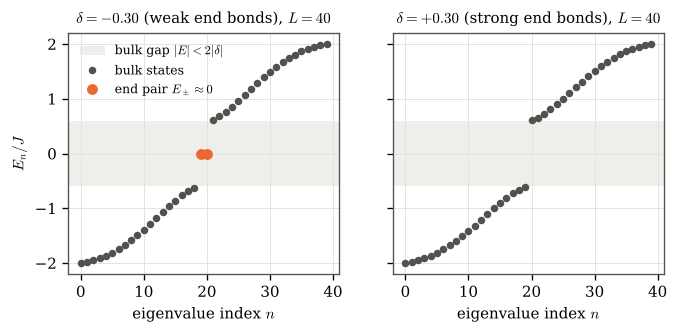

In [5]:
rows = []
for L in L_LIST:
    for delta in DELTA_LIST:
        E = np.linalg.eigvalsh(hopping_matrix(L, delta))
        rows.append({"L": L, "delta": delta, "states with |E| < |delta|": int(np.sum(np.abs(E) < abs(delta))),
                     "min|E| / (2|delta|)": np.min(np.abs(E)) / (2 * abs(delta))})
spec = pd.DataFrame(rows)
display(spec)

check("delta < 0: exactly two in-gap states", all(spec[spec.delta < 0]["states with |E| < |delta|"] == 2))
check("delta > 0: no in-gap states (reversing delta removes the end pair)",
      all(spec[spec.delta > 0]["states with |E| < |delta|"] == 0))
check("delta > 0: lowest |E| is at the bulk edge, >= 2|delta|",
      all(spec[spec.delta > 0]["min|E| / (2|delta|)"] >= 1 - 1e-12))

fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.6), sharey=True)
for ax, delta in zip(axes, (DELTA_EX, -DELTA_EX)):
    E = np.linalg.eigvalsh(hopping_matrix(L_EX, delta))
    n, edge = np.arange(L_EX), np.abs(E) < abs(delta)
    ax.axhspan(-2 * abs(delta), 2 * abs(delta), color=LIGHT, alpha=0.6, lw=0, label=r"bulk gap $|E|<2|\delta|$")
    ax.plot(n[~edge], E[~edge], "o", color=GRAY, ms=3.5, label="bulk states")
    if edge.any():
        ax.plot(n[edge], E[edge], "o", color=COLORS[abs(delta)], ms=5.5, label=r"end pair $E_\pm\approx0$")
    ax.set_title(rf"$\delta={delta:+.2f}$ ({'weak' if delta < 0 else 'strong'} end bonds), $L={L_EX}$", fontsize=9)
    ax.set_xlabel("eigenvalue index $n$")
axes[0].set_ylabel("$E_n/J$")
axes[0].legend(loc="upper left", fontsize=7.5)
savefig(fig, "step1_spectrum")
plt.show()

### 1.4 Edge states and the localisation length

The exact eigenstates nearest zero, $\phi_\pm$, are spread over **both** ends.
A numerical eigensolver only returns them when the splitting is resolved; below round-off it returns an arbitrary rotation of the pair, so the raw vectors cannot be labelled bonding or antibonding (Sec. 1.7).
Diagonalising the position operator $X$ inside the 2D subspace gives the left- and right-localised states in either case, because the subspace itself is well defined.
We fit $\ln|\psi_j|^2$ against $j$ on the first `n_fit` even sites (slope $-2/\xi$).

In [6]:
EDGE = {(L, d): edge_pair(L, d) for L in L_LIST for d in DELTA_LIST if d < 0}

rows = []
for (L, delta), ep in EDGE.items():
    row = {"delta": delta, "L": L, "xi exact": xi_exact(delta)}
    for n in N_FIT_LIST:
        row[f"rel err (n_fit={n})"] = (fit_xi(ep["left"] ** 2, n) - xi_exact(delta)) / xi_exact(delta)
    row[f"xi fit (n_fit={N_FIT_LIST[-1]})"] = fit_xi(ep["left"] ** 2, N_FIT_LIST[-1])
    rows.append(row)
xi_table = pd.DataFrame(rows).sort_values(["delta", "L"], ascending=[False, True])
display(xi_table)

err_cols = [c for c in xi_table if c.startswith("rel err")]
worst = xi_table[err_cols].abs().to_numpy().max()
check("fitted xi = 2/ln(J_s/J_w) for all L, delta, n_fit (tol 1e-3)", worst < 1e-3, worst)
worst_guide = xi_table[xi_table.delta == -0.30][err_cols].abs().to_numpy().max()
check("fitted xi at delta = -0.30 matches guide value", worst_guide < 1e-3, worst_guide)

odd = max(np.sum(ep["left"][1::2] ** 2) for ep in EDGE.values())
check("left edge state has no weight on odd sites", odd < 1e-12, odd)
dev = max(1 - (ep["left"] @ ep["left_chiral"]) ** 2 for ep in EDGE.values())
check("left state from X equals left state from chiral Gamma", abs(dev) < 1e-12, abs(dev))

,delta,L,xi exact,rel err (n_fit=6),rel err (n_fit=8),rel err (n_fit=10),xi fit (n_fit=10)
2,-0.15,40,6.61636,-5.98194e-05,-0.000148542,-0.000370362,6.61391
5,-0.15,80,6.61636,-3.35468e-10,-8.33018e-10,-2.07672e-09,6.61636
8,-0.15,120,6.61636,-1.74512e-15,-4.96687e-15,-1.235e-14,6.61636
1,-0.3,40,3.23081,-2.32166e-09,-1.71188e-08,-1.37333e-07,3.23081
4,-0.3,80,3.23081,0,1.78691e-15,2.61163e-15,3.23081
7,-0.3,120,3.23081,1.23709e-15,1.37454e-16,-4.12363e-16,3.23081
0,-0.5,40,1.82048,-2.43941e-16,-3.23222e-14,-1.73015e-12,1.82048
3,-0.5,80,1.82048,6.09852e-16,2.43941e-16,2.43941e-16,1.82048
6,-0.5,120,1.82048,0,-2.43941e-16,0,1.82048


[pass] fitted xi = 2/ln(J_s/J_w) for all L, delta, n_fit (tol 1e-3)   [3.70e-04]
[pass] fitted xi at delta = -0.30 matches guide value   [1.37e-07]
[pass] left edge state has no weight on odd sites   [2.36e-29]
[pass] left state from X equals left state from chiral Gamma   [5.11e-15]


saved figures/step1_edge_states.pdf


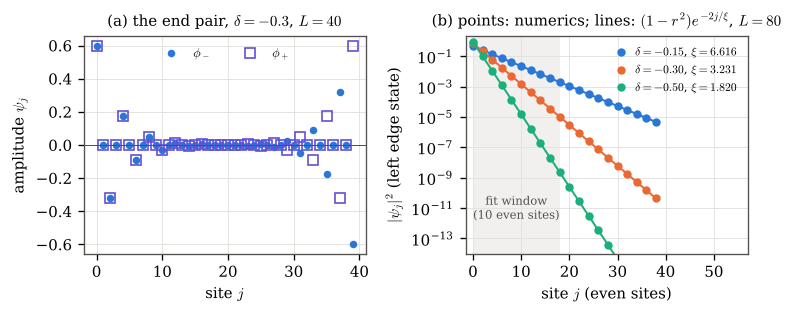

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(6.4, 2.7))

ax = axes[0]
ep = EDGE[(L_EX, DELTA_EX)]
j = np.arange(L_EX)
# phi_-+ are built from psi_L, psi_R (Eq. of Sec. 1.7), so changing L_EX cannot mislabel an unresolved pair
for col, lab, c, mk in [(ep["bonding"], r"$\phi_-$", "#2a78d6", "o"), (ep["antibonding"], r"$\phi_+$", "#6250d6", "s")]:
    ax.plot(j, col, mk, color=c, ms=3.5 if mk == "o" else 6, mfc=c if mk == "o" else "none", label=lab)
ax.axhline(0, color=GRAY, lw=0.6)
ax.set_xlabel("site $j$")
ax.set_ylabel(r"amplitude $\psi_j$")
ax.set_title(rf"(a) the end pair, $\delta={DELTA_EX}$, $L={L_EX}$", fontsize=9)
ax.legend(loc="upper center", fontsize=7.5, ncol=2)

ax = axes[1]
even = np.arange(0, 40, 2)
for delta in sorted({d for d in DELTA_LIST if d < 0}, reverse=True):
    c = COLORS[abs(delta)]
    xi, r = xi_exact(delta), ratio(delta)
    ax.semilogy(even, (1 - r**2) * np.exp(-2 * even / xi), "-", color=c, lw=1.2)
    ax.semilogy(even, EDGE[(L_PROFILE, delta)]["left"][even] ** 2, "o", color=c, ms=4,
                label=rf"$\delta={delta:+.2f}$, $\xi={xi:.3f}$")
ax.axvspan(0, 2 * (N_FIT_LIST[-1] - 1), color=LIGHT, alpha=0.5, lw=0)
ax.text(N_FIT_LIST[-1] - 1, 2e-12, f"fit window\n({N_FIT_LIST[-1]} even sites)", ha="center", fontsize=7, color=GRAY)
ax.set_ylim(1e-14, 2)
ax.set_xlim(-1.5, 57)  # empty strip on the right holds the legend
ax.set_xlabel("site $j$ (even sites)")
ax.set_ylabel(r"$|\psi_j|^2$ (left edge state)")
ax.set_title(rf"(b) points: numerics; lines: $(1-r^2)e^{{-2j/\xi}}$, $L={L_PROFILE}$", fontsize=9)
ax.legend(loc="upper right", fontsize=7, handletextpad=0.2)
fig.tight_layout()
savefig(fig, "step1_edge_states")
plt.show()

### 1.5 End-pair splitting versus $L$

Three routes: dense `eigh` (limited by round-off), an exact 80-digit Sturm bisection (mpmath),
and the analytic leading order $2J_s(1-r^2)e^{-L/\xi}$. The slope of $\ln\Delta E$ against $L$ must be $-1/\xi$.

In [8]:
rows = []
for delta in sorted({d for d in DELTA_LIST if d < 0}):
    for L in sorted(set(L_SCAN) | set(L_LIST)):
        E = np.linalg.eigvalsh(hopping_matrix(L, delta))
        pair = np.sort(E[np.argsort(np.abs(E))[:2]])
        rows.append({"delta": delta, "L": L, "dE eigh": pair[1] - pair[0],
                     "dE exact (Sturm)": splitting_sturm(L, delta), "dE asymptotic": splitting_asym(L, delta)})
split = pd.DataFrame(rows)
split["asym/exact - 1"] = split["dE asymptotic"] / split["dE exact (Sturm)"] - 1
split["eigh/exact - 1"] = split["dE eigh"] / split["dE exact (Sturm)"] - 1
display(split[split.L.isin(L_LIST)])

for delta in sorted({d for d in DELTA_LIST if d < 0}):
    s = split[split.delta == delta]
    check(f"delta={delta:+.2f}: splitting decreases with L", np.all(np.diff(s["dE exact (Sturm)"]) < 0))
    big = s[s.L >= 40]
    slope = np.polyfit(big.L, np.log(big["dE exact (Sturm)"]), 1)[0]
    print(f"    slope of ln(dE) vs L (L >= 40) = {slope:.6f},  -1/xi = {-1 / xi_exact(delta):.6f}")
    check(f"delta={delta:+.2f}: slope = -1/xi", abs(slope * xi_exact(delta) + 1) < 1e-3,
          abs(slope * xi_exact(delta) + 1))
worst = split.loc[split.L >= 40, "asym/exact - 1"].abs().max()
check("asymptotic formula vs exact splitting (L >= 40, tol 1e-4)", worst < 1e-4, worst)

,delta,L,dE eigh,dE exact (Sturm),dE asymptotic,asym/exact - 1,eigh/exact - 1
7,-0.5,40,7.64793e-10,7.64793e-10,7.64793e-10,-1.22125e-15,-4.6062e-12
17,-0.5,80,1.21143e-16,2.1934e-19,2.1934e-19,-2.44249e-15,551.305
27,-0.5,120,9.62591e-17,6.29062e-29,6.29062e-29,-3.33067e-15,1.5302e+12
35,-0.3,40,7.75107e-06,7.75107e-06,7.75107e-06,-2.4522e-10,1.86517e-14
45,-0.3,80,3.25428e-11,3.25428e-11,3.25428e-11,-2.55351e-15,5.28704e-10
55,-0.3,120,8.59915e-16,1.36631e-16,1.36631e-16,-4.10783e-15,5.29371
63,-0.15,40,0.0024713,0.0024713,0.00247118,-4.78292e-05,-2.87548e-14
73,-0.15,80,5.8523e-06,5.8523e-06,5.8523e-06,-5.53637e-10,-4.70735e-14
83,-0.15,120,1.38595e-08,1.38595e-08,1.38595e-08,-4.44089e-16,-1.6831e-13


[pass] delta=-0.50: splitting decreases with L
    slope of ln(dE) vs L (L >= 40) = -0.549306,  -1/xi = -0.549306
[pass] delta=-0.50: slope = -1/xi   [2.22e-16]
[pass] delta=-0.30: splitting decreases with L
    slope of ln(dE) vs L (L >= 40) = -0.309520,  -1/xi = -0.309520
[pass] delta=-0.30: slope = -1/xi   [2.81e-12]
[pass] delta=-0.15: splitting decreases with L
    slope of ln(dE) vs L (L >= 40) = -0.151141,  -1/xi = -0.151140
[pass] delta=-0.15: slope = -1/xi   [1.46e-06]
[pass] asymptotic formula vs exact splitting (L >= 40, tol 1e-4)   [4.78e-05]


saved figures/step1_splitting.pdf


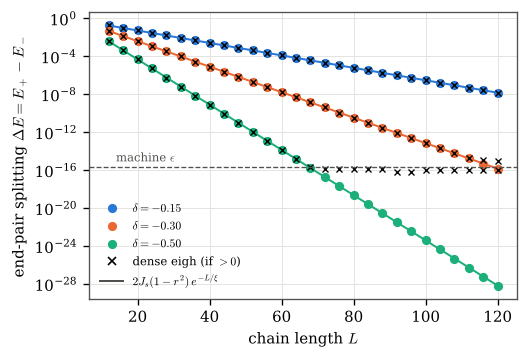

In [9]:
fig, ax = plt.subplots(figsize=(4.6, 3.1))
for delta in sorted({d for d in DELTA_LIST if d < 0}, reverse=True):
    c, s = COLORS[abs(delta)], split[(split.delta == delta) & split.L.isin(L_SCAN)]
    ax.semilogy(s.L, s["dE asymptotic"], "-", color=c, lw=1.2)
    ax.semilogy(s.L, s["dE exact (Sturm)"], "o", color=c, ms=4.5, label=rf"$\delta={delta:+.2f}$")
    ok = s["dE eigh"] > 0
    ax.semilogy(s.L[ok], s["dE eigh"][ok], "x", color="k", ms=4, mew=0.8)
ax.axhline(np.finfo(float).eps, color=GRAY, lw=0.8, ls="--")
ax.text(14, 4e-16, r"machine $\epsilon$", fontsize=7, color=GRAY, va="bottom")
ax.plot([], [], "x", color="k", label="dense eigh (if $>0$)")
ax.plot([], [], "-", color=GRAY, lw=1.2, label=r"$2J_s(1-r^2)\,e^{-L/\xi}$")
ax.set_xlabel("chain length $L$")
ax.set_ylabel(r"end-pair splitting $\Delta E = E_+ - E_-$")
ax.legend(fontsize=7, loc="lower left")
savefig(fig, "step1_splitting")
plt.show()

### 1.6 Bulk bands on a ring

Ring of $M = L/2$ two-site cells, $k = 2\pi m/M$. The spectrum must equal $E_\pm(k)$, the gap must be $4|\delta|$
(when $M$ is even so that $k=\pi$ is allowed) and the bulk addition cost $2|\delta|$. The bands are identical for $\pm\delta$.

In [10]:
rows = []
for L in L_LIST:
    k = 2 * np.pi * np.arange(L // 2) / (L // 2)
    for delta in DELTA_LIST:
        E = np.sort(np.linalg.eigvalsh(hopping_matrix(L, delta, periodic=True)))
        E_bloch = np.sort(np.concatenate(bloch_bands(k, delta)))
        E_flip = np.sort(np.linalg.eigvalsh(hopping_matrix(L, -delta, periodic=True)))
        rows.append({"L": L, "delta": delta, "max|E - E_bloch|": np.max(np.abs(E - E_bloch)),
                     "gap": 2 * E[E > 0].min(), "4|delta|": 4 * abs(delta),
                     "addition cost": E[E > 0].min(), "max|E(delta) - E(-delta)|": np.max(np.abs(E - E_flip))})
ring = pd.DataFrame(rows)
display(ring)

check("ring spectrum = Bloch bands", ring["max|E - E_bloch|"].max() < 1e-12, ring["max|E - E_bloch|"].max())
check("ring gap = 4|delta|", np.max(np.abs(ring.gap - ring["4|delta|"])) < 1e-12, np.max(np.abs(ring.gap - ring["4|delta|"])))
check("bulk addition cost = 2|delta|", np.max(np.abs(ring["addition cost"] - 2 * ring.delta.abs())) < 1e-12)
check("ring spectra identical for +delta and -delta", ring["max|E(delta) - E(-delta)|"].max() < 1e-12)

,L,delta,max|E - E_bloch|,gap,4|delta|,addition cost,max|E(delta) - E(-delta)|
0,40,-0.5,1.77636e-15,2,2,1,2.88658e-15
1,40,-0.3,1.55431e-15,1.2,1.2,0.6,1.9984e-15
2,40,-0.15,1.4988e-15,0.6,0.6,0.3,1.9984e-15
3,40,0.15,1.9984e-15,0.6,0.6,0.3,1.9984e-15
4,40,0.3,1.55431e-15,1.2,1.2,0.6,1.9984e-15
5,40,0.5,1.77636e-15,2,2,1,2.88658e-15
6,80,-0.5,1.77636e-15,2,2,1,5.32907e-15
7,80,-0.3,3.33067e-15,1.2,1.2,0.6,3.10862e-15
8,80,-0.15,2.22045e-15,0.6,0.6,0.3,2.9976e-15
9,80,0.15,2.22045e-15,0.6,0.6,0.3,2.9976e-15


[pass] ring spectrum = Bloch bands   [5.55e-15]
[pass] ring gap = 4|delta|   [1.11e-15]
[pass] bulk addition cost = 2|delta|
[pass] ring spectra identical for +delta and -delta


saved figures/step1_ring_bands.pdf


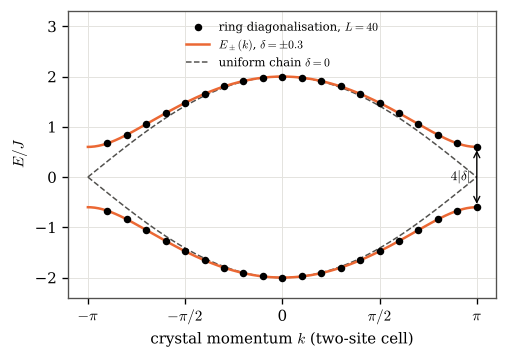

In [11]:
fig, ax = plt.subplots(figsize=(4.6, 3.1))
kk = np.linspace(-np.pi, np.pi, 400)
for band in bloch_bands(kk, 0.0):
    ax.plot(kk, band, "--", color=GRAY, lw=0.9)
for band in bloch_bands(kk, DELTA_EX):
    ax.plot(kk, band, "-", color=COLORS[abs(DELTA_EX)])
# ring eigenvalues, assigned momenta by matching the sorted ring spectrum to the sorted Bloch values
km = 2 * np.pi * np.arange(L_EX // 2) / (L_EX // 2)
km = np.where(km > np.pi, km - 2 * np.pi, km)
order = np.argsort(np.concatenate(bloch_bands(km, DELTA_EX)))
E_ring = np.sort(np.linalg.eigvalsh(hopping_matrix(L_EX, DELTA_EX, periodic=True)))
ax.plot(np.concatenate([km, km])[order], E_ring, "o", color="k", ms=3.5, label=f"ring diagonalisation, $L={L_EX}$")
ax.annotate("", xy=(np.pi, 2 * abs(DELTA_EX)), xytext=(np.pi, -2 * abs(DELTA_EX)),
            arrowprops=dict(arrowstyle="<->", color="k", lw=0.8))
ax.text(np.pi - 0.1, 0, r"$4|\delta|$", ha="right", va="center", fontsize=8)
ax.plot([], [], "-", color=COLORS[abs(DELTA_EX)], label=rf"$E_\pm(k)$, $\delta=\pm{abs(DELTA_EX)}$")
ax.plot([], [], "--", color=GRAY, lw=0.9, label=r"uniform chain $\delta=0$")
ax.set_xticks([-np.pi, -np.pi / 2, 0, np.pi / 2, np.pi], [r"$-\pi$", r"$-\pi/2$", "0", r"$\pi/2$", r"$\pi$"])
ax.set_xlabel("crystal momentum $k$ (two-site cell)")
ax.set_ylabel("$E/J$")
ax.set_ylim(-2.4, 3.3)
ax.legend(fontsize=7, loc="upper center")
savefig(fig, "step1_ring_bands")
plt.show()

### 1.7 State selection

At half filling exactly one of the end pair is occupied. **Convention:** fill the bonding orbital
$\phi_- = (\psi_L - s\,\psi_R)/\sqrt2$ with $s = \mathrm{sgn}\,t = (-1)^{L/2}$ (analytic sign, because the numerical $t$
is pure round-off once the splitting is). With this state:
* $\langle n_j\rangle = 1/2$ on every site (chiral symmetry);
* the edge addition weight is $z_0 = |\phi_+(0)|^2/(1-\langle n_0\rangle) = |\psi_L(0)|^2$ exactly, at every $L$.

$1-r^2$ is only the $L\to\infty$ limit of $z_0$. Later steps must compare with the exact value at their own size (Sec. 1.9).

In [12]:
rows = []
for (L, delta), ep in EDGE.items():
    E, U = ep["E"], ep["U"]
    bulk_filled = [n for n in range(L) if E[n] < 0 and n not in ep["pair"]]
    n0 = np.sum(U[0, bulk_filled] ** 2) + ep["bonding"][0] ** 2
    resolved = abs(split[(split.L == L) & (split.delta == delta)]["eigh/exact - 1"].iloc[0]) < 1e-6
    rows.append({"delta": delta, "L": L, "<n_0>": n0, "z_0": ep["antibonding"][0] ** 2 / (1 - n0),
                 "|psi_L(0)|^2": ep["left"][0] ** 2, "1 - r^2": 1 - ratio(delta) ** 2,
                 "t numeric": ep["t"], "s = (-1)^(L/2)": ep["s"], "splitting resolved by eigh": resolved})
bench = pd.DataFrame(rows).sort_values(["delta", "L"], ascending=[False, True])
display(bench)

res = bench[bench["splitting resolved by eigh"]]
check("sgn(t numeric) = (-1)^(L/2) wherever the splitting is resolved",
      all(np.sign(res["t numeric"]) == res["s = (-1)^(L/2)"]))
check("<n_0> = 1/2", np.max(np.abs(bench["<n_0>"] - 0.5)) < 1e-12, np.max(np.abs(bench["<n_0>"] - 0.5)))
check("z_0 = |psi_L(0)|^2", np.max(np.abs(bench.z_0 - bench["|psi_L(0)|^2"])) < 1e-12)
check("z_0 = 1 - r^2 up to finite size (tol 1e-3)", np.max(np.abs(bench.z_0 - bench["1 - r^2"])) < 1e-3,
      np.max(np.abs(bench.z_0 - bench["1 - r^2"])))

,delta,L,<n_0>,z_0,|psi_L(0)|^2,1 - r^2,t numeric,s = (-1)^(L/2),splitting resolved by eigh
2,-0.15,40,0.5,0.453726,0.453726,0.453686,0.00123565,1,True
5,-0.15,80,0.5,0.453686,0.453686,0.453686,2.92615e-06,1,True
8,-0.15,120,0.5,0.453686,0.453686,0.453686,6.92977e-09,1,True
1,-0.3,40,0.5,0.710059,0.710059,0.710059,3.87553e-06,1,True
4,-0.3,80,0.5,0.710059,0.710059,0.710059,1.62714e-11,1,True
7,-0.3,120,0.5,0.710059,0.710059,0.710059,6.83155e-17,1,False
0,-0.5,40,0.5,0.888889,0.888889,0.888889,3.82396e-10,1,True
3,-0.5,80,0.5,0.888889,0.888889,0.888889,1.0967e-19,1,False
6,-0.5,120,0.5,0.888889,0.888889,0.888889,-3.14531e-29,1,False


[pass] sgn(t numeric) = (-1)^(L/2) wherever the splitting is resolved
[pass] <n_0> = 1/2   [9.99e-16]
[pass] z_0 = |psi_L(0)|^2
[pass] z_0 = 1 - r^2 up to finite size (tol 1e-3)   [3.95e-05]


In [13]:
# Are the raw eigenvectors the bonding and antibonding orbitals? Only where the splitting is resolved.
rows = []
for (L, delta), ep in EDGE.items():
    raw = ep["U"][:, ep["pair"]]
    rows.append({"delta": delta, "L": L, "dE exact (Sturm)": splitting_sturm(L, delta),
                 "raw E_1": ep["E"][ep["pair"][0]], "raw E_2": ep["E"][ep["pair"][1]],
                 "1 - |<raw 1|phi_->|^2": 1 - (raw[:, 0] @ ep["bonding"]) ** 2,
                 "1 - |<raw 2|phi_+>|^2": 1 - (raw[:, 1] @ ep["antibonding"]) ** 2,
                 "raw 1 weight at site 0": raw[0, 0] ** 2, "raw 2 weight at site 0": raw[0, 1] ** 2})
raw_pair = pd.DataFrame(rows).sort_values(["delta", "L"], ascending=[False, True])
display(raw_pair)

clear = raw_pair[raw_pair["dE exact (Sturm)"] > 1e-13]
dev = clear[["1 - |<raw 1|phi_->|^2", "1 - |<raw 2|phi_+>|^2"]].abs().to_numpy().max()
print(f"{len(clear)} of {len(raw_pair)} points have dE > 1e-13; at the others the raw energies and vectors have no reliable labels")
check("raw eigenvectors = constructed phi_-+ where dE > 1e-13", dev < 1e-12, dev)

,delta,L,dE exact (Sturm),raw E_1,raw E_2,1 - |<raw 1|phi_->|^2,1 - |<raw 2|phi_+>|^2,raw 1 weight at site 0,raw 2 weight at site 0
2,-0.15,40,0.0024713,-0.00123565,0.00123565,5.10703e-15,5.10703e-15,0.226863,0.226863
5,-0.15,80,5.8523e-06,-2.92615e-06,2.92615e-06,4.44089e-15,4.44089e-15,0.226843,0.226843
8,-0.15,120,1.38595e-08,-6.92977e-09,6.92977e-09,1.55431e-15,1.33227e-15,0.226843,0.226843
1,-0.3,40,7.75107e-06,-3.87553e-06,3.87553e-06,-2.66454e-15,-1.33227e-15,0.35503,0.35503
4,-0.3,80,3.25428e-11,-1.62708e-11,1.62721e-11,-1.77636e-15,-1.77636e-15,0.35503,0.35503
7,-0.3,120,1.36631e-16,2.74429e-16,4.1106e-16,-4.44089e-16,0,0.35503,0.35503
0,-0.5,40,7.64793e-10,-3.82396e-10,3.82396e-10,8.88178e-16,6.66134e-16,0.444444,0.444444
3,-0.5,80,2.1934e-19,1.3156e-17,1.33754e-17,4.44089e-16,-4.44089e-16,0.444444,0.444444
6,-0.5,120,6.29062e-29,1.1655e-17,1.1655e-17,0.5,0.5,0.888889,0


6 of 9 points have dE > 1e-13; at the others the raw energies and vectors have no reliable labels
[pass] raw eigenvectors = constructed phi_-+ where dE > 1e-13   [5.11e-15]


### 1.8 Lengths with odd $M = L/2$

Every length used above is divisible by 4, so $M$ is even and the sign rule has only been tested with $s = (-1)^{L/2} = +1$.
Here we test $s = -1$ on open chains.
We also test the rings with odd $M$ used in Step 6: $k = \pi$ is not an allowed momentum there, so the gap is $2\min_k E_+(k)$, which is larger than $4|\delta|$.

In [14]:
rows = []
for L in L_ODD_M:
    for delta in [d for d in DELTA_LIST if d < 0]:
        ep = edge_pair(L, delta)
        E, U = ep["E"], ep["U"]
        h = hopping_matrix(L, delta)
        bulk_filled = [n for n in range(L) if E[n] < 0 and n not in ep["pair"]]
        n0 = np.sum(U[0, bulk_filled] ** 2) + ep["bonding"][0] ** 2
        exact = splitting_sturm(L, delta)
        E_vals = np.linalg.eigvalsh(h)
        pair = np.sort(E_vals[np.argsort(np.abs(E_vals))[:2]])
        rows.append({"delta": delta, "L": L, "s = (-1)^(L/2)": ep["s"], "t numeric": ep["t"],
                     "E bonding": ep["bonding"] @ h @ ep["bonding"],
                     "E antibonding": ep["antibonding"] @ h @ ep["antibonding"],
                     "<n_0>": n0, "z_0": ep["antibonding"][0] ** 2 / (1 - n0), "|psi_L(0)|^2": ep["left"][0] ** 2,
                     "dE exact (Sturm)": exact, "asym/exact - 1": splitting_asym(L, delta) / exact - 1,
                     "splitting resolved by eigh": abs((pair[1] - pair[0]) / exact - 1) < 1e-6})
odd = pd.DataFrame(rows).sort_values(["delta", "L"], ascending=[False, True])
display(odd)

res = odd[odd["splitting resolved by eigh"]]
print(f"splitting resolved at {len(res)} of {len(odd)} points")
check("odd M: sgn(t numeric) = (-1)^(L/2) = -1 wherever the splitting is resolved",
      len(res) > 0 and all(np.sign(res["t numeric"]) == res["s = (-1)^(L/2)"]))
check("odd M: bonding orbital lies below antibonding wherever the splitting is resolved",
      all(res["E bonding"] < 0) and all(res["E antibonding"] > 0))
check("odd M: <n_0> = 1/2", np.max(np.abs(odd["<n_0>"] - 0.5)) < 1e-12, np.max(np.abs(odd["<n_0>"] - 0.5)))
check("odd M: z_0 = |psi_L(0)|^2", np.max(np.abs(odd.z_0 - odd["|psi_L(0)|^2"])) < 1e-12,
      np.max(np.abs(odd.z_0 - odd["|psi_L(0)|^2"])))
worst = odd.loc[odd.L >= 40, "asym/exact - 1"].abs().max()
check("odd M: asymptotic formula vs exact splitting (L >= 40, tol 1e-4)", worst < 1e-4, worst)

,delta,L,s = (-1)^(L/2),t numeric,E bonding,E antibonding,<n_0>,z_0,|psi_L(0)|^2,dE exact (Sturm),asym/exact - 1,splitting resolved by eigh
2,-0.15,18,-1,-0.034901,-0.034901,0.034901,0.5,0.46536,0.46536,0.069802,-0.0157508,True
5,-0.15,42,-1,-0.000913289,-0.000913289,0.000913289,0.5,0.453709,0.453709,0.00182658,-2.75191e-05,True
8,-0.15,62,-1,-4.44434e-05,-4.44434e-05,4.44434e-05,0.5,0.453686,0.453686,8.88868e-05,-9.80886e-08,True
11,-0.15,82,-1,-2.16281e-06,-2.16281e-06,2.16281e-06,0.5,0.453686,0.453686,4.32562e-06,-3.10254e-10,True
1,-0.3,18,-1,-0.00351292,-0.00351292,0.00351292,0.5,0.710171,0.710171,0.00702584,-8.83523e-05,True
4,-0.3,42,-1,-2.08683e-06,-2.08683e-06,2.08683e-06,0.5,0.710059,0.710059,4.17365e-06,-7.47293e-11,True
7,-0.3,62,-1,-4.27596e-09,-4.27596e-09,4.27596e-09,0.5,0.710059,0.710059,8.55191e-09,-2.55351e-15,True
10,-0.3,82,-1,-8.76153e-12,-8.76153e-12,8.76153e-12,0.5,0.710059,0.710059,1.75231e-11,-2.77556e-15,True
0,-0.5,18,-1,-6.77404e-05,-6.77404e-05,6.77404e-05,0.5,0.888889,0.888889,0.000135481,-2.03626e-08,True
3,-0.5,42,-1,-1.27465e-10,-1.27465e-10,1.27465e-10,0.5,0.888889,0.888889,2.54931e-10,-1.22125e-15,True


splitting resolved at 10 of 12 points
[pass] odd M: sgn(t numeric) = (-1)^(L/2) = -1 wherever the splitting is resolved
[pass] odd M: bonding orbital lies below antibonding wherever the splitting is resolved
[pass] odd M: <n_0> = 1/2   [8.33e-16]
[pass] odd M: z_0 = |psi_L(0)|^2   [9.99e-16]
[pass] odd M: asymptotic formula vs exact splitting (L >= 40, tol 1e-4)   [2.75e-05]


In [15]:
rows = []
for L in L_RING_ODD:
    k = 2 * np.pi * np.arange(L // 2) / (L // 2)
    for delta in DELTA_LIST:
        E = np.sort(np.linalg.eigvalsh(hopping_matrix(L, delta, periodic=True)))
        Em, Ep = bloch_bands(k, delta)
        rows.append({"L": L, "delta": delta, "max|E - E_bloch|": np.max(np.abs(E - np.sort(np.concatenate([Em, Ep])))),
                     "gap": 2 * E[E > 0].min(), "2 min E_+(k)": 2 * Ep.min(), "4|delta|": 4 * abs(delta)})
ring_odd = pd.DataFrame(rows)
ring_odd["gap / 4|delta|"] = ring_odd.gap / ring_odd["4|delta|"]
display(ring_odd)

check("odd-M ring spectrum = Bloch bands", ring_odd["max|E - E_bloch|"].max() < 1e-12, ring_odd["max|E - E_bloch|"].max())
dev = np.max(np.abs(ring_odd.gap - ring_odd["2 min E_+(k)"]))
check("odd-M ring gap = 2 min E_+(k) over the allowed k", dev < 1e-12, dev)
check("odd-M ring gap > 4|delta| (k = pi is not allowed)", all(ring_odd.gap > ring_odd["4|delta|"]))

,L,delta,max|E - E_bloch|,gap,2 min E_+(k),4|delta|,gap / 4|delta|
0,10,-0.5,1.55431e-15,2.26846,2.26846,2,1.13423
1,10,-0.3,7.77156e-16,1.68237,1.68237,1.2,1.40197
2,10,-0.15,8.88178e-16,1.36143,1.36143,0.6,2.26905
3,10,0.15,8.88178e-16,1.36143,1.36143,0.6,2.26905
4,10,0.3,8.88178e-16,1.68237,1.68237,1.2,1.40197
5,10,0.5,1.33227e-15,2.26846,2.26846,2,1.13423
6,14,-0.5,8.88178e-16,2.14341,2.14341,2,1.0717
7,14,-0.3,1.55431e-15,1.47002,1.47002,1.2,1.22501
8,14,-0.15,8.88178e-16,1.06509,1.06509,0.6,1.77516
9,14,0.15,7.77156e-16,1.06509,1.06509,0.6,1.77516


[pass] odd-M ring spectrum = Bloch bands   [3.11e-15]
[pass] odd-M ring gap = 2 min E_+(k) over the allowed k   [4.44e-15]
[pass] odd-M ring gap > 4|delta| (k = pi is not allowed)


### 1.9 Exact free solution at the sizes used in Steps 2 and 3

The many-body code must be compared with the exact free solution **at the same $L$ and the same boundary conditions**.
$z_0 \to 1-r^2$ and $\xi_W \to \xi$ are $L\to\infty$ limits, and at these sizes they differ from the exact values by far more than the many-body code's accuracy.

`free_benchmark` uses only $L\times L$ matrices. On the open chain the edge line is the empty orbital $\phi_+$ at $\omega=\Delta E/2$, so $W_j = \phi_+(j)^2$. That equals $|\psi_L(j)|^2/2$ on even sites and $|\psi_R(j)|^2/2$ on odd sites, so the odd-site profile belongs to the far edge.
$\xi_W$ is fitted on the even sites $j<L/2$, and the value depends on that choice: a later step using other sites must refit.
$\Delta_+$ comes from the ring of the same $L$, and it is larger on rings with odd $M$.

In [16]:
def free_benchmark(L, delta):
    """Exact V = 0 values at this L for delta < 0: open chain and ring of the same size, no L -> infinity limit."""
    ep = edge_pair(L, delta)
    E, U = ep["E"], ep["U"]
    bulk = np.ones(L, dtype=bool)
    bulk[ep["pair"]] = False
    n = np.sum(U[:, bulk & (E < 0)] ** 2, axis=1) + ep["bonding"] ** 2      # <n_j>, bulk filled + phi_-
    W = ep["antibonding"] ** 2                                              # W_j, only phi_+ in the edge window
    n_fit = len(range(0, L // 2, 2))                                        # even sites j < L/2
    dE = splitting_sturm(L, delta)
    E_ring = np.linalg.eigvalsh(hopping_matrix(L, delta, periodic=True))
    return {"delta": delta, "L": L, "dE": dE, "add_gap": dE / 2, "z0": W[0] / (1 - n[0]), "n_fit": n_fit,
            "xi_W": fit_xi(W, n_fit), "delta_plus": E_ring[E_ring > 0].min(), "lowest_bulk": np.abs(E[bulk]).min(),
            "n": n, "W": W, "left": ep["left"], "right": ep["right"]}


BENCH = {(L, d): free_benchmark(L, d) for L in L_BENCH for d in DELTA_LIST if d < 0}
bench_exact = pd.DataFrame([{k: v for k, v in b.items() if k not in ("n", "W", "left", "right")} for b in BENCH.values()])
bench_exact["limit 1-r^2"] = 1 - bench_exact.delta.map(ratio) ** 2
bench_exact["z0 / limit - 1"] = bench_exact.z0 / bench_exact["limit 1-r^2"] - 1
bench_exact["limit xi"] = bench_exact.delta.map(xi_exact)
bench_exact["xi_W / limit - 1"] = bench_exact.xi_W / bench_exact["limit xi"] - 1
for f in F_BENCH:
    bench_exact[f"lines in window, f={f}"] = [int(b["dE"] / 2 < f * b["delta_plus"]) + int(b["lowest_bulk"] < f * b["delta_plus"])
                                              for b in BENCH.values()]
bench_exact = bench_exact.sort_values(["delta", "L"], ascending=[False, True])
display(bench_exact)

,delta,L,dE,add_gap,z0,n_fit,xi_W,delta_plus,lowest_bulk,limit 1-r^2,z0 / limit - 1,limit xi,xi_W / limit - 1,"lines in window, f=0.6","lines in window, f=0.7","lines in window, f=0.8","lines in window, f=0.9"
2,-0.15,8,0.370413,0.185206,0.573386,2,5.69929,0.3,0.98336,0.453686,0.263838,6.61636,-0.138607,0,1,1,1
5,-0.15,10,0.256519,0.12826,0.528682,3,5.75333,0.680714,0.821612,0.453686,0.165303,6.61636,-0.130439,1,1,1,1
8,-0.15,12,0.182037,0.0910186,0.500999,3,6.16011,0.3,0.708888,0.453686,0.104284,6.61636,-0.0689582,1,1,1,1
11,-0.15,14,0.131149,0.0655746,0.483525,4,6.20461,0.532547,0.6273,0.453686,0.0657691,6.61636,-0.062233,1,1,1,1
14,-0.15,16,0.0953909,0.0476954,0.472416,4,6.39455,0.3,0.566474,0.453686,0.0412847,6.61636,-0.0335247,1,1,1,1
17,-0.15,18,0.069802,0.034901,0.46536,5,6.42117,0.455962,0.520058,0.453686,0.0257304,6.61636,-0.0295014,1,1,1,1
1,-0.3,8,0.158143,0.0790713,0.730911,2,3.16515,0.6,1.04292,0.710059,0.0293657,3.23081,-0.0203232,1,1,1,1
4,-0.3,10,0.0841368,0.0420684,0.717902,3,3.1798,0.841183,0.912084,0.710059,0.0110457,3.23081,-0.0157902,1,1,1,1
7,-0.3,12,0.0451051,0.0225526,0.712894,3,3.21608,0.6,0.828051,0.710059,0.00399222,3.23081,-0.00455959,1,1,1,1
10,-0.3,14,0.0242494,0.0121247,0.71105,4,3.21988,0.735008,0.772011,0.710059,0.00139508,3.23081,-0.00338296,1,1,1,1


In [17]:
dev = max(np.max(np.abs(b["n"] - 0.5)) for b in BENCH.values())
check("finite chain: <n_j> = 1/2 at every site, L = 8-18", dev < 1e-12, dev)
dev = 0.0
for b in BENCH.values():
    expected = np.where(np.arange(b["L"]) % 2 == 0, b["left"] ** 2, b["right"] ** 2) / 2
    dev = max(dev, np.max(np.abs(b["W"] - expected)))
check("finite chain: W_j = |psi_L(j)|^2/2 on even sites, |psi_R(j)|^2/2 on odd sites", dev < 1e-12, dev)
dev = max(abs(b["z0"] - b["left"][0] ** 2) for b in BENCH.values())
check("finite chain: z_0 = |psi_L(0)|^2 at the same L", dev < 1e-12, dev)

dev = 0.0
for (L, d), b in BENCH.items():
    E = np.sort(np.abs(np.linalg.eigvalsh(hopping_matrix(L, d))))
    dev = max(dev, abs(2 * E[0] / b["dE"] - 1))
check("finite chain: Sturm splitting = dense splitting, L = 8-18 (relative)", dev < 1e-9, dev)

dev = 0.0
for (L, d), b in BENCH.items():
    if L % 4 == 0:
        dev = max(dev, abs(b["delta_plus"] - 2 * abs(d)))
    else:
        dev = max(dev, abs(b["delta_plus"] - bloch_bands(np.pi - 2 * np.pi / L, d)[1]))
check("same-size ring: Delta_+ = 2|delta| for even M, E_+(pi - pi/M) for odd M", dev < 1e-12, dev)

check("V = 0 window at f = 0.8: exactly one line, every L and delta", all(bench_exact["lines in window, f=0.8"] == 1))
outside = bench_exact[(bench_exact[[f"lines in window, f={f}" for f in F_BENCH]] != 1).any(axis=1)]
print("points where some window factor does not isolate exactly one line:")
print(outside[["delta", "L", "add_gap", "delta_plus", "lowest_bulk"] + [f"lines in window, f={f}" for f in F_BENCH]].to_string(index=False))

ok = True
for d, s in bench_exact.groupby("delta"):
    gap_z = np.abs(s.z0 - s["limit 1-r^2"]).to_numpy()
    gap_xi = np.abs(s.xi_W - s["limit xi"]).to_numpy()
    ok &= bool(np.all(np.diff(gap_z) < 0)) and gap_xi[-1] < gap_xi[0]
check("finite chain: z_0 approaches 1 - r^2 monotonically and xi_W is closer to xi at L = 18 than at L = 8", ok)

gap = abs(BENCH[(8, -0.30)]["z0"] - (1 - ratio(-0.30) ** 2))
print(f"    delta = -0.30, L = 8: |z_0 - (1 - r^2)| = {gap:.4f}")
check("negative control: 1 - r^2 is not a valid benchmark at L = 8, delta = -0.30 (differs by > 1e-2)", gap > 1e-2, gap)

[pass] finite chain: <n_j> = 1/2 at every site, L = 8-18   [8.88e-16]
[pass] finite chain: W_j = |psi_L(j)|^2/2 on even sites, |psi_R(j)|^2/2 on odd sites   [3.33e-16]
[pass] finite chain: z_0 = |psi_L(0)|^2 at the same L   [7.77e-16]
[pass] finite chain: Sturm splitting = dense splitting, L = 8-18 (relative)   [3.60e-13]
[pass] same-size ring: Delta_+ = 2|delta| for even M, E_+(pi - pi/M) for odd M   [9.99e-16]
[pass] V = 0 window at f = 0.8: exactly one line, every L and delta
points where some window factor does not isolate exactly one line:
 delta  L  add_gap  delta_plus  lowest_bulk  lines in window, f=0.6  lines in window, f=0.7  lines in window, f=0.8  lines in window, f=0.9
 -0.15  8 0.185206         0.3      0.98336                       0                       1                       1                       1
[pass] finite chain: z_0 approaches 1 - r^2 monotonically and xi_W is closer to xi at L = 18 than at L = 8
    delta = -0.30, L = 8: |z_0 - (1 - r^2)| = 0.0209
[pass] ne

### Step 1 summary

In [18]:
step1 = {name: c for name, c in CHECKS.items() if not (name[0] == "S" and name[1].isdigit())}  # later steps use S2, S3, ...
n_pass = sum(c["pass"] for c in step1.values())
print(f"Step 1: {n_pass}/{len(step1)} checks passed")
for name, c in step1.items():
    if not c["pass"]:
        print("  FAILED:", name)

Step 1: 46/46 checks passed


---
## Step 2. Many-body exact diagonalisation

Now $V\neq0$, so the $L\times L$ matrix is no longer enough: $H$ has to be diagonalised on occupation states.
Since $[H,\hat N]=0$ it splits into sectors of dimension $\binom{L}{N}$, and we need $N=L/2$ and $L/2\pm1$.

**Basis.** $|n\rangle=(c_0^\dagger)^{n_0}\cdots(c_{L-1}^\dagger)^{n_{L-1}}|0\rangle\leftrightarrow s=\sum_j n_j2^j$.

**Sign rule.** $c_j^\dagger$ and $c_j$ contribute $(-1)^{\sum_{l<j}n_l}$. For $c_a^\dagger c_b$, annihilate at $b$ first, then create at $a$ on the intermediate state.
Every open-chain hop then has sign $+1$. The closing bond of a ring has sign $(-1)^{N-1}$.

**Trust.** $H(\delta,V)=H_{\rm hop}(\delta)+V\,H_{\rm int}$ is linear in $V$, and $H_{\rm int}$ does not depend on $\delta$. So the matrix is right if $H_{\rm hop}$ is right at $V=0$ (2.3, 2.4) and $H_{\rm int}$ is right at one $V\neq0$ (2.6). Whether the eigenpairs are right is a separate question (2.7).

Derivations are in `report.tex` (Sec. 3) and `summary/step2.md`.

In [19]:
# ---- Step 2 parameters (edit these) ----
from functools import lru_cache
from itertools import combinations
from math import comb
import json
import platform
import sys
import time

import scipy
import scipy.sparse as sp
from scipy.optimize import root
from scipy.sparse.linalg import eigsh

L_DENSE = [6, 8, 10]                  # whole matrix diagonalised (guide item 2)
L_GRID = [8, 12, 16, 18]              # first interacting grid, run in this order
L_PARITY = [10, 14]                   # coarse V only: same-parity pairs for the size trend (Sec. 2.11)
DELTA_GRID = [-0.30, 0.30]
V_COARSE = [0.0, 0.5, 1.0, 2.0, 3.0]
V_STEP = 0.25                         # refinement step where something changes (guide)
K_N, K_PM = 6, 4                      # levels recorded in sector N and in N +- 1
K_EXTRA = 2                           # extra levels computed so a degenerate cluster is not cut at the top
RES_TOL_SMALL, RES_TOL_PROD = 1e-10, 1e-9
LANCZOS_SEED, LANCZOS_NCV = 1234, 40
DENSE_MAX_DIM = comb(10, 5)           # L <= 10 dense, larger sizes Lanczos (guide item 2)
ETA_DEGENERATE = 1e-8                 # levels closer than this form one cluster (Sec. 2.8)
DATA_DIR = Path("data")
DATA_DIR.mkdir(exist_ok=True)

### 2.1 Functions

In [20]:
@lru_cache(maxsize=None)
def sector_basis(L, N):
    """Sorted integers s = sum_j n_j 2^j with exactly N occupied sites (cached, read-only)."""
    basis = np.array(sorted(sum(1 << j for j in occ) for occ in combinations(range(L), N)), dtype=np.int64)
    basis.setflags(write=False)
    return basis


def occupations(basis, L):
    """Matrix of n_j (rows: states, columns: sites)."""
    return (basis[:, None] >> np.arange(L)) & 1


def find(basis, states):
    """Index of each state in the sorted basis; raises if a state is outside the sector."""
    idx = np.minimum(np.searchsorted(basis, states), len(basis) - 1)
    if np.any(basis[idx] != states):
        raise ValueError(f"state left the {len(basis)}-dimensional sector: particle number not conserved")
    return idx


def jw_sign(states, j):
    """(-1)^(number of occupied sites l < j) for each state."""
    return 1 - 2 * (np.bitwise_count(states & ((1 << j) - 1)).astype(np.int64) & 1)


def hop(states, a, b):
    """c_a^dag c_b on states with n_b = 1, n_a = 0: annihilate at b, then create at a on the intermediate state."""
    mid = states ^ (1 << b)
    return mid | (1 << a), jw_sign(states, b) * jw_sign(mid, a)


def interaction_diagonal(basis, L, periodic=False):
    """sum_j (n_j - 1/2)(n_{j+1} - 1/2) on each basis state."""
    x = occupations(basis, L) - 0.5
    total = np.sum(x[:, :-1] * x[:, 1:], axis=1)
    return total + x[:, -1] * x[:, 0] if periodic else total


def hamiltonian(L, N, delta, V, periodic=False, closing_sign=True):
    """Eq. (A.1) in sector N as a CSR matrix. closing_sign=False removes the ring's fermion sign (negative control)."""
    basis = sector_basis(L, N)
    rows, cols, vals = [], [], []
    for j, Jj in enumerate(bonds(L, delta, periodic)):
        k = (j + 1) % L
        for a, b in ((j, k), (k, j)):  # two directions built separately, so Hermiticity is a real test
            col = np.flatnonzero(((basis >> b) & 1 == 1) & ((basis >> a) & 1 == 0))
            target, sign = hop(basis[col], a, b)
            if k == 0 and not closing_sign:
                sign = np.ones_like(sign)
            rows.append(find(basis, target))
            cols.append(col)
            vals.append(-Jj * sign)
    H = sp.csr_matrix((np.concatenate(vals), (np.concatenate(rows), np.concatenate(cols))), shape=(len(basis),) * 2)
    return (H + sp.diags(V * interaction_diagonal(basis, L, periodic), format="csr")).tocsr()


def c_ann(L, N, j, string=True):
    """c_j as a sparse map from sector N to N - 1. string=False removes the sign string (negative control)."""
    src, dst = sector_basis(L, N), sector_basis(L, N - 1)
    col = np.flatnonzero((src >> j) & 1)
    sign = jw_sign(src[col], j) if string else np.ones(len(col), dtype=np.int64)
    return sp.csr_matrix((sign.astype(float), (find(dst, src[col] ^ (1 << j)), col)), shape=(len(dst), len(src)))


def c_dag(L, N, j):
    """c_j^dag as a sparse map from sector N to N + 1."""
    src, dst = sector_basis(L, N), sector_basis(L, N + 1)
    col = np.flatnonzero(((src >> j) & 1) == 0)
    return sp.csr_matrix((jw_sign(src[col], j).astype(float), (find(dst, src[col] | (1 << j)), col)),
                         shape=(len(dst), len(src)))


def hamiltonian_from_operators(L, N, delta, V, periodic=False):
    """Eq. (A.1) written literally as products of c_j and c_j^dag: a slow second route to hamiltonian()."""
    ann, cre = [c_ann(L, N, j) for j in range(L)], [c_dag(L, N - 1, j) for j in range(L)]
    x = [cre[j] @ ann[j] - 0.5 * sp.identity(comb(L, N), format="csr") for j in range(L)]
    H = sp.csr_matrix((comb(L, N),) * 2)
    for j, Jj in enumerate(bonds(L, delta, periodic)):
        k = (j + 1) % L
        H = H - Jj * (cre[j] @ ann[k] + cre[k] @ ann[j]) + V * x[j] @ x[k]
    return H.tocsr()

In [21]:
PAULI = {"I": sp.identity(2, format="csr", dtype=complex),
         "X": sp.csr_matrix([[0, 1], [1, 0]], dtype=complex),
         "Y": sp.csr_matrix([[0, -1j], [1j, 0]], dtype=complex),
         "Z": sp.csr_matrix([[1, 0], [0, -1]], dtype=complex)}


def pauli_string(L, ops):
    """Kronecker product of {site: Pauli letter}; the rightmost factor is site 0, so site j is bit j."""
    out = sp.identity(1, format="csr", dtype=complex)
    for j in reversed(range(L)):
        out = sp.kron(out, PAULI[ops.get(j, "I")], format="csr")
    return out


def hamiltonian_jw(L, delta, V, periodic=False):
    """Eq. (A.4) on all 2^L states. A ring's closing bond carries the parity string of the sites in between."""
    H = sp.csr_matrix((2**L, 2**L), dtype=complex)
    for j, Jj in enumerate(bonds(L, delta, periodic)):
        k = (j + 1) % L
        string = {} if k == j + 1 else {l: "Z" for l in range(1, L - 1)}
        H = H - 0.5 * Jj * (pauli_string(L, {**string, j: "X", k: "X"}) + pauli_string(L, {**string, j: "Y", k: "Y"}))
        H = H + 0.25 * V * pauli_string(L, {j: "Z", k: "Z"})
    if abs(H.imag).max() > 0:
        raise ValueError("Jordan-Wigner Hamiltonian came out complex")
    out = H.real.tocsr()
    out.eliminate_zeros()
    return out

In [22]:
def lowest(H, k, seed=LANCZOS_SEED):
    """k lowest eigenpairs (ascending) and residuals ||H psi - E psi||: dense up to DENSE_MAX_DIM, Lanczos above."""
    dim = H.shape[0]
    if dim <= DENSE_MAX_DIM:
        E, U = np.linalg.eigh(H.toarray())
        E, U = E[:k], U[:, :k]
    else:
        v0 = np.random.default_rng(seed).standard_normal(dim)
        E, U = eigsh(H, k=k, which="SA", tol=0, v0=v0, ncv=max(LANCZOS_NCV, 2 * k + 1))
        order = np.argsort(E)
        E, U = E[order], U[:, order]
    return E, U, np.linalg.norm(H @ U - U * E, axis=0)


def free_levels(h, N):
    """All many-body levels at V = 0: sums of N distinct one-particle energies, ascending."""
    eps = np.linalg.eigvalsh(h)
    return np.sort([eps[list(occ)].sum() for occ in combinations(range(len(eps)), N)])


def filled_correlations(L, delta):
    """Step 1 matrix <c_i^dag c_j> at half filling: filled bulk orbitals, plus the bonding orbital for delta < 0."""
    if delta > 0:
        phi = np.linalg.eigh(hopping_matrix(L, delta))[1][:, :L // 2]
        return phi @ phi.T
    ep = edge_pair(L, delta)
    bulk = ep["U"][:, [n for n in range(L) if ep["E"][n] < 0 and n not in ep["pair"]]]
    return bulk @ bulk.T + np.outer(ep["bonding"], ep["bonding"])


def corr_matrix(psi, L, N, string=True):
    """<c_i^dag c_j> = (c_i psi) . (c_j psi)."""
    cpsi = np.column_stack([c_ann(L, N, j, string=string) @ psi for j in range(L)])
    return cpsi.T @ cpsi


def densities(psi, L, N):
    """<n_j> from the occupation bits."""
    return occupations(sector_basis(L, N), L).T @ psi**2


def energy_from_correlators(psi, L, N, delta, V, periodic=False):
    """<psi|H|psi> from <c_j^dag c_k> and ||c_k c_j psi||^2 only; never calls hamiltonian()."""
    C = corr_matrix(psi, L, N)
    total = 0.0
    for j, Jj in enumerate(bonds(L, delta, periodic)):
        k = (j + 1) % L
        nn = np.sum((c_ann(L, N - 1, k) @ (c_ann(L, N, j) @ psi)) ** 2)
        total += -2 * Jj * C[j, k] + V * (nn - 0.5 * C[j, j] - 0.5 * C[k, k] + 0.25)
    return total


def apply_C(psi, L, N):
    """C: c_j -> (-1)^j c_j^dag, i.e. prod_j X_j: bit complement with sign +1. Maps sector N to L - N."""
    out = np.zeros_like(psi)
    out[find(sector_basis(L, L - N), sector_basis(L, N) ^ ((1 << L) - 1))] = psi
    return out


def apply_R(psi, L, N):
    """R: c_j -> c_{L-1-j}: bit reversal times (-1)^(N(N-1)/2), the sign of reordering N creation operators."""
    basis = sector_basis(L, N)
    out = np.zeros_like(psi)
    out[find(basis, occupations(basis, L) @ (1 << np.arange(L - 1, -1, -1)))] = (-1) ** (N * (N - 1) // 2) * psi
    return out


def label_levels(E, U, ops):
    """Diagonalise the symmetry ops inside each near-degenerate cluster; return rotated U, labels (+-1 or nan), cluster sizes."""
    U = U.copy()
    edges = np.r_[0, np.flatnonzero(np.diff(E) > ETA_DEGENERATE) + 1, len(E)]
    sizes = np.zeros(len(E), dtype=int)
    for a, b in zip(edges[:-1], edges[1:]):
        sizes[a:b] = b - a
        if b - a > 1:
            block = U[:, a:b]
            mix = sum(w * block.T @ np.column_stack([op(v) for v in block.T])
                      for w, op in zip((1.0, np.sqrt(2.0)), ops.values()))  # sqrt(2): all label pairs distinct
            U[:, a:b] = block @ np.linalg.eigh(0.5 * (mix + mix.T))[1]
    labels = {}
    for name, op in ops.items():
        values = np.array([v @ op(v) for v in U.T])
        labels[name] = np.where(np.abs(np.abs(values) - 1) < 1e-6, np.round(values), np.nan)
    return U, labels, sizes


def select_ground_state(E, U, L, N):
    """State-selection rule at half filling: the lowest vector, or the unique C = +1 vector of a near-degenerate cluster."""
    size = int(np.sum(E - E[0] < ETA_DEGENERATE))
    if size == 1:
        psi, choice = U[:, 0], "lowest, PF-positive, C=+1"
    else:
        block = U[:, :size]
        C_block = block.T @ np.column_stack([apply_C(v, L, N) for v in block.T])
        vals, vecs = np.linalg.eigh(0.5 * (C_block + C_block.T))
        plus = np.flatnonzero(vals > 0.5)
        if len(plus) != 1:
            raise ValueError(f"cluster of {size} has {len(plus)} C = +1 states: the rule does not fix the state")
        psi, choice = block @ vecs[:, plus[0]], f"cluster of {size}, C-projected"
    return psi * np.sign(psi.sum()), choice


def half_filled_state(L, delta, V):
    """Selected half-filled ground state of the open chain."""
    E, U, _ = lowest(hamiltonian(L, L // 2, delta, V), K_N + K_EXTRA)
    return select_ground_state(E, U, L, L // 2)[0]

### 2.2 Is the matrix really Eq. (A.1)? Fermion algebra and Jordan–Wigner

The anticommutators are the definition of a fermion and do not involve $H$ (A4). If they hold, Eq. (A.1) written as a literal product of $c$ and $c^\dagger$ is correct by construction, and `hamiltonian()` must equal it (A5). Jordan–Wigner, Eq. (A.4), is a second implementation on all $2^L$ states (D1–D2).

In [23]:
SECTORS = [(L, L // 2 + off) for L in L_DENSE for off in (0, 1, -1)]
POINTS = [(d, V) for d in DELTA_GRID for V in V_COARSE]
BOTH_BC = (False, True)

dev = max(abs(H - H.T).max() for L, N in SECTORS for d, V in POINTS for pbc in BOTH_BC
          for H in [hamiltonian(L, N, d, V, pbc)])
check("S2 A1: H symmetric in N, N +- 1, open and ring (two hop directions built separately)", dev == 0, dev)

try:
    find(sector_basis(6, 3), np.array([0b001111]))
    rejected = False
except ValueError:
    rejected = True
check("S2 A2: a state with the wrong particle number is rejected at construction", rejected)

dev = 0
for L in L_DENSE[:2]:
    for d, V in POINTS:
        for pbc in BOTH_BC:
            coo = hamiltonian_jw(L, d, V, pbc).tocoo()
            dev = max(dev, np.abs(np.bitwise_count(coo.row).astype(int) - np.bitwise_count(coo.col).astype(int)).max())
check("S2 A3: Jordan-Wigner H conserves N on all 2^L states", dev == 0, float(dev))

check("S2 A4: sector sizes = binom(L, N), sorted, N bits set (12870 at L=16, 48620 at L=18)",
      all(len(b) == comb(L, N) and np.all(np.diff(b) > 0) and np.all(np.bitwise_count(b) == N)
          for L in range(2, 19, 2) for N in (L // 2 - 1, L // 2, L // 2 + 1) for b in [sector_basis(L, N)])
      and comb(16, 8) == 12870 and comb(18, 9) == 48620)

dev = 0.0
for L in L_DENSE[:2]:
    for N in range(1, L):
        for i in range(L):
            for j in range(L):
                mixed = c_ann(L, N + 1, i) @ c_dag(L, N, j) + c_dag(L, N - 1, j) @ c_ann(L, N, i)
                dev = max(dev, abs(mixed - (i == j) * sp.identity(comb(L, N), format="csr")).max())
    for N in range(2, L + 1):
        for i in range(L):
            for j in range(L):
                dev = max(dev, abs(c_ann(L, N - 1, i) @ c_ann(L, N, j) + c_ann(L, N - 1, j) @ c_ann(L, N, i)).max())
check("S2 A5: {c_i, c_j^dag} = delta_ij and {c_i, c_j} = 0, L = 6, 8, all N", dev == 0, float(dev))

dev = max(abs(hamiltonian(L, N, d, V, pbc) - hamiltonian_from_operators(L, N, d, V, pbc)).max()
          for L in L_DENSE[:2] for N in range(1, L) for d, V in POINTS for pbc in BOTH_BC)
check("S2 A6: hamiltonian() = Eq. (A.1) as a literal product of c, c^dag, all N, open and ring", dev < 1e-13, dev)

dev_block, dev_spec = 0.0, 0.0
for L in L_DENSE[:2]:
    for d, V in POINTS:
        for pbc in BOTH_BC:
            H_jw = hamiltonian_jw(L, d, V, pbc)
            levels = []
            for N in range(L + 1):
                H = hamiltonian(L, N, d, V, pbc)
                b = sector_basis(L, N)
                dev_block = max(dev_block, abs(H_jw[b][:, b] - H).max())
                levels.append(np.linalg.eigvalsh(H.toarray()))
            dev_spec = max(dev_spec, np.max(np.abs(np.linalg.eigvalsh(H_jw.toarray()) - np.sort(np.concatenate(levels)))))
check("S2 D1: Jordan-Wigner fixed-N blocks = occupation matrices, L = 6, 8, all N, open and ring", dev_block < 1e-13, dev_block)
check("S2 D2: Jordan-Wigner full spectrum = union of all sector spectra", dev_spec < 1e-12, dev_spec)

[pass] S2 A1: H symmetric in N, N +- 1, open and ring (two hop directions built separately)   [0.00e+00]
[pass] S2 A2: a state with the wrong particle number is rejected at construction


[pass] S2 A3: Jordan-Wigner H conserves N on all 2^L states   [0.00e+00]
[pass] S2 A4: sector sizes = binom(L, N), sorted, N bits set (12870 at L=16, 48620 at L=18)


[pass] S2 A5: {c_i, c_j^dag} = delta_ij and {c_i, c_j} = 0, L = 6, 8, all N   [0.00e+00]


[pass] S2 A6: hamiltonian() = Eq. (A.1) as a literal product of c, c^dag, all N, open and ring   [0.00e+00]


[pass] S2 D1: Jordan-Wigner fixed-N blocks = occupation matrices, L = 6, 8, all N, open and ring   [0.00e+00]
[pass] S2 D2: Jordan-Wigner full spectrum = union of all sector spectra   [3.73e-14]


### 2.3 $V=0$: Step 1 as an acceptance test

At $V=0$ every many-body number follows from Step 1's $h$: every level is a sum of $N$ one-particle energies, the neutral gap is the end-pair splitting $\Delta E$ and the addition gap is $\Delta E/2$ for $\delta<0$.
These tests use Step 1's `hopping_matrix`, `edge_pair` and the 80-digit `splitting_sturm`.
C2 and C4 are the ones that see the fermion sign string, and C2n shows that C2 can fail: without the string, the correlator is wrong beyond nearest neighbours.

**How accurate is a vector?** A residual $\|r\|$ only bounds the eigenvector error by $\|r\|/\text{gap}$ (Davis–Kahan), and an observable shifts by up to $2\|r\|/\text{gap}$. With $\delta<0$ the nearest level is the end partner, so this limits Lanczos correlators to about $10^{-11}$ at $L=18$, even with $\|r\|\approx10^{-13}$. The partner has $C=-1$, so projecting onto $C=+1$ removes that error. C2 and C2a test this explanation.

In [24]:
dev = 0.0
for L, N in SECTORS:
    for d in DELTA_GRID:
        for pbc in BOTH_BC:
            spec = np.linalg.eigvalsh(hamiltonian(L, N, d, 0.0, pbc).toarray())
            dev = max(dev, np.max(np.abs(spec - free_levels(hopping_matrix(L, d, pbc), N))))
check("S2 C1: V = 0, L = 6, 8, 10: whole spectrum = sums of N one-particle energies, open and ring", dev < 1e-12, dev)

dev = 0.0
for L in (12, 14, 16, 18):
    for N in (L // 2, L // 2 + 1, L // 2 - 1):
        for d in DELTA_GRID:
            E = lowest(hamiltonian(L, N, d, 0.0), K_N + K_EXTRA)[0]
            dev = max(dev, np.max(np.abs(E - free_levels(hopping_matrix(L, d), N)[:K_N + K_EXTRA])))
check("S2 C1b: V = 0, L = 12-18: Lanczos finds the lowest levels with their exact multiplicities", dev < 1e-11, dev)

rows = []
for L in range(6, 19, 2):
    N = L // 2
    for d in DELTA_GRID:
        E, U, res = lowest(hamiltonian(L, N, d, 0.0), K_N + K_EXTRA)
        psi = select_ground_state(E, U, L, N)[0]
        projected = psi + apply_C(psi, L, N)
        projected /= np.linalg.norm(projected)
        rows.append({"L": L, "delta": d, "max|C - C_filled|": np.max(np.abs(corr_matrix(psi, L, N) - filled_correlations(L, d))),
                     "2 res/gap": 2 * res[0] / (E[1] - E[0]),
                     "same, after C projection": np.max(np.abs(corr_matrix(projected, L, N) - filled_correlations(L, d)))})
corr = pd.DataFrame(rows)
display(corr)
dev = corr["same, after C projection"].max()
check("S2 C2: V = 0: <c_i^dag c_j> = Step 1 filled-orbital matrix, all i, j, L = 6-18 (bonding orbital for delta < 0), C-projected state",
      dev < 1e-12, dev)
worst = (corr["max|C - C_filled|"] / (corr["2 res/gap"] + 1e-13)).max()
check("S2 C2a: same for the raw vector, within the Davis-Kahan bound 2 res/gap (plus a 1e-13 round-off floor)", worst < 1, worst)

psi = half_filled_state(12, -0.30, 0.0)
diff = np.abs(corr_matrix(psi, 12, 6, string=False) - corr_matrix(psi, 12, 6))
near, far = np.max(np.diag(diff, 1)), max(np.max(np.diag(diff, m)) for m in range(2, 12))
print(f"    without the string: adjacent sites off by {near:.1e}, |i - j| >= 2 off by {far:.3f}")
check("S2 C2n: negative control: dropping the string leaves adjacent correlators but breaks |i - j| >= 2",
      near < 1e-12 and far > 1e-2, far)

rows = []
for L in range(8, 19, 2):
    N, d = L // 2, -0.30
    E_N, E_p = lowest(hamiltonian(L, N, d, 0.0), 4)[0], lowest(hamiltonian(L, N + 1, d, 0.0), 2)[0]
    exact = splitting_sturm(L, d)
    rows.append({"L": L, "dE exact (Sturm)": exact, "neutral gap": E_N[1] - E_N[0], "addition gap": E_p[0] - E_N[0],
                 "dev neutral": abs(E_N[1] - E_N[0] - exact), "dev addition": abs(E_p[0] - E_N[0] - exact / 2)})
gaps0 = pd.DataFrame(rows)
display(gaps0)
dev = gaps0[["dev neutral", "dev addition"]].to_numpy().max()
check("S2 C3: V = 0, delta = -0.30: neutral gap = dE and addition gap = dE/2 (80-digit Step 1 splitting)", dev < 1e-10, dev)

dev_w = 0.0
rows = []
for L in (8, 10, 12):
    N = L // 2
    for d in DELTA_GRID:
        psi = half_filled_state(L, d, 0.0)
        phi_N = edge_pair(L, d)["antibonding"] if d < 0 else np.linalg.eigh(hopping_matrix(L, d))[1][:, N]
        ground_p = lowest(hamiltonian(L, N + 1, d, 0.0), 2)[1][:, 0]
        weight = np.array([(ground_p @ (c_dag(L, N, j) @ psi)) ** 2 for j in range(L)])
        dev_w = max(dev_w, np.max(np.abs(weight - phi_N**2)))
        rows.append({"L": L, "delta": d, "w_0": weight[0], "z_0 = w_0/(1-<n_0>)": weight[0] / (1 - densities(psi, L, N)[0]),
                     "exact |psi_L(0)|^2, same L (delta < 0)": edge_pair(L, d)["left"][0] ** 2 if d < 0 else np.nan})
display(pd.DataFrame(rows))
print(f"    benchmark: the exact free value at the same L; 1 - r^2 = {1 - ratio(-0.30) ** 2:.4f} is only its L -> infinity limit")
check("S2 C4: V = 0: |<0,N+1|c_j^dag|Omega>|^2 = |phi_N(j)|^2, the lowest empty orbital, all j", dev_w < 1e-12, dev_w)

dev = 0.0
for L in L_DENSE[1:]:
    N = L // 2
    for d, V in POINTS:
        psi = half_filled_state(L, d, V)
        vecs = np.linalg.eigh(hamiltonian(L, N + 1, d, V).toarray())[1]
        total = np.array([np.sum((vecs.T @ (c_dag(L, N, j) @ psi)) ** 2) for j in range(L)])
        dev = max(dev, np.max(np.abs(total - (1 - densities(psi, L, N)))))
check("S2 C5: sum rule sum_m w_jm = 1 - <n_j>, whole (N+1) spectrum, L = 8, 10, every V", dev < 1e-12, dev)

[pass] S2 C1: V = 0, L = 6, 8, 10: whole spectrum = sums of N one-particle energies, open and ring   [3.11e-14]


[pass] S2 C1b: V = 0, L = 12-18: Lanczos finds the lowest levels with their exact multiplicities   [8.17e-14]


,L,delta,max|C - C_filled|,2 res/gap,"same, after C projection"
0,6,-0.3,1.22125e-15,2.62716e-14,6.10623e-16
1,6,0.3,7.21645e-16,6.71978e-15,7.21645e-16
2,8,-0.3,1.07692e-14,6.54114e-14,6.10623e-16
3,8,0.3,4.996e-16,1.70105e-14,4.44089e-16
4,10,-0.3,1.13243e-14,2.17251e-13,8.88178e-16
5,10,0.3,9.4369e-16,9.09572e-15,2.28327e-16
6,12,-0.3,5.28466e-14,4.02517e-13,1.02696e-15
7,12,0.3,1.27676e-15,1.25868e-14,6.66134e-16
8,14,-0.3,1.41553e-13,8.32683e-13,9.50628e-16
9,14,0.3,2.10942e-15,2.47771e-14,3.88578e-16


[pass] S2 C2: V = 0: <c_i^dag c_j> = Step 1 filled-orbital matrix, all i, j, L = 6-18 (bonding orbital for delta < 0), C-projected state   [1.46e-15]
[pass] S2 C2a: same for the raw vector, within the Davis-Kahan bound 2 res/gap (plus a 1e-13 round-off floor)   [3.28e-01]
    without the string: adjacent sites off by 0.0e+00, |i - j| >= 2 off by 0.682
[pass] S2 C2n: negative control: dropping the string leaves adjacent correlators but breaks |i - j| >= 2   [6.82e-01]


,L,dE exact (Sturm),neutral gap,addition gap,dev neutral,dev addition
0,8,0.158143,0.158143,0.0790713,1.94289e-16,2.76168e-15
1,10,0.0841368,0.0841368,0.0420684,5.55112e-16,1.05471e-15
2,12,0.0451051,0.0451051,0.0225526,5.64132e-15,1.52552e-14
3,14,0.0242494,0.0242494,0.0121247,3.48194e-14,1.63411e-14
4,16,0.0130504,0.0130504,0.00652518,3.06005e-15,4.8208e-14
5,18,0.00702584,0.00702584,0.00351292,3.54838e-15,6.21508e-15


[pass] S2 C3: V = 0, delta = -0.30: neutral gap = dE and addition gap = dE/2 (80-digit Step 1 splitting)   [4.82e-14]


,L,delta,w_0,z_0 = w_0/(1-<n_0>),"exact |psi_L(0)|^2, same L (delta < 0)"
0,8,-0.3,0.365455,0.730911,0.730911
1,8,0.3,0.130258,0.260515,NaN
2,10,-0.3,0.358951,0.717902,0.717902
3,10,0.3,0.0899872,0.179974,NaN
4,12,-0.3,0.356447,0.712894,0.712894
5,12,0.3,0.064552,0.129104,NaN


    benchmark: the exact free value at the same L; 1 - r^2 = 0.7101 is only its L -> infinity limit
[pass] S2 C4: V = 0: |<0,N+1|c_j^dag|Omega>|^2 = |phi_N(j)|^2, the lowest empty orbital, all j   [5.20e-14]
[pass] S2 C5: sum rule sum_m w_jm = 1 - <n_j>, whole (N+1) spectrum, L = 8, 10, every V   [1.89e-15]


### 2.4 The bond that closes a ring

The closing hop moves a particle past the other $N-1$, so its sign is $(-1)^{N-1}$. This is $+1$ for odd $N$, so a test in an odd-$N$ sector cannot catch a missing sign. The negative control E2 removes the sign and must fail for even $N$ only.

In [25]:
def ring_gap(L, delta, V):
    """Bulk threshold Delta_+ = E_0^{N+1} - E_0^N on a ring, with the lowest levels and residuals of both sectors."""
    E_N, _, res_N = lowest(hamiltonian(L, L // 2, delta, V, periodic=True), K_PM)
    E_p, _, res_p = lowest(hamiltonian(L, L // 2 + 1, delta, V, periodic=True), K_PM)
    return {"E_N": E_N, "res_N": res_N, "E_p": E_p, "res_p": res_p, "delta_plus": E_p[0] - E_N[0]}


dev = 0.0
rows = []
for L in (8, 10):
    for N in range(1, L):
        for d in DELTA_GRID:
            exact = free_levels(hopping_matrix(L, d, True), N)[0]
            right = lowest(hamiltonian(L, N, d, 0.0, True), 1)[0][0]
            wrong = lowest(hamiltonian(L, N, d, 0.0, True, closing_sign=False), 1)[0][0]
            rows.append({"L": L, "N": N, "delta": d, "with sign": abs(right - exact), "without sign": abs(wrong - exact)})
ring_sign = pd.DataFrame(rows)
check("S2 E1: ring, V = 0: E_0 = free-fermion sum for every N, even and odd", ring_sign["with sign"].max() < 1e-12,
      ring_sign["with sign"].max())
even, odd = ring_sign[ring_sign.N % 2 == 0], ring_sign[ring_sign.N % 2 == 1]
print(f"    without the closing sign: even N off by at least {even['without sign'].min():.3f}, odd N off by at most {odd['without sign'].max():.1e}")
check("S2 E2: negative control: without the closing sign E1 fails for every even N and no odd N",
      even["without sign"].min() > 1e-3 and odd["without sign"].max() < 1e-12, even["without sign"].min())

dev_even, dev_odd = 0.0, 0.0
for d in DELTA_GRID:
    for L in (8, 12, 16):
        dev_even = max(dev_even, abs(ring_gap(L, d, 0.0)["delta_plus"] - 2 * abs(d)))
    for L in (10, 14, 18):
        dev_odd = max(dev_odd, abs(ring_gap(L, d, 0.0)["delta_plus"] - bloch_bands(np.pi - 2 * np.pi / L, d)[1]))
check("S2 E3: ring, V = 0: Delta_+ = 2|delta| for even M", dev_even < 1e-11, dev_even)
check("S2 E4: ring, V = 0: Delta_+ = E_+(pi - pi/M) for odd M", dev_odd < 1e-11, dev_odd)

[pass] S2 E1: ring, V = 0: E_0 = free-fermion sum for every N, even and odd   [6.22e-15]
    without the closing sign: even N off by at least 0.061, odd N off by at most 3.6e-15
[pass] S2 E2: negative control: without the closing sign E1 fails for every even N and no odd N   [6.10e-02]


[pass] S2 E3: ring, V = 0: Delta_+ = 2|delta| for even M   [1.92e-14]
[pass] S2 E4: ring, V = 0: Delta_+ = E_+(pi - pi/M) for odd M   [5.41e-14]


### 2.5 Exact symmetries

* $C$: $c_j\to(-1)^jc_j^\dagger$. It maps $n_j\to1-n_j$, preserves every hopping term and every $(n_j-\tfrac12)(n_{j+1}-\tfrac12)$, and maps $N\to L-N$. So spectrum$(N+1)=$ spectrum$(N-1)$ at every $V$, and a non-degenerate half-filled state has $\langle n_j\rangle=\tfrac12$ exactly at every $V$.
* $R$: $c_j\to c_{L-1-j}$. Since $J_{L-2-j}=J_j$ for even $L$, it commutes with the open-chain $H$.
* Ring translation by one site maps $\delta\to-\delta$, so ring spectra are identical for $\pm\delta$ at every $V$.

F0 tests that `apply_C` and `apply_R` really implement these operator maps, including the sign of $R$. F4 tests that sign a second way, against Step 1's orbital parities.

In [26]:
rng = np.random.default_rng(LANCZOS_SEED)
dev_C, dev_R = 0.0, 0.0
for L in L_DENSE[:2]:
    for N in range(1, L + 1):
        v = rng.standard_normal(comb(L, N))
        for j in range(L):
            if N < L:
                left = apply_C(c_ann(L, N, j) @ v, L, N - 1)
                right = (-1) ** j * (c_dag(L, L - N, j) @ apply_C(v, L, N))
                dev_C = max(dev_C, np.max(np.abs(left - right)))
            left = apply_R(c_ann(L, N, j) @ v, L, N - 1)
            right = c_ann(L, N, L - 1 - j) @ apply_R(v, L, N)
            dev_R = max(dev_R, np.max(np.abs(left - right)))
check("S2 F0: operator maps: C c_j = (-1)^j c_j^dag C and R c_j = c_(L-1-j) R", max(dev_C, dev_R) < 1e-13, max(dev_C, dev_R))

dev = 0.0
for L, N in SECTORS:
    for d, V in POINTS:
        dev = max(dev, np.max(np.abs(np.linalg.eigvalsh(hamiltonian(L, N, d, V).toarray())
                                     - np.linalg.eigvalsh(hamiltonian(L, L - N, d, V).toarray()))))
check("S2 F1: spectrum(N + 1) = spectrum(N - 1) at every V (exact symmetry C)", dev < 1e-12, dev)

dev_C, dev_R = 0.0, 0.0
for L in L_DENSE + [12]:
    for off in (0, 1, -1):
        N = L // 2 + off
        v = rng.standard_normal(comb(L, N))
        for d, V in POINTS:
            H, H_conj = hamiltonian(L, N, d, V), hamiltonian(L, L - N, d, V)
            dev_C = max(dev_C, np.max(np.abs(H_conj @ apply_C(v, L, N) - apply_C(H @ v, L, N))))
            dev_R = max(dev_R, np.max(np.abs(H @ apply_R(v, L, N) - apply_R(H @ v, L, N))))
check("S2 F2: [C, H] = 0 and [R, H] = 0 on random vectors at every V", max(dev_C, dev_R) < 1e-12, max(dev_C, dev_R))

dev = 0.0
for L, N in SECTORS:
    for V in V_COARSE:
        dev = max(dev, np.max(np.abs(np.linalg.eigvalsh(hamiltonian(L, N, DELTA_GRID[0], V, True).toarray())
                                     - np.linalg.eigvalsh(hamiltonian(L, N, DELTA_GRID[1], V, True).toarray()))))
check("S2 F3: ring spectra identical for +delta and -delta at every V (translation)", dev < 1e-12, dev)

dev = 0.0
for L in range(6, 19, 2):
    N = L // 2
    for d in DELTA_GRID:
        phi = np.linalg.eigh(hopping_matrix(L, d))[1]
        parity = np.prod([phi[::-1, n] @ phi[:, n] for n in range(N)])
        psi = half_filled_state(L, d, 0.0)
        dev = max(dev, abs(psi @ apply_R(psi, L, N) - parity))
check("S2 F4: V = 0: R of the ground state = product of the filled orbitals' reflection parities, L = 6-18", dev < 1e-12, dev)

[pass] S2 F0: operator maps: C c_j = (-1)^j c_j^dag C and R c_j = c_(L-1-j) R   [0.00e+00]


[pass] S2 F1: spectrum(N + 1) = spectrum(N - 1) at every V (exact symmetry C)   [3.91e-14]
[pass] S2 F2: [C, H] = 0 and [R, H] = 0 on random vectors at every V   [3.55e-15]


[pass] S2 F3: ring spectra identical for +delta and -delta at every V (translation)   [4.35e-14]


[pass] S2 F4: V = 0: R of the ground state = product of the filled orbitals' reflection parities, L = 6-18   [6.44e-15]


### 2.6 $V\neq0$: anchors that do not rest on the code being right at $V=0$

**G1, by hand.** $L=2$, $N=1$: $E=-V/4\mp J_0$; $N=0,2$: $E=V/4$. For $L=4$, $N=2$ with $a=J_0=J_2$, $b=J_1=J_3$, the symmetries reduce the six states to small blocks (derivation in `summary/step2.md`). Open chain:
$\begin{pmatrix}V/4&-b&0\\-b&-3V/4&-2a\\0&-2a&-V/4\end{pmatrix}$, $\begin{pmatrix}V/4&-b\\-b&-3V/4\end{pmatrix}$, $(-V/4)$.
Ring, whose closing sign is $-1$: $\{0,\ 0,\ -V/2\pm\sqrt{V^2/4+4a^2},\ -V/2\pm\sqrt{V^2/4+4b^2}\}$.

**G2, weak coupling.** First-order perturbation theory: for any level that is a Slater determinant with correlation matrix $C$ built from Step 1's orbitals, $dE/dV|_0=\sum_j\big[(C_{jj}-\tfrac12)(C_{j+1,j+1}-\tfrac12)-C_{j,j+1}^2\big]$ by Wick's theorem. This is tested for $E_0^N$, $E_1^N$ and $E_0^{N+1}$, the three energies that make up the gaps.

**G3, strong coupling.** At large $V$ the ground states are the two charge-density-wave states, with every bond anti-aligned. Second-order perturbation theory in the hopping: a hop on an interior bond costs $V$, a hop on an end bond costs $V/2$, so
$E_0=-\frac{(L-1)V}{4}-\frac1V\big[\sum_{j=1}^{L-3}J_j^2+2(J_0^2+J_{L-2}^2)\big]+O(V^{-3})$ for $L\ge 8$ (the two states only couple at order $L/2$).
An added particle makes one aligned bond $11$ (cost $V/2$), which moves in steps of two sites with amplitude $J_{\rm odd}=1-\delta$ on $M$ positions, so
$E_0^{N+1}-E_0^N=\frac V2-2(1-\delta)\cos\frac{\pi}{M+1}+O(V^{-1})$.
The test includes the predicted scaling of the error: halving $V$ must multiply it by 8 and by 2 respectively.

**G4, Bethe ansatz.** At $\delta=0$ a sublattice rotation gives $H=2H_{\rm XXZ}(\Delta=V/2)$, which is integrable. Solving the Bethe equations (open: Alcaraz et al. 1987; ring: odd $N$, where the closing sign is $+1$) shares no code with `hamiltonian()`.

**G5, literature.** At $V=2$ the energy per site must approach Hulthén's $2(\tfrac14-\ln2)$.

In [27]:
def bethe_phases(V):
    """Phases of the XXZ Bethe equations at Delta = V/2: p_half, p_full, open-end term, energy per root (0 < V <= 2)."""
    if V == 2.0:
        return (lambda x: 2 * np.arctan(2 * x), lambda x: 2 * np.arctan(x),
                lambda x: 0.0 * x, lambda x: -2 / (1 + 4 * x**2))
    g = np.arccos(V / 2)
    p_half = lambda x: 2 * np.arctan(np.tanh(x) / np.tan(g / 2))
    return (p_half, lambda x: 2 * np.arctan(np.tanh(x) / np.tan(g)),
            lambda x: 4 * np.arctan(np.tan(g / 2) * np.tanh(x)), lambda x: -np.cos(p_half(x)) - V / 2)


def bethe_solve(equations, angles, V):
    """Root of the Bethe equations, started from the free-fermion rapidities p_half = 2 * angles."""
    guess = np.tan(angles) / 2 if V == 2.0 else np.arctanh(np.tan(angles) * np.tan(np.arccos(V / 2) / 2))
    sol = root(equations, guess, tol=1e-13)
    if not sol.success or np.max(np.abs(equations(sol.x))) > 1e-9:
        raise RuntimeError(f"Bethe equations did not converge at V = {V}: {sol.message}")
    return sol.x


def bethe_open_energy(L, V):
    """E_0 of the uniform open chain from the open XXZ Bethe equations."""
    p_half, p_full, end, e_root = bethe_phases(V)
    n = np.arange(1, L // 2 + 1)

    def equations(x):
        scatter = p_full(x[:, None] - x[None, :]) + p_full(x[:, None] + x[None, :])
        np.fill_diagonal(scatter, 0.0)
        return 2 * L * p_half(x) + end(x) - scatter.sum(axis=1) - 2 * np.pi * n

    return 2 * ((L - 1) * V / 8 + np.sum(e_root(bethe_solve(equations, np.pi * n / (2 * (L + 1)), V))))


def bethe_ring_energy(L, V):
    """E_0 of the uniform ring with odd N = L/2 from the periodic XXZ Bethe equations."""
    p_half, p_full, _, e_root = bethe_phases(V)
    n = np.arange(L // 2) - (L // 2 - 1) / 2

    def equations(x):
        return L * p_half(x) - p_full(x[:, None] - x[None, :]).sum(axis=1) - 2 * np.pi * n

    return 2 * (L * V / 8 + np.sum(e_root(bethe_solve(equations, np.pi * n / L, V))))

In [28]:
dev = 0.0
for d in (-0.50, -0.30, 0.30):
    for V in (0.0, 0.5, 1.0, 2.0, 3.0, 10.0):
        J0 = 1 + d
        dev = max(dev, np.max(np.abs(np.linalg.eigvalsh(hamiltonian(2, 1, d, V).toarray()) - np.array([-V / 4 - J0, -V / 4 + J0]))))
        dev = max(dev, *(abs(hamiltonian(2, N, d, V).toarray()[0, 0] - V / 4) for N in (0, 2)))
check("S2 G1a: L = 2 closed form, all sectors", dev < 1e-14, dev)

dev_open, dev_ring = 0.0, 0.0
for d in (-0.50, -0.30, 0.0, 0.30):
    for V in (0.0, 0.5, 1.0, 2.0, 3.0, 10.0):
        a, b = 1 + d, 1 - d
        block3 = [[V / 4, -b, 0], [-b, -3 * V / 4, -2 * a], [0, -2 * a, -V / 4]]
        block2 = [[V / 4, -b], [-b, -3 * V / 4]]
        spec_open = np.sort(np.r_[np.linalg.eigvalsh(block3), np.linalg.eigvalsh(block2), -V / 4])
        dev_open = max(dev_open, np.max(np.abs(np.linalg.eigvalsh(hamiltonian(4, 2, d, V).toarray()) - spec_open)))
        root_a, root_b = np.sqrt(V**2 / 4 + 4 * a**2), np.sqrt(V**2 / 4 + 4 * b**2)
        spec_ring = np.sort([0, 0, -V / 2 - root_a, -V / 2 + root_a, -V / 2 - root_b, -V / 2 + root_b])
        dev_ring = max(dev_ring, np.max(np.abs(np.linalg.eigvalsh(hamiltonian(4, 2, d, V, True).toarray()) - spec_ring)))
check("S2 G1b: L = 4, N = 2, open chain: whole spectrum = hand-reduced blocks, every V", dev_open < 1e-13, dev_open)
check("S2 G1c: L = 4, N = 2, ring (even N, sign -1): whole spectrum = closed form, every V", dev_ring < 1e-13, dev_ring)

def wick_interaction(orbitals):
    """<sum_j (n_j - 1/2)(n_{j+1} - 1/2)> in the Slater determinant of these orbitals (Wick's theorem)."""
    C = orbitals @ orbitals.T
    n = np.diag(C)
    return np.sum((n[:-1] - 0.5) * (n[1:] - 0.5) - np.diag(C, 1) ** 2)


rows = []
for L in L_GRID:
    N = L // 2
    for d in DELTA_GRID:
        phi = np.linalg.eigh(hopping_matrix(L, d))[1]
        step = 1e-3
        up_N, down_N = (lowest(hamiltonian(L, N, d, s * step), K_PM)[0] for s in (1, -1))
        up_p, down_p = (lowest(hamiltonian(L, N + 1, d, s * step), K_PM)[0] for s in (1, -1))
        rows.append({"L": L, "delta": d,
                     "dE_0^N/dV": (up_N[0] - down_N[0]) / (2 * step), "Wick E_0^N": wick_interaction(phi[:, :N]),
                     "dE_1^N/dV": (up_N[1] - down_N[1]) / (2 * step), "Wick E_1^N": wick_interaction(phi[:, list(range(N - 1)) + [N]]),
                     "dE_0^(N+1)/dV": (up_p[0] - down_p[0]) / (2 * step), "Wick E_0^(N+1)": wick_interaction(phi[:, :N + 1])})
weak = pd.DataFrame(rows)
display(weak)
dev = max(np.max(np.abs(weak.iloc[:, c] - weak.iloc[:, c + 1])) for c in (2, 4, 6))
check("S2 G2: weak coupling: dE/dV at V = 0 for E_0^N, E_1^N and E_0^(N+1) = Wick from Step 1 orbitals (tol 1e-6: O(step^2))", dev < 1e-6, dev)

rows = []
for L in (8, 12):
    N = L // 2
    for d in DELTA_GRID:
        J = bonds(L, d)
        c2 = np.sum(J[1:-1] ** 2) + 2 * (J[0] ** 2 + J[-1] ** 2)
        err_E, err_add = [], []
        for V in (200.0, 400.0):
            E0, E_p = lowest(hamiltonian(L, N, d, V), K_PM)[0][0], lowest(hamiltonian(L, N + 1, d, V), K_PM)[0][0]
            err_E.append(E0 + (L - 1) * V / 4 + c2 / V)
            err_add.append(E_p - E0 - V / 2 + 2 * (1 - d) * np.cos(np.pi / (N + 1)))
        rows.append({"L": L, "delta": d, "E_0 error, V=400": err_E[1], "ratio V=200/400 (expect 8)": err_E[0] / err_E[1],
                     "add gap error, V=400": err_add[1], "ratio V=200/400 (expect 2)": err_add[0] / err_add[1]})
strong = pd.DataFrame(rows)
display(strong)
check("S2 G3a: strong coupling: E_0 matches second order; error ~ V^-3 (ratio 8 within 5%)",
      (strong["E_0 error, V=400"].abs().max() < 1e-5) and np.all(np.abs(strong["ratio V=200/400 (expect 8)"] / 8 - 1) < 0.05),
      strong["E_0 error, V=400"].abs().max())
check("S2 G3b: strong coupling: addition gap = V/2 - 2(1-delta)cos(pi/(M+1)); error ~ 1/V (ratio 2 within 5%)",
      (strong["add gap error, V=400"].abs().max() < 1e-2) and np.all(np.abs(strong["ratio V=200/400 (expect 2)"] / 2 - 1) < 0.05),
      strong["add gap error, V=400"].abs().max())

rows = []
for V in (0.5, 1.0, 1.5, 2.0):
    for L in (4, 8, 12, 16, 18):
        rows.append({"boundary": "open", "L": L, "V": V, "E_0 ED": lowest(hamiltonian(L, L // 2, 0.0, V), K_PM)[0][0],
                     "E_0 Bethe": bethe_open_energy(L, V)})
    for L in (6, 10, 14, 18):
        rows.append({"boundary": "ring", "L": L, "V": V, "E_0 ED": lowest(hamiltonian(L, L // 2, 0.0, V, True), K_PM)[0][0],
                     "E_0 Bethe": bethe_ring_energy(L, V)})
bethe = pd.DataFrame(rows)
bethe["|ED - Bethe|"] = np.abs(bethe["E_0 ED"] - bethe["E_0 Bethe"])
print(bethe[bethe.V == 2.0].to_string(index=False, float_format=lambda x: f"{x:.12g}"))
dev_open = bethe.loc[bethe.boundary == "open", "|ED - Bethe|"].max()
dev_ring = bethe.loc[bethe.boundary == "ring", "|ED - Bethe|"].max()
check("S2 G4a: delta = 0, open chain, V = 0.5-2, L up to 18: ED = Bethe ansatz", dev_open < 1e-10, dev_open)
check("S2 G4b: delta = 0, ring, odd N, V = 0.5-2, L up to 18: ED = Bethe ansatz", dev_ring < 1e-10, dev_ring)

E_16, E_18 = (lowest(hamiltonian(L, L // 2, 0.0, 2.0), K_PM)[0][0] for L in (16, 18))
hulthen = 2 * (0.25 - np.log(2))
print(f"    (E_18 - E_16)/2 = {(E_18 - E_16) / 2:.6f},  Hulthen 2(1/4 - ln 2) = {hulthen:.6f}")
check("S2 G5: delta = 0, V = 2: energy per site approaches Hulthen's value (tol 2e-3: finite size)",
      abs((E_18 - E_16) / 2 - hulthen) < 2e-3, abs((E_18 - E_16) / 2 - hulthen))

[pass] S2 G1a: L = 2 closed form, all sectors   [2.22e-16]
[pass] S2 G1b: L = 4, N = 2, open chain: whole spectrum = hand-reduced blocks, every V   [3.55e-15]
[pass] S2 G1c: L = 4, N = 2, ring (even N, sign -1): whole spectrum = closed form, every V   [8.88e-15]


,L,delta,dE_0^N/dV,Wick E_0^N,dE_1^N/dV,Wick E_1^N,dE_0^(N+1)/dV,Wick E_0^(N+1)
0,8,-0.3,-0.74741,-0.74741,-0.720505,-0.720505,-0.712807,-0.712807
1,8,0.3,-0.948487,-0.948487,-0.632453,-0.632453,-0.589895,-0.589895
2,12,-0.3,-1.18764,-1.18764,-1.19109,-1.19109,-1.18644,-1.18644
3,12,0.3,-1.41374,-1.41374,-1.05121,-1.05121,-1.07436,-1.07436
4,16,-0.3,-1.65038,-1.65038,-1.65527,-1.65527,-1.65247,-1.65247
5,16,0.3,-1.87898,-1.87898,-1.47936,-1.47936,-1.54757,-1.54757
6,18,-0.3,-1.88341,-1.88341,-1.88712,-1.88712,-1.88514,-1.88514
7,18,0.3,-2.1116,-2.1116,-1.69626,-1.69626,-1.78244,-1.78244


[pass] S2 G2: weak coupling: dE/dV at V = 0 for E_0^N, E_1^N and E_0^(N+1) = Wick from Step 1 orbitals (tol 1e-6: O(step^2))   [4.10e-08]


,L,delta,"E_0 error, V=400",ratio V=200/400 (expect 8),"add gap error, V=400",ratio V=200/400 (expect 2)
0,8,-0.3,-5.59212e-08,7.98455,0.00509987,2.01313
1,8,0.3,-2.95753e-06,7.99554,0.00643704,2.01086
2,12,-0.3,1.90884e-07,7.99846,0.00365794,2.01577
3,12,0.3,-9.57239e-08,8.12458,0.00535933,2.00799


[pass] S2 G3a: strong coupling: E_0 matches second order; error ~ V^-3 (ratio 8 within 5%)   [2.96e-06]
[pass] S2 G3b: strong coupling: addition gap = V/2 - 2(1-delta)cos(pi/(M+1)); error ~ 1/V (ratio 2 within 5%)   [6.44e-03]


boundary  L  V         E_0 ED      E_0 Bethe      |ED - Bethe|
    open  4  2 -3.23205080757 -3.23205080757  4.4408920985e-16
    open  8  2 -6.74986519738 -6.74986519738  1.7763568394e-15
    open 12  2 -10.2841812657 -10.2841812657  1.7763568394e-15
    open 16  2 -13.8234742912 -13.8234742912  5.3290705182e-15
    open 18  2 -15.5940221371 -15.5940221371 2.13162820728e-14
    ring  6  2 -5.60555127546 -5.60555127546  1.7763568394e-15
    ring 10  2 -9.03089270898 -9.03089270898  1.7763568394e-15
    ring 14  2 -12.5270990671 -12.5270990671 1.06581410364e-14
    ring 18  2 -16.0454981741 -16.0454981741  3.5527136788e-14
[pass] S2 G4a: delta = 0, open chain, V = 0.5-2, L up to 18: ED = Bethe ansatz   [4.97e-14]
[pass] S2 G4b: delta = 0, ring, odd N, V = 0.5-2, L up to 18: ED = Bethe ansatz   [3.55e-14]


    (E_18 - E_16)/2 = -0.885274,  Hulthen 2(1/4 - ln 2) = -0.886294
[pass] S2 G5: delta = 0, V = 2: energy per site approaches Hulthen's value (tol 2e-3: finite size)   [1.02e-03]


### 2.7 Are the eigenpairs right?

The guide asks for $\|H\psi-E\psi\|<10^{-10}$ in small tests and $<10^{-9}$ in production, with unit-normalised $\psi$, and for agreement between the eigenvalue and an independently evaluated $\langle\psi|H|\psi\rangle$. `energy_from_correlators` never calls `hamiltonian()`.

In [29]:
dev_res, dev_norm = 0.0, 0.0
for L, N in SECTORS:
    for d, V in POINTS:
        H = hamiltonian(L, N, d, V)
        E, U, res = lowest(H, H.shape[0])
        dev_res = max(dev_res, res.max())
        dev_norm = max(dev_norm, np.max(np.abs(np.linalg.norm(U, axis=0) - 1)))
check("S2 B1: L = 6, 8, 10: residuals of all eigenpairs in N, N +- 1 below 1e-10 (unit-normalised)",
      dev_res < RES_TOL_SMALL and dev_norm < 1e-13, dev_res)

dev = 0.0
for off in (0, 1, -1):
    N = 6 + off
    for d, V in POINTS:
        H = hamiltonian(12, N, d, V)
        E = lowest(H, K_N + K_EXTRA)[0]
        dev = max(dev, np.max(np.abs(E - np.linalg.eigvalsh(H.toarray())[:K_N + K_EXTRA])))
check("S2 B3: L = 12: Lanczos = dense for the lowest 8 levels, N and N +- 1, every (delta, V)", dev < 1e-11, dev)

H = hamiltonian(16, 8, -0.30, 3.0)
dev = np.max(np.abs(lowest(H, K_N + K_EXTRA)[0] - lowest(H, K_N + K_EXTRA, seed=LANCZOS_SEED + 1)[0]))
check("S2 B3b: L = 16: Lanczos levels do not depend on the seed", dev < 1e-11, dev)

dev = 0.0
for L in L_DENSE:
    for d, V in POINTS:
        E = lowest(hamiltonian(L, L // 2, d, V), 1)[0][0]
        dev = max(dev, abs(E - energy_from_correlators(half_filled_state(L, d, V), L, L // 2, d, V)))
check("S2 B4a: L = 6, 8, 10: eigenvalue = independent <H> from correlators", dev < 1e-12, dev)

[pass] S2 B1: L = 6, 8, 10: residuals of all eigenpairs in N, N +- 1 below 1e-10 (unit-normalised)   [7.21e-14]


[pass] S2 B3: L = 12: Lanczos = dense for the lowest 8 levels, N and N +- 1, every (delta, V)   [9.59e-14]


[pass] S2 B3b: L = 16: Lanczos levels do not depend on the seed   [8.35e-14]


[pass] S2 B4a: L = 6, 8, 10: eigenvalue = independent <H> from correlators   [1.69e-14]


### 2.8 Which half-filled state? The state-selection rule

On the open chain every off-diagonal element of $H$ in sector $N$ is exactly $-J_j<0$, and any configuration reaches any other by hops. The **Perron–Frobenius theorem** then says the lowest level is non-degenerate at every $V$ and $\delta$, with all amplitudes positive. $C$ and bit reversal map positive vectors to positive vectors, so the ground state always has
$$C=+1,\qquad R=(-1)^{N(N-1)/2}.$$
**Rule.** Take the lowest eigenvector with $\sum_s\psi_s>0$, and check positivity, $C$, $R$ and $\langle n_j\rangle=\tfrac12$. If the neutral gap falls below `ETA_DEGENERATE`, the eigenvector order cannot be trusted: diagonalise $C$ inside the cluster and keep the $C=+1$ vector. At $V=0$ this is Step 1's bonding state (C2).

On our grid the cluster branch never fires, because the smallest neutral gap is far above $\eta$. It exists for Step 7, so it is tested here on a constructed pair. S1 feeds it the true pair rotated by an arbitrary angle. S2 shows why this matters: a mixture a solver could return moves $\langle n_0\rangle$ away from $\tfrac12$ by order one.

In [30]:
L_S, d_S, V_S = 12, -0.30, 1.0
N_S = L_S // 2
E_S, U_S, _ = lowest(hamiltonian(L_S, N_S, d_S, V_S), K_N + K_EXTRA)
omega = U_S[:, 0] * np.sign(U_S[:, 0].sum())

dev = 0.0
for angle in (0.3, np.pi / 4, 1.1):
    pair = U_S[:, :2] @ np.array([[np.cos(angle), -np.sin(angle)], [np.sin(angle), np.cos(angle)]])
    picked, choice = select_ground_state(np.array([E_S[0], E_S[0]]), pair, L_S, N_S)
    dev = max(dev, np.max(np.abs(picked - omega)))
print(f"    state_choice = {choice!r}")
check("S2 S1: a rotated end pair is mapped back to the Perron-Frobenius state", dev < 1e-12, dev)

mixed = (U_S[:, 0] + U_S[:, 1]) / np.sqrt(2)
shift = abs(densities(mixed, L_S, N_S)[0] - 0.5)
print(f"    L = {L_S}, delta = {d_S}, V = {V_S}: equal mixture of the pair has |<n_0> - 1/2| = {shift:.3f}")
check("S2 S2: negative control: an unselected mixture of the pair shifts <n_0> by order one", shift > 0.1, shift)

same_C = np.flatnonzero([v @ apply_C(v, L_S, N_S) > 0.5 for v in U_S.T])[:2]
try:
    select_ground_state(np.full(2, E_S[0]), U_S[:, same_C], L_S, N_S)
    raised = False
except ValueError:
    raised = True
check("S2 S3: the rule raises rather than guessing when C does not fix the state", raised)

    state_choice = 'cluster of 2, C-projected'
[pass] S2 S1: a rotated end pair is mapped back to the Perron-Frobenius state   [3.55e-14]
    L = 12, delta = -0.3, V = 1.0: equal mixture of the pair has |<n_0> - 1/2| = 0.376
[pass] S2 S2: negative control: an unselected mixture of the pair shifts <n_0> by order one   [3.76e-01]
[pass] S2 S3: the rule raises rather than guessing when C does not fix the state


### 2.9 The interacting grid: $L=8$ first, then enlarge

Open chain at $L=8,12,16,18$, $\delta=\pm0.30$, $V=0,0.5,1,2,3$ (the guide asks for $L=18$ at representative points; it is cheap enough to run them all). Each point takes the lowest levels in $N$, $N\pm1$. Each point also runs the ring at the same $(L,\delta,V)$ for the bulk threshold $\Delta_+$ that Step 3 needs. $L=10,14$ are added on the coarse $V$ grid so that sizes of the same $M$ parity can be compared.

**When to refine in steps of 0.25.** The guide says to refine an interval where something changes. Made precise, an interval is refined when (a) the $(C,R)$ labels of the ground state or of level 1 change, (b) a gap stops being monotonic in $V$, or the sign of its trend with $L$ changes, or (c) the overlap of neighbouring ground states drops below 0.99.

In [31]:
RING_L = sorted(L_GRID + L_PARITY)
GRID_ROWS, LEVEL_ROWS, STATES = [], [], {}


def state_key(L, delta, V):
    return f"open_L{L}_d{delta:+.2f}_V{V:.2f}"


def level_records(L, sector, delta, V, boundary, E, res, labels, sizes, keep):
    """One record per kept level, with the solver settings the guide asks to save."""
    solver = "dense" if comb(L, sector) <= DENSE_MAX_DIM else "eigsh"
    return [{"L": L, "N": sector, "delta": delta, "V": V, "boundary": boundary, "level": m, "E": E[m], "residual": res[m],
             "C": labels["C"][m] if "C" in labels else np.nan, "R": labels["R"][m] if "R" in labels else np.nan,
             "cluster_size": sizes[m], "solver": solver, "k": len(E),
             "ncv": max(LANCZOS_NCV, 2 * len(E) + 1) if solver == "eigsh" else np.nan,
             "tol": 0.0 if solver == "eigsh" else np.nan, "seed": LANCZOS_SEED if solver == "eigsh" else np.nan}
            for m in range(keep)]


def solve_open(L, delta, V):
    """Open chain at one point: levels in N and N +- 1, selected ground state, labels, gaps and record rows."""
    N = L // 2
    spectra, labels, records, worst = {}, {}, [], 0.0
    for off, keep in ((0, K_N), (1, K_PM), (-1, K_PM)):
        sector = N + off
        E, U, res = lowest(hamiltonian(L, sector, delta, V), keep + K_EXTRA)
        ops = {"R": lambda v: apply_R(v, L, sector)}
        if off == 0:
            ops = {"C": lambda v: apply_C(v, L, N), **ops}
            psi, choice = select_ground_state(E, U, L, N)
        _, labs, sizes = label_levels(E, U, ops)
        records += level_records(L, sector, delta, V, "open", E, res, labs, sizes, keep)
        spectra[off], labels[off] = E, labs
        worst = max(worst, res[:keep].max())
    n = densities(psi, L, N)
    row = {"L": L, "N": N, "delta": delta, "V": V, "boundary": "open", "state_choice": choice, "E0": spectra[0][0],
           "neutral_gap": spectra[0][1] - spectra[0][0], "neutral_gap_2": spectra[0][2] - spectra[0][0],
           "add_gap": spectra[1][0] - spectra[0][0], "rem_gap": spectra[-1][0] - spectra[0][0],
           "add_level1_gap": spectra[1][1] - spectra[1][0], "C0": labels[0]["C"][0], "R0": labels[0]["R"][0],
           "C1": labels[0]["C"][1], "R1": labels[0]["R"][1], "R0_Np1": labels[1]["R"][0], "R0_Nm1": labels[-1]["R"][0],
           "max_dn": np.max(np.abs(n - 0.5)), "min_over_max": psi.min() / psi.max(), "residual": worst,
           "E_correlators_dev": abs(spectra[0][0] - energy_from_correlators(psi, L, N, delta, V))}
    return row, records, psi


def run_point(L, delta, V):
    """Run one (L, delta, V) on the open chain and on the ring, and store the results."""
    row, records, psi = solve_open(L, delta, V)
    GRID_ROWS.append(row)
    LEVEL_ROWS.extend(records)
    STATES[state_key(L, delta, V)] = psi
    if L in RING_L:
        ring = ring_gap(L, delta, V)
        no_labels, no_sizes = {}, np.zeros(K_PM, dtype=int)
        LEVEL_ROWS.extend(level_records(L, L // 2, delta, V, "periodic", ring["E_N"], ring["res_N"], no_labels, no_sizes, K_PM))
        LEVEL_ROWS.extend(level_records(L, L // 2 + 1, delta, V, "periodic", ring["E_p"], ring["res_p"], no_labels, no_sizes, K_PM))
        GRID_ROWS.append({"L": L, "N": L // 2, "delta": delta, "V": V, "boundary": "periodic",
                          "state_choice": "energies only", "E0": ring["E_N"][0], "E0_Np1": ring["E_p"][0],
                          "delta_plus": ring["delta_plus"], "residual": max(ring["res_N"].max(), ring["res_p"].max())})


def open_grid():
    """Open-chain rows sorted by (L, delta, V), with the overlap of neighbouring ground states."""
    g = pd.DataFrame(GRID_ROWS)
    g = g[g.boundary == "open"].sort_values(["L", "delta", "V"]).reset_index(drop=True)
    overlaps = []
    for _, s in g.groupby(["L", "delta"], sort=False):
        vecs = [STATES[state_key(L, d, V)] for L, d, V in zip(s.L, s.delta, s.V)]
        overlaps += [np.nan] + [abs(a @ b) for a, b in zip(vecs[:-1], vecs[1:])]
    return g.assign(overlap_prev_V=overlaps)


def check_ground_states(g, label):
    """Perron-Frobenius and symmetry checks on rows of the grid."""
    expected_R = (-1.0) ** (g.N * (g.N - 1) // 2)
    expected_p, expected_m = (-1.0) ** ((g.N + 1) * g.N // 2), (-1.0) ** ((g.N - 1) * (g.N - 2) // 2)
    check(f"S2 F5a [{label}]: ground state positive (Perron-Frobenius)", g.min_over_max.min() > -1e-12, g.min_over_max.min())
    check(f"S2 F5b [{label}]: ground state C = +1, R = (-1)^(N(N-1)/2)", np.all(g.C0 == 1) and np.all(g.R0 == expected_R))
    check(f"S2 F5c [{label}]: N +- 1 ground states have R = (-1)^(N'(N'-1)/2)", np.all(g.R0_Np1 == expected_p) and np.all(g.R0_Nm1 == expected_m))
    check(f"S2 F5d [{label}]: <n_j> = 1/2 on every site at every V", g.max_dn.max() < 1e-9, g.max_dn.max())
    check(f"S2 B2 [{label}]: production residuals below 1e-9", g.residual.max() < RES_TOL_PROD, g.residual.max())
    check(f"S2 B4b [{label}]: eigenvalue = independent <H> from correlators", g.E_correlators_dev.max() < 1e-9, g.E_correlators_dev.max())

In [32]:
start = time.time()
for d in DELTA_GRID:
    for V in V_COARSE:
        run_point(L_GRID[0], d, V)
g8 = open_grid()
display(g8[["delta", "V", "E0", "neutral_gap", "add_gap", "C0", "R0", "C1", "R1", "residual"]])
check_ground_states(g8, "L=8")
if not all(c["pass"] for name, c in CHECKS.items() if name.startswith("S2 ")):
    raise RuntimeError("a Step 2 check failed at L = 8: do not enlarge")

for L in L_GRID[1:] + L_PARITY:
    for d in DELTA_GRID:
        for V in V_COARSE:
            run_point(L, d, V)
print(f"coarse grid done in {time.time() - start:.1f} s")

,delta,V,E0,neutral_gap,add_gap,C0,R0,C1,R1,residual
0,-0.3,0,-4.55115,0.158143,0.0790713,1,1,-1,-1,8.81437e-15
1,-0.3,0.5,-4.946,0.171638,0.10011,1,1,-1,-1,7.62263e-15
2,-0.3,1,-5.38331,0.183795,0.131175,1,1,-1,-1,5.46735e-15
3,-0.3,2,-6.38675,0.194008,0.238417,1,1,-1,-1,6.65395e-15
4,-0.3,3,-7.55692,0.17666,0.42272,1,1,-1,-1,1.27764e-14
5,0.3,0,-5.48424,1.56623,0.783114,1,1,-1,-1,1.33211e-14
6,0.3,0.5,-5.97047,1.67832,0.960061,1,1,-1,-1,7.17299e-15
7,0.3,1,-6.47951,1.70144,1.13194,1,1,-1,-1,7.49067e-15
8,0.3,2,-7.56148,1.56806,1.46049,1,1,-1,-1,7.28117e-15
9,0.3,3,-8.72472,1.33913,1.77341,1,1,-1,-1,1.4258e-14


[pass] S2 F5a [L=8]: ground state positive (Perron-Frobenius)   [3.43e-05]
[pass] S2 F5b [L=8]: ground state C = +1, R = (-1)^(N(N-1)/2)
[pass] S2 F5c [L=8]: N +- 1 ground states have R = (-1)^(N'(N'-1)/2)
[pass] S2 F5d [L=8]: <n_j> = 1/2 on every site at every V   [1.03e-14]
[pass] S2 B2 [L=8]: production residuals below 1e-9   [1.43e-14]
[pass] S2 B4b [L=8]: eigenvalue = independent <H> from correlators   [1.69e-14]


coarse grid done in 37.5 s


In [33]:
def refinement_triggers(g):
    """Intervals of V where the (a), (b) or (c) trigger fires, one row per finding."""
    found = []

    def flag(delta, L, lo, hi, trigger):
        found.append({"delta": delta, "L": L, "V_lo": lo, "V_hi": hi, "trigger": trigger})

    for (L, delta), s in g.groupby(["L", "delta"]):
        v = s.V.to_numpy()
        labels = s[["C0", "R0", "C1", "R1"]].to_numpy()
        for i in np.flatnonzero(np.any(labels[1:] != labels[:-1], axis=1)):
            flag(delta, L, v[i], v[i + 1], "(a) labels of level 0 or 1")
        for gap in ("neutral_gap", "add_gap"):
            slope = np.sign(np.diff(s[gap]))
            for i in np.flatnonzero(slope[1:] != slope[:-1]):
                flag(delta, L, v[i], v[i + 1], f"(b) {gap} not monotonic")
                flag(delta, L, v[i + 1], v[i + 2], f"(b) {gap} not monotonic")
        for i in np.flatnonzero(s.overlap_prev_V.to_numpy()[1:] < 0.99):
            flag(delta, L, v[i], v[i + 1], "(c) overlap < 0.99")
    for delta, s in g.groupby("delta"):
        for gap in ("neutral_gap", "add_gap"):
            table = s.pivot(index="V", columns="L", values=gap)
            v = table.index.to_numpy()
            trend = np.sign(np.diff(table.to_numpy(), axis=1))
            for i in np.flatnonzero(np.any(trend[1:] != trend[:-1], axis=1)):
                flag(delta, "all", v[i], v[i + 1], f"(b) {gap} trend with L")
    return pd.DataFrame(found, columns=["delta", "L", "V_lo", "V_hi", "trigger"])


main = open_grid()
main = main[main.L.isin(L_GRID)]
coarse_triggers = refinement_triggers(main)
print("Triggers on the coarse grid:")
print(coarse_triggers.groupby(["delta", "V_lo", "V_hi", "trigger"]).size().to_string())

for d, s in coarse_triggers.groupby("delta"):
    new = sorted({round(float(V), 2) for lo, hi in zip(s.V_lo, s.V_hi) for V in np.arange(lo + V_STEP, hi, V_STEP)})
    print(f"delta = {d:+.2f}: refining at V = {new}")
    for L in L_GRID:
        for V in new:
            run_point(L, d, V)

final = open_grid()
final = final[final.L.isin(L_GRID)]
final_triggers = refinement_triggers(final)
print("\nTriggers on the refined grid:")
print(final_triggers.groupby(["delta", "L", "trigger"]).agg(intervals=("V_lo", lambda x: sorted(x.unique()))).to_string())

check("S2 R1: labels of the ground state and of level 1 never change with V on the refined grid",
      not final_triggers.trigger.str.startswith("(a)").any())
check("S2 R2: neighbouring ground states overlap above 0.99 on the refined grid", final.overlap_prev_V.min() > 0.99,
      final.overlap_prev_V.min())
check("S2 R3: no near-degenerate cluster: every ground state selected without the cluster branch",
      final.state_choice.str.startswith("lowest").all() and final.neutral_gap.min() > ETA_DEGENERATE, final.neutral_gap.min())

Triggers on the coarse grid:
delta  V_lo  V_hi  trigger                      
-0.3   0     0.5   (b) add_gap not monotonic        1
                   (b) neutral_gap not monotonic    1
       0.5   1     (b) add_gap not monotonic        2
                   (b) neutral_gap not monotonic    1
       1     2     (b) add_gap not monotonic        1
                   (b) neutral_gap not monotonic    2
                   (c) overlap < 0.99               4
       2     3     (b) neutral_gap not monotonic    2
                   (c) overlap < 0.99               4
0.3    0.5   1     (b) neutral_gap not monotonic    4
       1     2     (b) neutral_gap not monotonic    4
                   (c) overlap < 0.99               1
       2     3     (c) overlap < 0.99               2
delta = -0.30: refining at V = [0.25, 0.75, 1.25, 1.5, 1.75, 2.25, 2.5, 2.75]


delta = +0.30: refining at V = [0.75, 1.25, 1.5, 1.75, 2.25, 2.5, 2.75]



Triggers on the refined grid:
                                                     intervals
delta L  trigger                                              
-0.3  8  (b) neutral_gap not monotonic             [1.75, 2.0]
      12 (b) neutral_gap not monotonic  [0.25, 0.5, 2.0, 2.25]
      16 (b) add_gap not monotonic                 [0.5, 0.75]
         (b) neutral_gap not monotonic       [1.75, 2.0, 2.25]
      18 (b) add_gap not monotonic                 [0.5, 0.75]
0.3   8  (b) neutral_gap not monotonic             [0.75, 1.0]
      12 (b) neutral_gap not monotonic             [0.75, 1.0]
      16 (b) neutral_gap not monotonic             [0.75, 1.0]
      18 (b) neutral_gap not monotonic             [0.75, 1.0]
[pass] S2 R1: labels of the ground state and of level 1 never change with V on the refined grid
[pass] S2 R2: neighbouring ground states overlap above 0.99 on the refined grid   [9.96e-01]
[pass] S2 R3: no near-degenerate cluster: every ground state selected without the clust

In [34]:
levels = pd.DataFrame(LEVEL_ROWS).sort_values(["L", "delta", "V", "boundary", "N", "level"]).reset_index(drop=True)
open_levels = levels[(levels.boundary == "open") & (levels.N == levels.L // 2) & levels.L.isin(L_GRID)]

rows = []
for (L, d, m), s in open_levels[(open_levels.level >= 2) & (open_levels.V > 0)].groupby(["L", "delta", "level"]):
    s = s.sort_values("V")
    labs = s[["C", "R"]].to_numpy()
    change = np.flatnonzero(np.any(labs[1:] != labs[:-1], axis=1))
    rows.append({"L": L, "delta": d, "level": m, "labels change in": [f"{s.V.iloc[i]:g}-{s.V.iloc[i + 1]:g}" for i in change]})
print("Excited-level label changes at V > 0 (crossings among levels 2-5, at V = 0 the order inside a degenerate pair is arbitrary):")
print(pd.DataFrame(rows)[lambda t: t["labels change in"].str.len() > 0].to_string(index=False))

all_open = open_grid()
check_ground_states(all_open, "whole grid")
check("S2 F6: every kept level has a definite (C, R) label after the cluster diagonalisation",
      not open_levels[["C", "R"]].isna().any().any())

ring = pd.DataFrame(GRID_ROWS)
ring = ring[ring.boundary == "periodic"].sort_values(["L", "delta", "V"]).reset_index(drop=True)
check("S2 B2 [rings]: production residuals below 1e-9", ring.residual.max() < RES_TOL_PROD, ring.residual.max())
dev = max(np.max(np.abs(s[s.delta == DELTA_GRID[0]].sort_values("V").delta_plus.to_numpy()
                        - s[s.delta == DELTA_GRID[1]].sort_values("V").delta_plus.to_numpy()))
          for _, s in ring[ring.V.isin(V_COARSE)].groupby("L"))
check("S2 F3b: ring Delta_+ identical for +delta and -delta, L = 8-18", dev < 1e-10, dev)

grid_out = pd.concat([all_open, ring], ignore_index=True)
grid_out.to_csv(DATA_DIR / "step2_grid.csv", index=False, float_format="%.15g")
levels.to_csv(DATA_DIR / "step2_levels.csv", index=False, float_format="%.15g")
coarse_states = {state_key(L, d, V): STATES[state_key(L, d, V)] for L, d, V in zip(all_open.L, all_open.delta, all_open.V) if V in V_COARSE}
np.savez_compressed(DATA_DIR / "step2_states.npz", **coarse_states)
run_info = {"hamiltonian": "Eq. (A.1), J_j = 1 + (-1)^j delta; rings add bond (L-1, 0) with J_(L-1) = 1 - delta and fermion sign (-1)^(N-1)",
            "state_selection": "lowest eigenvector with sum(psi) > 0; C-projected inside a cluster below eta",
            "eta_degenerate": ETA_DEGENERATE, "dense_max_dim": DENSE_MAX_DIM, "lanczos_seed": LANCZOS_SEED,
            "lanczos_ncv_min": LANCZOS_NCV, "lanczos_tol": 0.0, "res_tol_small": RES_TOL_SMALL, "res_tol_prod": RES_TOL_PROD,
            "reproduce_command": "jupyter nbconvert --to notebook --execute --inplace project_A.ipynb",
            "versions_note": "versions of the run that wrote this file; requirements.txt pins the official ones",
            "python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
            "pandas": pd.__version__, "matplotlib": plt.matplotlib.__version__, "mpmath": mpmath.__version__}
(DATA_DIR / "step2_run_info.json").write_text(json.dumps(run_info, indent=2) + "\n")
print(f"saved {DATA_DIR}/step2_grid.csv ({len(grid_out)} rows), step2_levels.csv ({len(levels)} rows), "
      f"step2_states.npz ({len(coarse_states)} states, coarse V only), step2_run_info.json")

Excited-level label changes at V > 0 (crossings among levels 2-5, at V = 0 the order inside a degenerate pair is arbitrary):
 L  delta  level             labels change in
 8   -0.3      2                   [2.25-2.5]
 8   -0.3      3                   [2.25-2.5]
 8    0.3      3                   [1.25-1.5]
 8    0.3      4                   [1.25-1.5]
 8    0.3      5                     [2.75-3]
12   -0.3      4                   [0.5-0.75]
12   -0.3      5         [0.5-0.75, 2.5-2.75]
12    0.3      3                     [0.75-1]
12    0.3      4                     [0.75-1]
12    0.3      5                     [1.75-2]
16   -0.3      4                     [0.75-1]
16   -0.3      5           [0.75-1, 2.25-2.5]
16    0.3      3                   [0.5-0.75]
16    0.3      4 [0.5-0.75, 1.5-1.75, 2.75-3]
16    0.3      5   [1-1.25, 1.5-1.75, 2.75-3]
18   -0.3      3                   [2.5-2.75]
18   -0.3      4           [0.75-1, 2.5-2.75]
18   -0.3      5           [0.75-1, 2.25-2.5]
1

saved data/step2_grid.csv (240 rows), step2_levels.csv (2640 rows), step2_states.npz (60 states, coarse V only), step2_run_info.json


### 2.10 Gaps against $V$

Solid: neutral gap $E_1^N-E_0^N$. Dashed: addition gap $E_0^{N+1}-E_0^N$. Open circles: Step 1 values at $V=0$ from $h$; the many-body curves must start on them. Grey dotted: ring threshold $\Delta_+$ of the $L=16$ ring, drawn as a reference line only. The same-size thresholds are printed in 2.11; at $V=0$ they are 0.600 at $L=8,12,16$ and 0.685 at $L=18$, whose ring has odd $M$ and therefore a raised threshold.

saved figures/step2_gaps.pdf


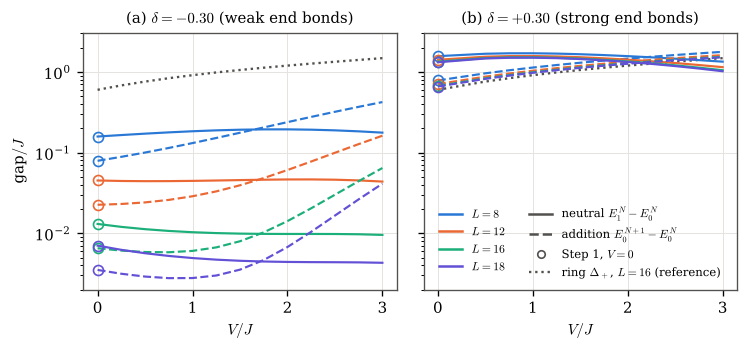

In [35]:
L_COLORS = dict(zip(L_GRID, ("#2a78d6", "#eb6834", "#1baf7a", "#6250d6")))
main_ring = ring[ring.L == 16]

fig, axes = plt.subplots(1, 2, figsize=(6.4, 3.0), sharey=True)
for ax, d, title in zip(axes, DELTA_GRID, ("(a) $\\delta=-0.30$ (weak end bonds)", "(b) $\\delta=+0.30$ (strong end bonds)")):
    s_ring = main_ring[main_ring.delta == d].sort_values("V")
    ax.semilogy(s_ring.V, s_ring.delta_plus, ":", color=GRAY, lw=1.4)
    for L in L_GRID:
        s = final[(final.L == L) & (final.delta == d)]
        eps = np.linalg.eigvalsh(hopping_matrix(L, d))
        ax.semilogy(s.V, s.neutral_gap, "-", color=L_COLORS[L], lw=1.3)
        ax.semilogy(s.V, s.add_gap, "--", color=L_COLORS[L], lw=1.3)
        ax.plot([0, 0], [eps[L // 2] - eps[L // 2 - 1], eps[L // 2]], "o", mfc="none", mec=L_COLORS[L], ms=6, mew=1.0)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel("$V/J$")
axes[0].set_ylabel("gap$/J$")
axes[0].set_ylim(2e-3, 3)
for L in L_GRID:
    axes[1].plot([], [], "-", color=L_COLORS[L], label=f"$L={L}$")
axes[1].plot([], [], "-", color=GRAY, label="neutral $E_1^N-E_0^N$")
axes[1].plot([], [], "--", color=GRAY, label="addition $E_0^{N+1}-E_0^N$")
axes[1].plot([], [], "o", mfc="none", mec=GRAY, label="Step 1, $V=0$")
axes[1].plot([], [], ":", color=GRAY, lw=1.4, label=r"ring $\Delta_+$, $L=16$ (reference)")
axes[1].legend(loc="lower center", fontsize=7, ncol=2)
fig.tight_layout()
savefig(fig, "step2_gaps")
plt.show()

### 2.11 Results and what they suggest

The size trend below is a hypothesis for Step 3, not a result.

Two-mode reading: the most general number-conserving Hamiltonian of two end modes with symmetries $C$ and $R$ is $t(a_L^\dagger a_R+{\rm h.c.})+U(n_L-\tfrac12)(n_R-\tfrac12)$. Its levels give neutral gap $2|t|$ and addition gap $|t|+U/2$. So $U_{\rm eff}=2(E_0^{N+1}-E_0^N)-(E_1^N-E_0^N)$ measures how far the two gaps have separated. It vanishes exactly at $V=0$. This description only applies when the other levels are well above these four, so `neutral_gap_2` and `add_level1_gap` are printed with it.

The last table compares the two lowest addition levels with Step 3's edge window $0\le\omega<0.8\Delta_+$: at $V=3$ the second level reaches the window at the largest size, so Step 3 has to check the window there.

In [36]:
fmt = lambda x: f"{x:.5g}"
coarse = final[final.V.isin(V_COARSE)]
for d in DELTA_GRID:
    s = coarse[coarse.delta == d]
    print(f"\ndelta = {d:+.2f}: E_0^N")
    print(s.pivot(index="V", columns="L", values="E0").to_string(float_format=lambda x: f"{x:.10f}"))
    print("neutral gap E_1^N - E_0^N")
    print(s.pivot(index="V", columns="L", values="neutral_gap").to_string(float_format=fmt))
    print("addition gap E_0^(N+1) - E_0^N")
    print(s.pivot(index="V", columns="L", values="add_gap").to_string(float_format=fmt))
print("\nring Delta_+ (identical for +-delta)")
print(ring[(ring.delta == DELTA_GRID[0]) & ring.V.isin(V_COARSE)].pivot(index="V", columns="L", values="delta_plus").to_string(float_format=fmt))

rows = []
weak_end = all_open[(all_open.delta == -0.30) & all_open.V.isin(V_COARSE)]
for V, s in weak_end.groupby("V"):
    s = s.set_index("L")
    row = {"V": V}
    for L1, L2 in ((8, 12), (12, 16), (10, 14), (14, 18), (16, 18)):
        for name, gap in (("neutral", "neutral_gap"), ("add", "add_gap")):
            row[f"{name} {L1}-{L2}"] = (L2 - L1) / np.log(s.loc[L1, gap] / s.loc[L2, gap])
    rows.append(row)
lengths = pd.DataFrame(rows)
PAIRS = ((8, 12), (12, 16), (10, 14), (14, 18), (16, 18))
split_exact = {L: splitting_sturm(L, -0.30) for L in sorted({L for pair in PAIRS for L in pair})}
length_exact = {(L1, L2): (L2 - L1) / np.log(split_exact[L1] / split_exact[L2]) for L1, L2 in PAIRS}
print("\ndelta = -0.30: decay length (L2 - L1)/ln[gap(L1)/gap(L2)]")
print("    V = 0 benchmark, exact free values from Step 1's splitting_sturm at the same sizes: "
      + ", ".join(f"{L1}-{L2}: {x:.6f}" for (L1, L2), x in length_exact.items()))
print(f"    xi = {xi_exact(-0.30):.4f} is only their L -> infinity limit")
print(lengths.set_index("V").T.to_string(float_format=lambda x: f"{x:.3f}"))
dev = max(abs(lengths.loc[lengths.V == 0, f"{name} {L1}-{L2}"].iloc[0] - length_exact[(L1, L2)])
          for L1, L2 in PAIRS for name in ("neutral", "add"))
check("S2 H1: method check: at V = 0 the two-size lengths of both gaps equal the exact free values from Step 1's "
      "splitting_sturm at the same (L1, L2), all five size pairs (tol 1e-9)", dev < 1e-9, dev)

two_mode = final[(final.delta == -0.30) & final.V.isin(V_COARSE)].assign(U_eff=lambda t: 2 * t.add_gap - t.neutral_gap)
print("\ndelta = -0.30: two-mode quantities")
print(two_mode[["L", "V", "neutral_gap", "add_gap", "U_eff", "neutral_gap_2", "add_level1_gap"]].to_string(index=False, float_format=fmt))
dev = two_mode[two_mode.V == 0].U_eff.abs().max()
check("S2 H2: U_eff = 2 * addition gap - neutral gap vanishes at V = 0", dev < 1e-11, dev)

rows = []
for V, s in weak_end[weak_end.V > 0].groupby("V"):
    u = (2 * s.set_index("L").add_gap - s.set_index("L").neutral_gap)
    rows.append({"V": V, **{f"{L1}-{L2}": (L2 - L1) / np.log(u[L1] / u[L2]) for L1, L2 in ((8, 12), (12, 16), (10, 14), (14, 18), (16, 18))}})
print("\ndelta = -0.30: decay length of U_eff")
print(pd.DataFrame(rows).set_index("V").to_string(float_format=lambda x: f"{x:.3f}"))

rows = []
for L in L_GRID:
    for V in V_COARSE:
        a = final[(final.L == L) & (final.delta == -0.30) & (final.V == V)].iloc[0]
        own = ring[(ring.L == L) & (ring.delta == -0.30) & (ring.V == V)].delta_plus.iloc[0]
        rows.append({"L": L, "V": V, "first addition": a.add_gap, "second addition": a.add_gap + a.add_level1_gap,
                     "0.8 Delta_+ (same L)": 0.8 * own, "0.9 Delta_+ (same L)": 0.9 * own,
                     "second inside 0.8 window": a.add_gap + a.add_level1_gap < 0.8 * own,
                     "second inside 0.9 window": a.add_gap + a.add_level1_gap < 0.9 * own})
print("\ndelta = -0.30: addition levels against the Step 3 edge window (L = 18 is an odd-M ring, whose Delta_+ overshoots)")
print(pd.DataFrame(rows).to_string(index=False, float_format=fmt))


delta = -0.30: E_0^N
L              8              12             16             18
V                                                             
0   -4.5511509089  -7.2943351128 -10.0712407105 -11.4643652418
0.5 -4.9459976590  -7.9163014044 -10.9323836537 -12.4459868173
1   -5.3833081185  -8.5936199482 -11.8631753812 -13.5047305894
2   -6.3867487621 -10.1176810835 -13.9308695271 -15.8483168545
3   -7.5569220941 -11.8861740131 -16.2939850197 -18.5112078994
neutral gap E_1^N - E_0^N
L        8        12        16        18
V                                       
0   0.15814 0.045105   0.01305 0.0070258
0.5 0.17164 0.044224   0.01124 0.0056577
1    0.1838 0.044598  0.010306 0.0049291
2   0.19401 0.046447 0.0098041 0.0044127
3   0.17666 0.043722 0.0095429 0.0043072
addition gap E_0^(N+1) - E_0^N
L         8        12        16        18
V                                        
0   0.079071 0.022553 0.0065252 0.0035129
0.5  0.10011 0.024129 0.0058574 0.0029069
1    0.13118 0.028752 0.0


delta = -0.30: decay length (L2 - L1)/ln[gap(L1)/gap(L2)]
    V = 0 benchmark, exact free values from Step 1's splitting_sturm at the same sizes: 8-12: 3.188515, 12-16: 3.225338, 10-14: 3.215302, 14-18: 3.228937, 16-18: 3.229869
    xi = 3.2308 is only their L -> infinity limit
V               0     0.5   1     2     3  
neutral 8-12  3.189 2.950 2.825 2.798 2.865
add 8-12      3.189 2.811 2.635 2.926 4.167
neutral 12-16 3.225 2.920 2.730 2.571 2.628
add 12-16     3.225 2.825 2.566 2.746 4.338
neutral 10-14 3.215 2.931 2.763 2.659 2.735
add 10-14     3.215 2.812 2.582 2.813 4.248
neutral 14-18 3.229 2.915 2.716 2.522 2.548
add 14-18     3.229 2.845 2.573 2.713 4.429
neutral 16-18 3.230 2.914 2.712 2.505 2.514
add 16-18     3.230 2.855 2.581 2.703 4.474
[pass] S2 H1: method check: at V = 0 the two-size lengths of both gaps equal the exact free values from Step 1's splitting_sturm at the same (L1, L2), all five size pairs (tol 1e-9)   [2.69e-11]

delta = -0.30: two-mode quantities
 L   

### Step 2 summary

In [37]:
step2 = {name: c for name, c in CHECKS.items() if name.startswith("S2 ")}
n_pass = sum(c["pass"] for c in step2.values())
print(f"Step 2: {n_pass}/{len(step2)} checks passed")
for name, c in step2.items():
    if not c["pass"]:
        print("  FAILED:", name)
pd.DataFrame([{"check": name, "passed": c["pass"], "worst_deviation": c["value"]} for name, c in step2.items()]).to_csv(
    DATA_DIR / "step2_checks.csv", index=False, float_format="%.3e")
print(f"python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, pandas {pd.__version__}, "
      f"matplotlib {plt.matplotlib.__version__}, mpmath {mpmath.__version__}")

Step 2: 61/61 checks passed
python 3.13.18, numpy 2.5.3, scipy 1.18.1, pandas 3.0.5, matplotlib 3.11.2, mpmath 1.4.1


---
## Step 3. Localisation and coherence

**Question.** Add one particle at site $j$ to the half-filled ground state. Is the result mostly one eigenstate (a coherent excitation), and is that excitation localised at the edge?

**Observable** (guide Eq. A.5). Resolve $c_j^\dagger|\Omega_N\rangle$ into the eigenstates $|m,N+1\rangle$:
$$A^+_j(\omega)=\sum_m w_{jm}\,\delta(\omega-\omega_m),\qquad w_{jm}=\big|\langle m,N+1|c_j^\dagger|\Omega_N\rangle\big|^2,\qquad \omega_m=E^{N+1}_m-E^N_0 .$$
$w_{jm}$ is the probability that adding a particle at $j$ produces exactly state $m$; $\omega_m$ is what that costs.

**Sum rule.** Completeness of the $|m,N+1\rangle$ and $c_jc_j^\dagger=1-n_j$ give $\sum_m w_{jm}=\langle\Omega_N|c_jc_j^\dagger|\Omega_N\rangle=1-\langle n_j\rangle$, which is $\tfrac12$ at every $V$ by the particle-hole symmetry $C$ (Step 2). We report the normalised weight $z_{jm}=w_{jm}/(1-\langle n_j\rangle)$.

**Edge window** (guide item 3). On the ring there are no edges, so the ring's addition threshold $\Delta_+$ is where bulk excitations start. Lines with $0\le\omega<f\,\Delta_+$ on the open chain are edge lines. We use $f=0.8$ and test $f=0.6$ to $0.9$. Then
$$z_0=\frac{\sum_{m\in W}w_{0m}}{1-\langle n_0\rangle}.$$
At $V=0$ this is exactly $|\psi^L_0|^2$ at every $L$ (Step 1, Sec. 1.7): $0.7309$, $0.7129$, $0.7104$, $0.7102$ at $L=8,12,16,18$ (Sec. 1.9). $1-r^2=0.710$ is only its $L\to\infty$ limit.

**Profile** (guide item 4). $W_j=\sum_{m\in W}w_{jm}$ at every site $j$, and $\xi_W$ from a fit $W_j\propto e^{-2j/\xi_W}$ on the even sites $j<L/2$, the same sites as Step 1's `free_benchmark`. The $V=0$ benchmark is the same-size value in `BENCH`: $\xi_W=3.1652$, $3.2161$, $3.2277$, $3.2285$ at $L=8,12,16,18$, not $\xi=3.2308$. We also fit the odd sites, a fixed range $j=0,2,4$ at every $L$, and report the fit residual and the weight outside the fitted sites.

**Sizes.** $L=8,12$: the full addition spectrum by dense diagonalisation (guide item 1). $L=16,18$: the Lanczos spectral measure (guide item 5), first tested against the full spectrum at $L=12$.

**Status.** Guide items 1-5 on the grid $L=8,12,16,18$, $\delta=\pm0.30$, $V=0,0.5,1,2,3$. At $V=3$ the window is not isolated at $L=16$ ($f=0.9$) and $L=18$ ($f\ge0.8$); Sec. 3.6 reports this.

In [38]:
# ---- Step 3 parameters (edit these) ----
L_S3 = [8, 12]                        # full addition spectrum by dense diagonalisation (guide item 1: L <= 12)
DELTA_S3 = [-0.30, 0.30]
V_S3 = [0.0, 0.5, 1.0, 2.0, 3.0]
F_WINDOW = 0.8                        # edge window 0 <= omega < F_WINDOW * Delta_+ (guide item 3)
F_SCAN = [0.6, 0.7, 0.8, 0.9]         # window factors tested (guide item 3)
L_BRUTE = [4, 6]                      # sizes for the independent full-Fock-space check (A9)
L_LANCZOS = [16, 18]                  # Lanczos spectral measure (guide item 5)
K_LANCZOS = [100, 200, 400]           # Lanczos vectors tested (guide item 5)
K_PROFILE = 200                       # Lanczos vectors used for the profile at every site
WIDTHS = [0.02, 0.01, 0.005]          # Lorentzian widths, presentation only (guide item 1)

### 3.1 Functions

`addition_spectrum` follows the definition line by line:
1. $\Omega_N$ from `half_filled_state`, the Step 2 selection rule, and its energy $E_0^N=\langle\Omega|H|\Omega\rangle$;
2. $v=c_j^\dagger\Omega_N$ with Step 2's `c_dag`, which carries the fermion sign string; $v$ lives in sector $N+1$;
3. every eigenpair $(E_m,u_m)$ of sector $N+1$ by dense diagonalisation ($\le792\times792$ at $L=12$);
4. $w_{jm}=(u_m\cdot v)^2$: the $u_m$ are an orthonormal basis, so $u_m\cdot v$ is the component of $v$ along $u_m$. All amplitudes are real on the open chain.

`edge_window` returns $f\Delta_+$ from Step 2's `ring_gap` at the same $(L,\delta,V)$.

`merge_lines` adds up the weights of lines closer than `ETA_DEGENERATE` (Step 2), because inside a degenerate subspace only the total weight is defined, and drops lines with no weight.

`brute_force_addition` computes the same spectrum without any Step 2 code, for the check A9. It builds $c_i=Z\otimes\dots\otimes Z\otimes a\otimes 1\otimes\dots\otimes 1$ ($a$ removes a particle, $Z=\mathrm{diag}(1,-1)$ is the sign $(-1)^{n}$ of each site to the left) as $2^L\times2^L$ matrices, writes $H$ of Eq. (A.1) from them, and picks the sectors by the diagonal of $\sum_i n_i$. It also returns the gap above the $N$-particle ground state: if that is not zero, the ground state is unique and no selection rule is needed.

In [39]:
from functools import reduce


def addition_spectrum(L, delta, V, j):
    """All lines of the addition spectrum at site j: omega_m = E_m^{N+1} - E_0^N and w_jm = |<m, N+1| c_j^dag |Omega_N>|^2."""
    N = L // 2
    psi = half_filled_state(L, delta, V)                                  # Omega_N, selected by the Step 2 rule
    E0 = psi @ (hamiltonian(L, N, delta, V) @ psi)                        # its energy <Omega|H|Omega>
    v = c_dag(L, N, j) @ psi                                              # c_j^dag Omega_N, a vector in sector N+1
    E, U = np.linalg.eigh(hamiltonian(L, N + 1, delta, V).toarray())      # every eigenpair of sector N+1
    w = (U.T @ v) ** 2                                                    # squared component of v along each u_m
    return E - E0, w


def edge_window(L, delta, V, f=F_WINDOW):
    """Upper edge f * Delta_+ of the edge window; Delta_+ from the ring at the same (L, delta, V)."""
    return f * ring_gap(L, delta, V)["delta_plus"]


def merge_lines(omega, w, eta=ETA_DEGENERATE, w_min=1e-12):
    """Sum the weights of lines closer than eta (omega sorted); keep only lines with weight > w_min."""
    groups = np.split(np.arange(len(omega)), np.flatnonzero(np.diff(omega) > eta) + 1)
    om = np.array([omega[g].mean() for g in groups])
    wt = np.array([w[g].sum() for g in groups])
    return om[wt > w_min], wt[wt > w_min]


def brute_force_addition(L, delta, V, j):
    """Same as addition_spectrum, built in the full 2^L Fock space from Kronecker products (no Step 2 code).
    Returns omega_m, w_jm and the gap above the N-particle ground state."""
    a = np.array([[0.0, 1.0], [0.0, 0.0]])                    # removes a particle: |1> -> |0>, basis (|0>, |1>)
    Z = np.diag([1.0, -1.0])                                   # (-1)^n of one site
    c = [reduce(np.kron, [Z] * i + [a] + [np.eye(2)] * (L - 1 - i)) for i in range(L)]
    n = [ci.T @ ci for ci in c]
    one = np.eye(2**L)
    H = np.zeros((2**L, 2**L))
    for i in range(L - 1):
        J = 1 + (-1) ** i * delta
        H += -J * (c[i].T @ c[i + 1] + c[i + 1].T @ c[i]) + V * (n[i] - one / 2) @ (n[i + 1] - one / 2)
    count = np.rint(np.diag(sum(n))).astype(int)              # particle number of each Fock state
    sN, sN1 = count == L // 2, count == L // 2 + 1
    E_N, U_N = np.linalg.eigh(H[np.ix_(sN, sN)])
    ground = np.zeros(2**L)
    ground[sN] = U_N[:, 0]
    v = (c[j].T @ ground)[sN1]                                # c_j^dag Omega_N, restricted to N + 1 particles
    E, U = np.linalg.eigh(H[np.ix_(sN1, sN1)])
    return E - E_N[0], (U.T @ v) ** 2, E_N[1] - E_N[0]

### 3.2 Checks

Step 2 already verified the matrices and $c_j^\dagger$. What is new here is how they are assembled, so the checks test that:
- **A1, sum rule** at every site and every $V$. It needs $\Omega_N$, $c_j^\dagger$ and a complete eigenbasis of sector $N+1$ to be consistent.
- **A2, $L=2$ closed form.** One particle on two sites has $E_0=-V/4-J_0$; the only $N+1$ state, $|11\rangle$, has $E=V/4$. So there is one line at $\omega=J_0+V/2$ with weight $\tfrac12$. This tests $\omega$ at $V\neq0$ by hand.
- **A3, $V=0$ against Step 1.** At $V=0$ the $N+1$ eigenstates reachable from $\Omega_N$ are $\Omega_N$ plus one particle in an empty orbital $n$, so the lines must sit at $\varepsilon_n$ with weight $\phi_n(j)^2$, computed from the $L\times L$ hopping matrix only. Weights are summed over any degenerate many-body cluster.
- **A4, $z_0=|\psi^L_0|^2$ at $V=0$**, the exact value at the same $L$ with Step 1's left edge state.
- **A5, window isolated at the edge:** exactly one line with weight at $j=0$ inside the window for $\delta=-0.30$, and none for $\delta=+0.30$, at every grid point and every $f$ in `F_SCAN`. If this failed, $z_0$ would depend on the window and we would have to say so.
- **A6, one eigenstate in the window:** the window holds exactly one eigenstate of sector $N+1$ for $\delta=-0.30$, whatever its weight, and none for $\delta=+0.30$. So $W_j$ is the profile of one state.
- **A7, whole profile at $V=0$:** $W_j=\phi_+(j)^2$ at every site, with $\phi_+$ = `edge_pair(L, delta)["antibonding"]` of the same $L$. On even sites this is $|\psi_L(j)|^2/2$; on odd sites it is $|\psi_R(j)|^2/2$, the far edge, which is why $\xi_W$ is fitted on even sites only.
- **A8, $\xi_W$ at $V=0$** equals the same-size Step 1 value `BENCH[(L, delta)]["xi_W"]`, fitted on the same sites.
- **A9, independent calculation:** at $L=4$ and $6$, both $\delta$, every $V$ and every site, the lines and weights from `addition_spectrum` equal those from `brute_force_addition`, which shares no code with Step 2. The $N$-particle ground state there is unique (gap printed).

In [40]:
site_spectra = {(L, d, V): [addition_spectrum(L, d, V, j) for j in range(L)] for L in L_S3 for d in DELTA_S3 for V in V_S3}
spectra = {key: s[0] for key, s in site_spectra.items()}                  # j = 0
windows = {(L, d, V, f): edge_window(L, d, V, f) for L in L_S3 for d in DELTA_S3 for V in V_S3 for f in F_SCAN}

dev = max(abs(w.sum() - 0.5) for s in site_spectra.values() for om, w in s)
check("S3 A1: sum rule sum_m w_jm = 1/2, every site, L = 8, 12, both delta, every V", dev < 1e-12, dev)

dev = 0.0
for d in DELTA_S3:
    for V in V_S3:
        om, w = addition_spectrum(2, d, V, 0)
        dev = max(dev, abs(om[0] - (1 + d + V / 2)), abs(w[0] - 0.5))
check("S3 A2: L = 2 closed form, omega = J_0 + V/2 and w = 1/2", dev < 1e-13, dev)

dev = 0.0
for L in L_S3:
    for d in DELTA_S3:
        eps, phi = np.linalg.eigh(hopping_matrix(L, d))
        for j, (om, w) in enumerate(site_spectra[(L, d, 0.0)]):
            explained = np.zeros(len(w), dtype=bool)
            for n in range(L // 2, L):                                    # the empty orbitals
                near = np.abs(om - eps[n]) < 1e-8
                explained |= near
                dev = max(dev, abs(w[near].sum() - phi[j, n] ** 2))
            dev = max(dev, w[~explained].sum())                           # no weight anywhere else
check("S3 A3: V = 0 lines and weights = empty orbitals phi_n(j)^2, every site", dev < 1e-12, dev)

dev = 0.0
for L in L_S3:
    om, w = spectra[(L, -0.30, 0.0)]
    z0 = w[om < windows[(L, -0.30, 0.0, F_WINDOW)]].sum() / w.sum()
    dev = max(dev, abs(z0 - edge_pair(L, -0.30)["left"][0] ** 2))
check("S3 A4: z_0 = |psi^L_0|^2 at V = 0, same L (Step 1)", dev < 1e-10, dev)

ok_lines, ok_states = True, True
for (L, d, V), (om, w) in spectra.items():
    for f in F_SCAN:
        inside = om < windows[(L, d, V, f)]
        ok_lines &= int(np.sum(inside & (w > 1e-12))) == (1 if d < 0 else 0)
        ok_states &= int(np.sum(inside)) == (1 if d < 0 else 0)
check("S3 A5: one line with weight at j = 0 in the window for delta = -0.30, none for +0.30, every V and f", ok_lines)
check("S3 A6: one eigenstate of sector N+1 in the window for delta = -0.30 (any weight), none for +0.30, every V and f", ok_states)

# W_j = weight inside the window at every site (delta < 0 only; for delta > 0 the window is empty)
profiles = {(L, d, V): np.array([w[om < windows[(L, d, V, F_WINDOW)]].sum() for om, w in s])
            for (L, d, V), s in site_spectra.items() if d < 0}
dev = max(np.max(np.abs(profiles[(L, -0.30, 0.0)] - edge_pair(L, -0.30)["antibonding"] ** 2)) for L in L_S3)
check("S3 A7: V = 0 profile W_j = phi_+(j)^2 at every site (Step 1 antibonding orbital, same L)", dev < 1e-12, dev)

xi_W = {(L, d, V): fit_xi(W, len(range(0, L // 2, 2))) for (L, d, V), W in profiles.items()}   # even sites j < L/2
dev = max(abs(xi_W[(L, -0.30, 0.0)] / BENCH[(L, -0.30)]["xi_W"] - 1) for L in L_S3)
check("S3 A8: V = 0 xi_W = Step 1 same-size value BENCH (even sites j < L/2), relative", dev < 1e-10, dev)

dev, gap_min, same_count = 0.0, np.inf, True
for L in L_BRUTE:
    for d in DELTA_S3:
        for V in V_S3:
            for j in range(L):
                om_b, w_b, gap = brute_force_addition(L, d, V, j)
                gap_min = min(gap_min, gap)
                a, b = merge_lines(*addition_spectrum(L, d, V, j)), merge_lines(om_b, w_b)
                if len(a[0]) != len(b[0]):
                    same_count = False
                    continue
                dev = max(dev, np.max(np.abs(a[0] - b[0])), np.max(np.abs(a[1] - b[1])))
print(f"    smallest gap above the N-particle ground state in the brute-force runs: {gap_min:.3f}")
for V in (0.0, 2.0):
    om, w = merge_lines(*brute_force_addition(4, -0.30, V, 0)[:2])
    print(f"    L = 4, delta = -0.30, V = {V:g}, j = 0: omega = {np.round(om, 4)}, w = {np.round(w, 4)}")
check("S3 A9: L = 4, 6: lines and weights = independent full-Fock-space calculation, both delta, every V and site",
      same_count and gap_min > 1e-8 and dev < 1e-12, dev)

[pass] S3 A1: sum rule sum_m w_jm = 1/2, every site, L = 8, 12, both delta, every V   [1.43e-13]
[pass] S3 A2: L = 2 closed form, omega = J_0 + V/2 and w = 1/2   [8.88e-16]
[pass] S3 A3: V = 0 lines and weights = empty orbitals phi_n(j)^2, every site   [4.93e-14]
[pass] S3 A4: z_0 = |psi^L_0|^2 at V = 0, same L (Step 1)   [2.78e-14]
[pass] S3 A5: one line with weight at j = 0 in the window for delta = -0.30, none for +0.30, every V and f
[pass] S3 A6: one eigenstate of sector N+1 in the window for delta = -0.30 (any weight), none for +0.30, every V and f
[pass] S3 A7: V = 0 profile W_j = phi_+(j)^2 at every site (Step 1 antibonding orbital, same L)   [5.18e-14]
[pass] S3 A8: V = 0 xi_W = Step 1 same-size value BENCH (even sites j < L/2), relative   [8.88e-16]


    smallest gap above the N-particle ground state in the brute-force runs: 0.303
    L = 4, delta = -0.30, V = 0, j = 0: omega = [0.3052 1.6052], w = [0.4201 0.0799]
    L = 4, delta = -0.30, V = 2, j = 0: omega = [0.8461 2.7765 3.5387 4.2083], w = [0.3723 0.1194 0.0067 0.0016]
[pass] S3 A9: L = 4, 6: lines and weights = independent full-Fock-space calculation, both delta, every V and site   [7.11e-15]


### 3.3 Addition spectra at the edge

Lines at $L=12$, $j=0$. The dashed line is the window edge $0.8\,\Delta_+$. No broadening is applied: each line is one eigenstate of sector $N+1$.

saved figures/step3_spectra.pdf


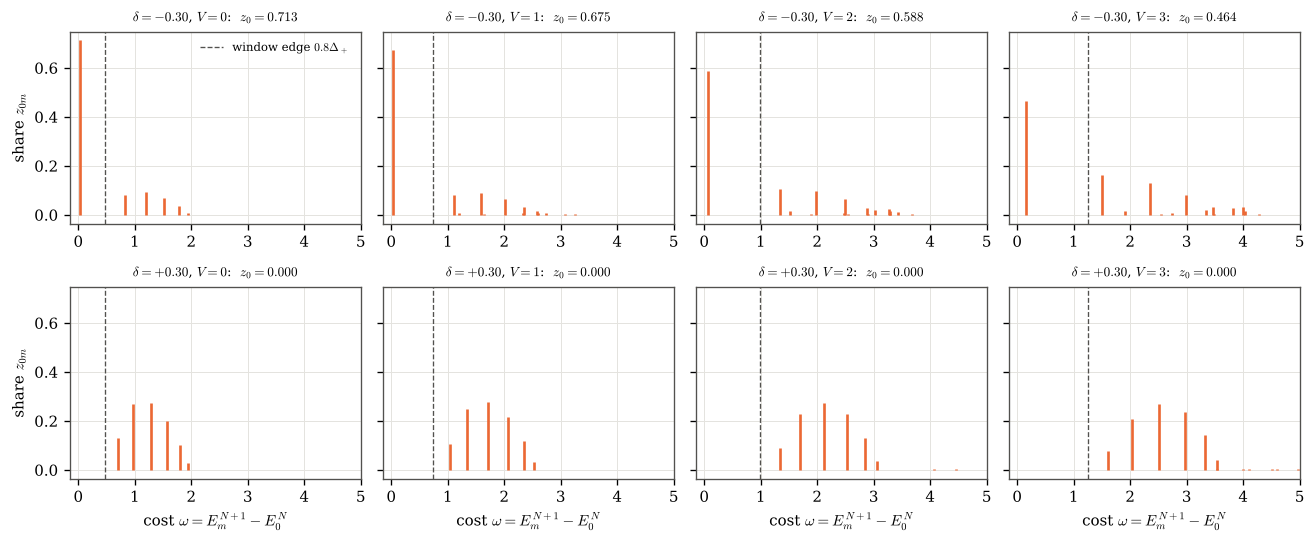

In [41]:
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharex=True, sharey=True)
for row, d in zip(axes, DELTA_S3):
    for ax, V in zip(row, [0.0, 1.0, 2.0, 3.0]):
        om, w = spectra[(12, d, V)]
        Wc = windows[(12, d, V, F_WINDOW)]
        z0 = w[om < Wc].sum() / w.sum()
        ax.vlines(om, 0, w / w.sum(), color=COLORS[0.30], lw=1.6)
        ax.axvline(Wc, ls="--", color=GRAY, lw=0.8)
        ax.set_xlim(-0.15, 5)
        ax.set_title(rf"$\delta={d:+.2f}$, $V={V:g}$:  $z_0={z0:.3f}$", fontsize=8)
for ax in axes.flat:
    ax.tick_params(labelbottom=True)                  # cost axis numbered on every panel
for ax in axes[-1]:
    ax.set_xlabel(r"cost $\omega=E^{N+1}_m-E^N_0$")
for ax in axes[:, 0]:
    ax.set_ylabel(r"share $z_{0m}$")
axes[0, 0].plot([], [], ls="--", color=GRAY, lw=0.8, label=r"window edge $0.8\Delta_+$")
axes[0, 0].legend(fontsize=7, loc="upper right")
fig.tight_layout()
savefig(fig, "step3_spectra")
plt.show()

### 3.4 $z_0$ against $V$, $L$ and the window factor

Besides $z_0$ (the window), the table splits the rest of the weight at $j=0$ into the part between the window edge and $\Delta_+$ (`z_to_dplus`) and the part at or above $\Delta_+$ (`z_above_dplus`). `omega_next` and `z_next` are the first line with weight outside the window. This line is the second state of sector $N+1$, i.e. Step 2's second addition level.

In [42]:
rows = []
for (L, d, V), (om, w) in spectra.items():
    Wc = windows[(L, d, V, F_WINDOW)]
    dp = Wc / F_WINDOW
    rec = {"L": L, "delta": d, "V": V, "j": 0, "delta_plus": dp}
    for f in F_SCAN:
        rec[f"z0_f{f:.1f}"] = w[om < windows[(L, d, V, f)]].sum() / w.sum()
    rec["z_to_dplus"] = w[(om >= Wc) & (om < dp)].sum() / w.sum()
    rec["z_above_dplus"] = w[om >= dp].sum() / w.sum()
    om_c, w_c = merge_lines(om, w)
    rec["omega_edge"] = om_c[om_c < Wc][0] if (om_c < Wc).any() else np.nan
    rec["omega_next"] = om_c[om_c >= Wc][0]
    rec["z_next"] = w_c[om_c >= Wc][0] / w.sum()
    rec["second_level"] = om[1]                                           # second state of sector N+1, any weight
    rec["sum_w"] = w.sum()
    rows.append(rec)
z0_table = pd.DataFrame(rows).sort_values(["delta", "L", "V"]).reset_index(drop=True)
z0_table.to_csv(DATA_DIR / "step3_z0.csv", index=False, float_format="%.12g")
display(z0_table[["delta", "L", "V", "z0_f0.8", "z_to_dplus", "z_above_dplus", "omega_edge", "omega_next", "z_next",
                  "second_level", "delta_plus"]])

,delta,L,V,z0_f0.8,z_to_dplus,z_above_dplus,omega_edge,omega_next,z_next,second_level,delta_plus
0,-0.3,8,0,0.730911,0,0.269089,0.0790713,1.04292,0.145997,1.04292,0.6
1,-0.3,8,0.5,0.706072,0,0.293928,0.10011,1.21658,0.154202,1.21658,0.775925
2,-0.3,8,1,0.672728,0,0.327272,0.131175,1.3805,0.164791,1.3805,0.954527
3,-0.3,8,2,0.589304,0,0.410696,0.238417,1.70976,0.199811,1.70976,1.33799
4,-0.3,8,3,0.503162,0,0.496838,0.42272,2.03367,0.251605,2.03367,1.78991
5,-0.3,12,0,0.712894,0,0.287106,0.0225526,0.828051,0.0827986,0.828051,0.6
6,-0.3,12,0.5,0.699755,0,0.300245,0.0241285,0.98168,0.0806736,0.98168,0.761584
7,-0.3,12,1,0.674648,0,0.325352,0.0287518,1.11574,0.0830129,1.11574,0.918622
8,-0.3,12,2,0.587552,0,0.412448,0.0607514,1.3416,0.106761,1.3416,1.2283
9,-0.3,12,3,0.464081,0.163278,0.372641,0.161852,1.50205,0.163278,1.50205,1.56625


### 3.5 Profile $W_j$ and the length $\xi_W$ (guide item 4)

Left: $z_j=W_j/(1-\langle n_j\rangle)$ for the window line at $L=12$, filled markers on even sites and open markers on odd sites; crosses are the exact $V=0$ values $\phi_+(j)^2/\tfrac12$ (A7). The window line is symmetric under reflection of the chain, so the odd sites near $j=0$ carry the small tail of the right edge state. Right: the same profile for the next line (`omega_next` above), to see where it sits along the chain.

The fits, and the same quantities at $L=16,18$, are in Sec. 3.7.

saved figures/step3_profile.pdf


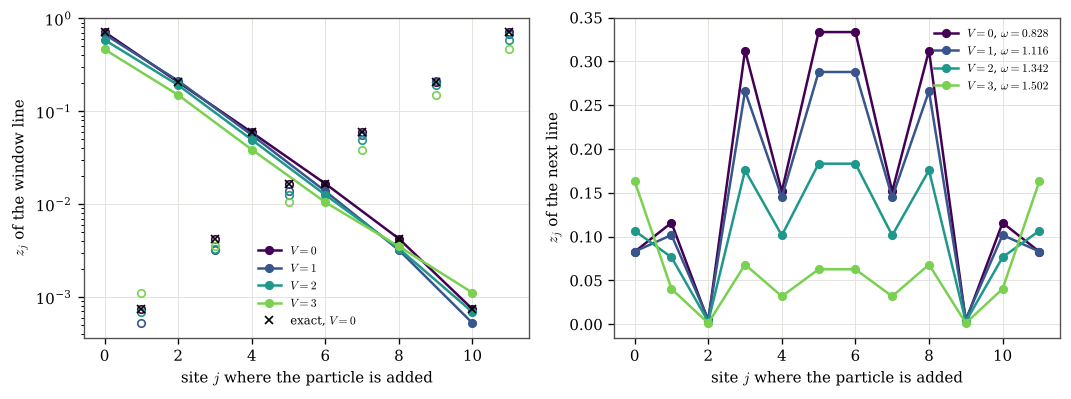

In [43]:
prof_rows = []
for (L, d, V), W in profiles.items():
    omega_next = z0_table.query("L == @L and delta == @d and V == @V")["omega_next"].item()
    for j, (om, w) in enumerate(site_spectra[(L, d, V)]):
        prof_rows.append({"L": L, "delta": d, "V": V, "j": j, "W_j": W[j], "z_window_j": W[j] / w.sum(),
                          "omega_next": omega_next, "z_next_j": w[np.abs(om - omega_next) < ETA_DEGENERATE].sum() / w.sum()})
profile_table = pd.DataFrame(prof_rows)

L_P = 12
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
shades = plt.cm.viridis(np.linspace(0.0, 0.8, 4))
for V, col in zip([0.0, 1.0, 2.0, 3.0], shades):
    p = profile_table.query("L == @L_P and V == @V")
    even, odd = p[p.j % 2 == 0], p[p.j % 2 == 1]
    ax1.semilogy(even.j, even.z_window_j, "o-", color=col, label=rf"$V={V:g}$")
    ax1.semilogy(odd.j, odd.z_window_j, "o", mfc="none", color=col)
    ax2.plot(p.j, p.z_next_j, "o-", color=col, label=rf"$V={V:g}$, $\omega={p.omega_next.iloc[0]:.3f}$")
ax1.semilogy(range(L_P), 2 * edge_pair(L_P, -0.30)["antibonding"] ** 2, "x", color="k", label="exact, $V=0$")
ax1.set_xlabel("site $j$ where the particle is added"); ax1.set_ylabel(r"$z_j$ of the window line"); ax1.legend(fontsize=7)
ax2.set_xlabel("site $j$ where the particle is added"); ax2.set_ylabel(r"$z_j$ of the next line"); ax2.legend(fontsize=7)
fig.tight_layout()
savefig(fig, "step3_profile")
plt.show()

### 3.6 $L=16,18$: the Lanczos spectral measure (guide item 5)

At $L=16,18$ the $N+1$ sector has $11\,440$ and $43\,758$ states, too many to diagonalise completely. The Lanczos spectral measure gives the low lines and their weights without the full spectrum:
1. start from $q_0=v/|v|$ with $v=c_j^\dagger|\Omega_N\rangle$;
2. build orthonormal vectors $q_0,q_1,\dots,q_{k-1}$ by repeatedly applying $H$ and removing the components along all earlier vectors (full reorthogonalisation, done twice for safety). In this basis $H$ is tridiagonal, with $\alpha_i=q_i\cdot Hq_i$ on the diagonal and $\beta_i$ (the length of what is left) beside it;
3. diagonalise that $k\times k$ matrix $T$: its eigenvalues $\theta_i$ approximate the energies of the $N+1$ states that $v$ overlaps with, and $|v|^2\,s_i(0)^2$, with $s_i(0)$ the first component of its $i$-th eigenvector, approximates their weights.

The low lines converge first. The weights add up to $|v|^2$ by construction, so the sum rule is not a test here and we do not claim it from these lines.

Checks:
- **A10:** at $L=12$, Lanczos with 100, 200, 400 vectors gives the same window weight (every $f$) and the same lowest three lines and weights as the full spectrum of Sec. 3.2, both $\delta$, every $V$.
- **A11:** at $L=16,18$, 100 and 200 vectors give the same window weight as 400, at every point and $f$; the $K_\text{PROFILE}=200$ profile at $j=0$ agrees with 400.
- **A12:** at $V=0$, $z_0$ and the whole profile $W_j$ equal Step 1's exact same-size values (`BENCH`).
- **A13:** the lowest line and the second line at $j=0$ ($\delta=-0.30$) sit at Step 2's addition gap `add_gap` and second addition level `add_gap + add_level1_gap` (`data/step2_grid.csv`; `add_level1_gap` is the gap inside the $N+1$ sector), which Step 2 computed independently from its own eigenvalues.
- **A14:** for $\delta=+0.30$ the window is empty at $L=16,18$, every $V$ and $f$.

In [44]:
def lanczos_spectrum(H, v, k):
    """Lanczos spectral measure from v with full reorthogonalisation (guide item 5).
    Returns the Ritz values theta_i and weights |v|^2 s_i(0)^2."""
    norm2 = v @ v
    Q = np.zeros((k, len(v)))                         # rows: orthonormal Krylov vectors q_0 .. q_{k-1}
    alpha, beta = np.zeros(k), np.zeros(k)
    q = v / np.sqrt(norm2)
    for i in range(k):
        Q[i] = q
        r = H @ q
        alpha[i] = q @ r
        for _ in range(2):                            # remove every earlier direction, twice
            r -= Q[:i + 1].T @ (Q[:i + 1] @ r)
        beta[i] = np.linalg.norm(r)
        if beta[i] < 1e-10:                           # Krylov space exhausted: the measure is exact
            k = i + 1
            break
        q = r / beta[i]
    T = np.diag(alpha[:k]) + np.diag(beta[:k - 1], 1) + np.diag(beta[:k - 1], -1)
    theta, S = np.linalg.eigh(T)
    return theta, norm2 * S[0] ** 2


def addition_spectra_lanczos(L, delta, V, sites, k):
    """(omega, w) from the Lanczos measure with k vectors at each site in `sites`; ground state and H built once."""
    N = L // 2
    psi = half_filled_state(L, delta, V)
    E0 = psi @ (hamiltonian(L, N, delta, V) @ psi)
    H1 = hamiltonian(L, N + 1, delta, V)
    out = []
    for j in sites:
        theta, w = lanczos_spectrum(H1, c_dag(L, N, j) @ psi, k)
        out.append((theta - E0, w))
    return out


# A10: against the full spectrum at L = 12
dev = 0.0
for d in DELTA_S3:
    for V in V_S3:
        om, w = spectra[(12, d, V)]
        exact = merge_lines(om, w, w_min=1e-8)
        for k in K_LANCZOS:
            om_l, w_l = addition_spectra_lanczos(12, d, V, [0], k)[0]
            for f in F_SCAN:
                Wc = windows[(12, d, V, f)]
                dev = max(dev, abs(w_l[om_l < Wc].sum() - w[om < Wc].sum()))
            lan = merge_lines(om_l, w_l, w_min=1e-8)
            dev = max(dev, np.max(np.abs(lan[0][:3] - exact[0][:3])), np.max(np.abs(lan[1][:3] - exact[1][:3])))
check("S3 A10: L = 12 Lanczos (100/200/400 vectors) = full spectrum: window weight every f, lowest three lines", dev < 1e-10, dev)

# the L = 16, 18 grid (a few minutes at L = 18)
lanczos = {}
for L in L_LANCZOS:
    for d in DELTA_S3:
        for V in V_S3:
            rec = {"delta_plus": ring_gap(L, d, V)["delta_plus"]}
            for k in K_LANCZOS:
                rec[k] = addition_spectra_lanczos(L, d, V, [0], k)[0]
            if d < 0:
                rec["sites"] = addition_spectra_lanczos(L, d, V, range(L), K_PROFILE)
            lanczos[(L, d, V)] = rec
            for f in F_SCAN:
                windows[(L, d, V, f)] = f * rec["delta_plus"]

kmax = max(K_LANCZOS)
dev = 0.0
for (L, d, V), rec in lanczos.items():
    om, w = rec[kmax]
    for f in F_SCAN:
        Wc = windows[(L, d, V, f)]
        for k in K_LANCZOS[:-1]:
            dev = max(dev, abs(rec[k][1][rec[k][0] < Wc].sum() - w[om < Wc].sum()))
        if d < 0:
            om_p, w_p = rec["sites"][0]
            dev = max(dev, abs(w_p[om_p < Wc].sum() - w[om < Wc].sum()))
check("S3 A11: L = 16, 18: window weight converged in the number of Lanczos vectors (100, 200 vs 400)", dev < 1e-10, dev)

dev = 0.0
for L in L_LANCZOS:
    rec = lanczos[(L, -0.30, 0.0)]
    Wc = windows[(L, -0.30, 0.0, F_WINDOW)]
    om, w = rec[kmax]
    W = np.array([w_j[om_j < Wc].sum() for om_j, w_j in rec["sites"]])
    dev = max(dev, abs(w[om < Wc].sum() / w.sum() - BENCH[(L, -0.30)]["z0"]), np.max(np.abs(W - BENCH[(L, -0.30)]["W"])))
check("S3 A12: L = 16, 18, V = 0: z_0 and the whole profile W_j = Step 1 same-size values (BENCH)", dev < 1e-10, dev)

grid2 = pd.read_csv(DATA_DIR / "step2_grid.csv").query("boundary == 'open'")
dev = 0.0
for L in L_LANCZOS:
    for V in V_S3:
        row = grid2.query("L == @L and delta == -0.30 and V == @V").iloc[0]
        om_c, w_c = merge_lines(*lanczos[(L, -0.30, V)][kmax], w_min=1e-8)
        dev = max(dev, abs(om_c[0] - row.add_gap), abs(om_c[1] - (row.add_gap + row.add_level1_gap)))
check("S3 A13: L = 16, 18: lowest and second line at j = 0 = Step 2 addition gap and second addition level", dev < 1e-8, dev)

ok = True
for (L, d, V), rec in lanczos.items():
    if d > 0:
        om, w = rec[kmax]
        ok &= all(int(np.sum((om < windows[(L, d, V, f)]) & (w > 1e-12))) == 0 for f in F_SCAN)
check("S3 A14: L = 16, 18, delta = +0.30: no line in the window, every V and f", ok)

rows = []
for (L, d, V), rec in lanczos.items():
    om, w = rec[kmax]
    om_c, w_c = merge_lines(om, w, w_min=1e-10)
    r = {"L": L, "delta": d, "V": V, "delta_plus": rec["delta_plus"]}
    for f in F_SCAN:
        Wc = windows[(L, d, V, f)]
        r[f"z0_f{f:.1f}"] = w[om < Wc].sum() / w.sum()
        r[f"lines_f{f:.1f}"] = int(np.sum((om_c < Wc)))
    r.update({"omega_1": om_c[0], "z_1": w_c[0] / w.sum(), "omega_2": om_c[1], "z_2": w_c[1] / w.sum(),
              "lanczos_vectors": kmax})
    rows.append(r)
lanczos_table = pd.DataFrame(rows).sort_values(["delta", "L", "V"]).reset_index(drop=True)
lanczos_table.to_csv(DATA_DIR / "step3_lanczos.csv", index=False, float_format="%.12g")
display(lanczos_table[["delta", "L", "V", "delta_plus", "z0_f0.6", "z0_f0.8", "z0_f0.9", "lines_f0.8", "lines_f0.9",
                       "omega_1", "z_1", "omega_2", "z_2"]])

[pass] S3 A10: L = 12 Lanczos (100/200/400 vectors) = full spectrum: window weight every f, lowest three lines   [1.24e-14]


[pass] S3 A11: L = 16, 18: window weight converged in the number of Lanczos vectors (100, 200 vs 400)   [0.00e+00]
[pass] S3 A12: L = 16, 18, V = 0: z_0 and the whole profile W_j = Step 1 same-size values (BENCH)   [2.85e-12]
[pass] S3 A13: L = 16, 18: lowest and second line at j = 0 = Step 2 addition gap and second addition level   [1.07e-13]
[pass] S3 A14: L = 16, 18, delta = +0.30: no line in the window, every V and f


,delta,L,V,delta_plus,z0_f0.6,z0_f0.8,z0_f0.9,lines_f0.8,lines_f0.9,omega_1,z_1,omega_2,z_2
0,-0.3,16,0,0.6,0.710396,0.710396,0.710396,1,1,0.00652518,0.710396,0.733352,0.0458609
1,-0.3,16,0.5,0.758533,0.701724,0.701724,0.701724,1,1,0.00585742,0.701724,0.886678,0.0426173
2,-0.3,16,1,0.910621,0.679899,0.679899,0.679899,1,1,0.00604813,0.679899,1.02053,0.0436186
3,-0.3,16,2,1.19692,0.595148,0.595148,0.595148,1,1,0.0141521,0.595148,1.21853,0.0594485
4,-0.3,16,3,1.48057,0.457134,0.457134,0.561626,1,2,0.0643639,0.457134,1.25533,0.104492
5,-0.3,18,0,0.68539,0.710171,0.710171,0.710171,1,1,0.00351292,0.710171,0.705862,0.0346505
6,-0.3,18,0.5,0.845418,0.702274,0.702274,0.702274,1,1,0.00290687,0.702274,0.859999,0.0318632
7,-0.3,18,1,0.999289,0.680936,0.680936,0.680936,1,1,0.00278664,0.680936,0.995917,0.0330788
8,-0.3,18,2,1.28572,0.596689,0.596689,0.596689,1,1,0.00675267,0.596689,1.19247,0.0471412
9,-0.3,18,3,1.55586,0.4561,0.540034,0.540034,2,2,0.0411633,0.4561,1.18051,0.0839342


### 3.7 $z_0$ and $\xi_W$ at every size (guide item 4 and "before moving on")

For $\delta=-0.30$ at $L=8,12$ (full spectrum) and $L=16,18$ (Lanczos):
- `z0`: the window weight at $j=0$ with $f=0.8$; `z_edge`: the weight of the lowest line alone. They differ only where the window holds more than one line (`lines_in_window`).
- `xi_W`: fit of $\ln W_j$ against $j$ on the even sites $j<L/2$ (the `BENCH` sites); `rms`: the root-mean-square deviation of $\ln W_j$ from the fitted line (zero at $L=8$, where two points fix the line).
- `xi_W_024`: the same fit on $j=0,2,4$ at every $L$, so that sizes are compared with the same fit range.
- `xi_odd`: the fit on the odd sites $j<L/2$. It is negative: on odd sites the weight grows towards the far end, because those sites carry the right edge (Sec. 3.5).
- `xi_edge_line`: the even-site fit of the lowest line's own profile; it differs from `xi_W` only where the window holds two lines.
- `on_fit_sites`: fraction of $\sum_jW_j$ on the fitted sites; `sum_W`: $\sum_jW_j$, the window weight summed over every site where the particle can be added (1 at $V=0$).
- `z_centre`: window weight with the particle added at the centre, $j=L/2$ (Sec. 3.8).

Figure: left, $z_0$ (circles: window, $f=0.8$; crosses: lowest line alone); right, $\xi_W$ (circles: window, even $j<L/2$; crosses: lowest line alone; squares: fixed range $j=0,2,4$). Dotted: the $L\to\infty$ free values $1-r^2$ and $\xi$. The point $L=18$, $V=3$ is a poor fit (`rms` 0.30) because the window there holds two lines; it is left in the figure on purpose.

,L,V,z0,z_edge,lines_in_window,xi_W,rms,xi_W_024,rms_024,xi_odd,xi_edge_line,on_fit_sites,sum_W,z_centre
0,8,0,0.730911,0.730911,1,3.16515,5.66105e-16,3.05351,0.0217809,-2.29684,3.16515,0.468729,1,0.053216
1,8,0.5,0.706072,0.706072,1,3.41006,4.96507e-16,3.15083,0.0454935,-2.26484,3.41006,0.467029,0.989828,0.0557402
2,8,1,0.672728,0.672728,1,3.58441,1.57009e-16,3.25125,0.0539052,-2.29914,3.58441,0.464854,0.960643,0.0574407
3,8,2,0.589304,0.589304,1,3.73298,4.96507e-16,3.39062,0.0510029,-2.47658,3.73298,0.461099,0.857876,0.055673
4,8,3,0.503162,0.503162,1,3.62114,1.57009e-16,3.35581,0.0411719,-2.73256,3.62114,0.460717,0.726994,0.0463856
5,12,0,0.712894,0.712894,1,3.21608,0.00169419,3.21608,0.00169419,-2.57194,3.21608,0.489208,1,0.0165992
6,12,0.5,0.699755,0.699755,1,3.20259,0.0302483,3.20259,0.0302483,-2.45781,3.20259,0.490462,0.990183,0.014814
7,12,1,0.674648,0.674648,1,3.20422,0.0454347,3.20422,0.0454347,-2.44533,3.20422,0.490891,0.960913,0.013782
8,12,2,0.587552,0.587552,1,3.23035,0.0543139,3.23035,0.0543139,-2.75271,3.23035,0.490181,0.84464,0.0125732
9,12,3,0.464081,0.464081,1,3.22008,0.0524722,3.22008,0.0524722,-3.56479,3.22008,0.488692,0.667652,0.0104845


saved figures/step3_z0_xi.pdf


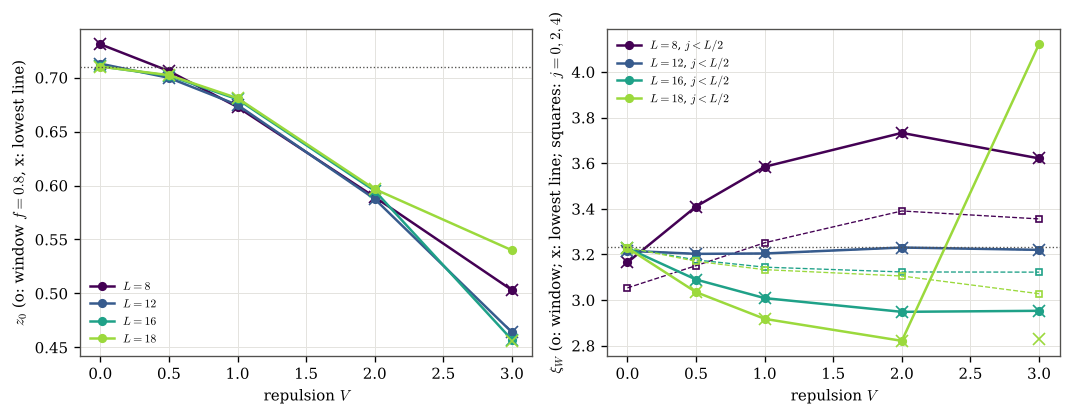

In [45]:
def fit_line(W, sites):
    """Least-squares line through (j, ln W_j) on `sites`: returns xi = -2/slope and the rms deviation of ln W_j."""
    j = np.array(list(sites))
    y = np.log(W[j])
    slope, intercept = np.polyfit(j, y, 1)
    return -2 / slope, np.sqrt(np.mean((y - intercept - slope * j) ** 2))


def site_lines(L, d, V):
    """(omega, w) at every site: full spectrum for L <= 12, Lanczos for L = 16, 18."""
    return site_spectra[(L, d, V)] if L in L_S3 else lanczos[(L, d, V)]["sites"]


size_rows, prof16 = [], []
for L in L_S3 + L_LANCZOS:
    for V in V_S3:
        lines = site_lines(L, -0.30, V)
        Wc = windows[(L, -0.30, V, F_WINDOW)]
        W = np.array([w[om < Wc].sum() for om, w in lines])
        om0, w0 = lines[0]
        om_c, w_c = merge_lines(om0, w0, w_min=1e-10)
        e1 = om_c[0]                                                       # lowest line with weight at j = 0
        W_edge = np.array([w[np.abs(om - e1) < 1e-8].sum() for om, w in lines])
        even, odd = range(0, L // 2, 2), range(1, L // 2, 2)
        xi, rms = fit_line(W, even)
        xi024, rms024 = fit_line(W, [0, 2, 4])
        size_rows.append({"L": L, "V": V, "z0": W[0] / w0.sum(), "z_edge": W_edge[0] / w0.sum(),
                          "lines_in_window": int(np.sum(om_c < Wc)), "fit_sites": ", ".join(map(str, even)),
                          "xi_W": xi, "rms": rms, "xi_W_024": xi024, "rms_024": rms024, "xi_odd": fit_line(W, odd)[0],
                          "xi_edge_line": fit_line(W_edge, even)[0], "on_fit_sites": W[list(even)].sum() / W.sum(),
                          "sum_W": W.sum(), "z_centre": W[L // 2] / lines[L // 2][1].sum(),
                          "xi_W_V0_same_L": BENCH[(L, -0.30)]["xi_W"]})
        if L in L_LANCZOS:
            om2 = om_c[1]
            for j, (om, w) in enumerate(lines):
                prof16.append({"L": L, "delta": -0.30, "V": V, "j": j, "W_j": W[j], "z_window_j": W[j] / w.sum(),
                               "omega_next": om2, "z_next_j": w[np.abs(om - om2) < 1e-8].sum() / w.sum()})
xi_table = pd.DataFrame(size_rows)
xi_table.to_csv(DATA_DIR / "step3_xi.csv", index=False, float_format="%.12g")
pd.concat([profile_table, pd.DataFrame(prof16)]).to_csv(DATA_DIR / "step3_profile.csv", index=False, float_format="%.12g")
display(xi_table[["L", "V", "z0", "z_edge", "lines_in_window", "xi_W", "rms", "xi_W_024", "rms_024", "xi_odd",
                  "xi_edge_line", "on_fit_sites", "sum_W", "z_centre"]])

# the figure the guide asks for before moving on: z_0(V) and xi_W(V) side by side, every size
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9, 3.4))
sizes = L_S3 + L_LANCZOS
for L, col in zip(sizes, plt.cm.viridis(np.linspace(0.0, 0.85, len(sizes)))):
    x = xi_table.query("L == @L")
    ax1.plot(x.V, x.z0, "o-", color=col, label=f"$L={L}$")
    ax1.plot(x.V, x.z_edge, "x", color=col, ms=7)
    ax2.plot(x.V, x.xi_W, "o-", color=col, label=f"$L={L}$, $j<L/2$")
    ax2.plot(x.V, x.xi_W_024, "s--", color=col, mfc="none", ms=4, lw=0.8)
    ax2.plot(x.V, x.xi_edge_line, "x", color=col, ms=7)
ax1.axhline(1 - ratio(-0.30) ** 2, ls=":", color=GRAY, lw=0.8)
ax2.axhline(xi_exact(-0.30), ls=":", color=GRAY, lw=0.8)
ax1.set_xlabel("repulsion $V$"); ax1.set_ylabel(r"$z_0$ (o: window $f=0.8$, x: lowest line)"); ax1.legend(fontsize=7)
ax2.set_xlabel("repulsion $V$"); ax2.set_ylabel(r"$\xi_W$ (o: window; x: lowest line; squares: $j=0,2,4$)"); ax2.legend(fontsize=7)
fig.tight_layout()
savefig(fig, "step3_z0_xi")
plt.show()

### 3.8 Edge and centre spectra (guide item 4)

The same addition spectrum with the particle added at the centre, $j=L/2$, against the edge, $j=0$: $L=12$, $\delta=-0.30$. The window weight at the centre is `z_centre` in the table of Sec. 3.7.

saved figures/step3_edge_centre.pdf


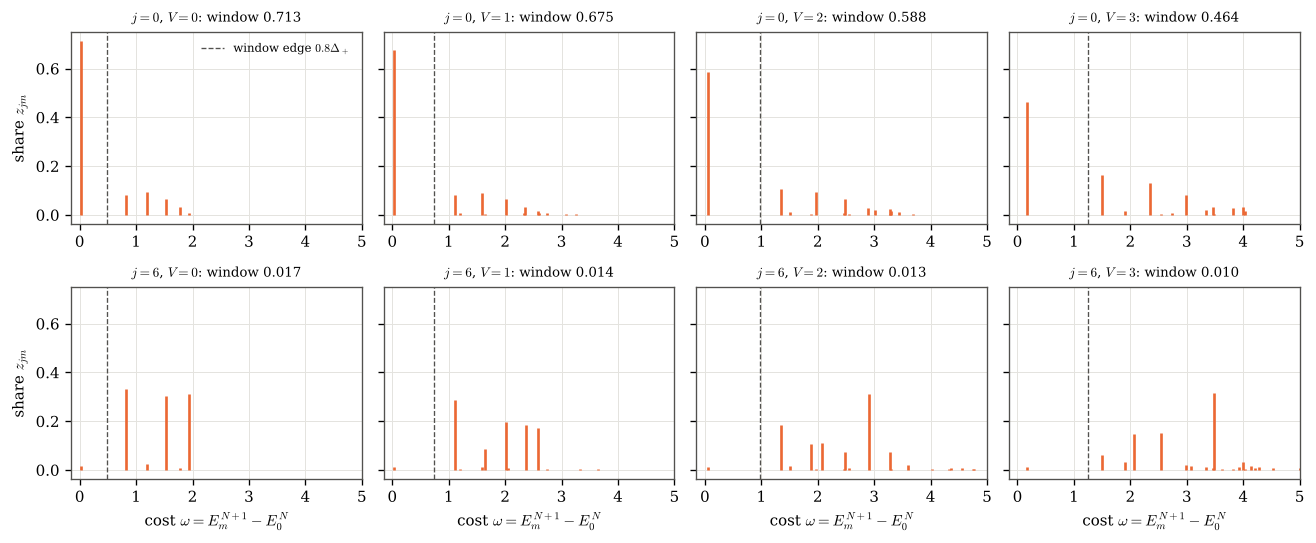

In [46]:
J_C = 12 // 2
fig, axes = plt.subplots(2, 4, figsize=(11, 4.6), sharex=True, sharey=True)
for row, j in zip(axes, [0, J_C]):
    for ax, V in zip(row, [0.0, 1.0, 2.0, 3.0]):
        om, w = site_spectra[(12, -0.30, V)][j]
        Wc = windows[(12, -0.30, V, F_WINDOW)]
        ax.vlines(om, 0, w / w.sum(), color=COLORS[0.30], lw=1.6)
        ax.axvline(Wc, ls="--", color=GRAY, lw=0.8)
        ax.set_xlim(-0.15, 5)
        ax.set_title(rf"$j={j}$, $V={V:g}$: window {w[om < Wc].sum() / w.sum():.3f}", fontsize=8)
for ax in axes.flat:
    ax.tick_params(labelbottom=True)
for ax in axes[-1]:
    ax.set_xlabel(r"cost $\omega=E^{N+1}_m-E^N_0$")
for ax in axes[:, 0]:
    ax.set_ylabel(r"share $z_{jm}$")
axes[0, 0].plot([], [], ls="--", color=GRAY, lw=0.8, label=r"window edge $0.8\Delta_+$")
axes[0, 0].legend(fontsize=7, loc="upper right")
fig.tight_layout()
savefig(fig, "step3_edge_centre")
plt.show()

### 3.9 Broadened spectra, for presentation only (guide item 1)

Each line is replaced by a Lorentzian of width $\eta$, $\sum_m z_{0m}\,\frac{\eta/\pi}{(\omega-\omega_m)^2+\eta^2}$, with $\eta=0.02,0.01,0.005$. This is only a way of drawing the lines: the width is chosen by us and is not a lifetime. $L=12$, $j=0$, $\delta=-0.30$.

saved figures/step3_broadened.pdf


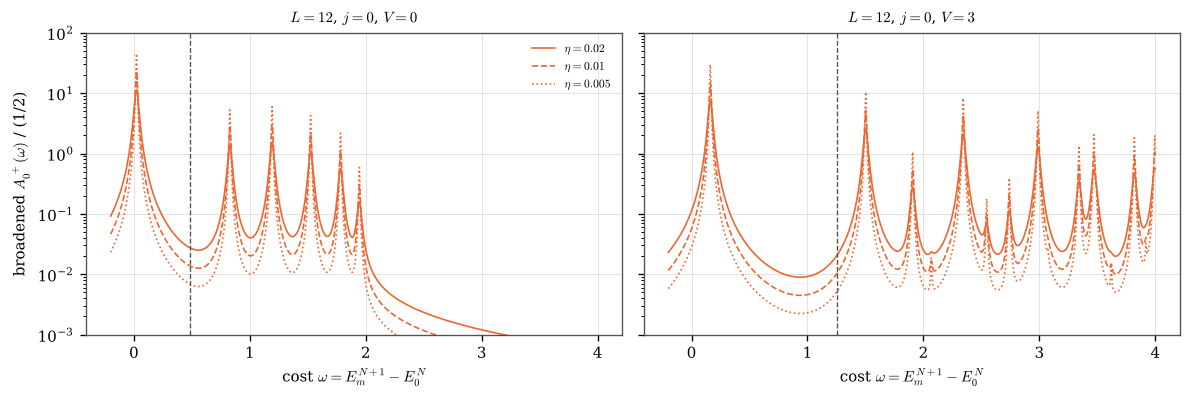

In [47]:
def broaden(omega, w, x, eta):
    """sum_m w_m (eta/pi) / ((x - omega_m)^2 + eta^2) on the grid x: presentation only, not a physical lifetime."""
    return (w[None, :] * (eta / np.pi) / ((x[:, None] - omega[None, :]) ** 2 + eta ** 2)).sum(axis=1)


x = np.linspace(-0.2, 4.0, 8001)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for ax, V in zip(axes, [0.0, 3.0]):
    om, w = spectra[(12, -0.30, V)]
    for eta, ls in zip(WIDTHS, ["-", "--", ":"]):
        ax.semilogy(x, broaden(om, w / w.sum(), x, eta), ls, color=COLORS[0.30], lw=1, label=rf"$\eta={eta}$")
    ax.axvline(windows[(12, -0.30, V, F_WINDOW)], ls="--", color=GRAY, lw=0.8)
    ax.set_ylim(1e-3, 1e2)
    ax.set_xlabel(r"cost $\omega=E^{N+1}_m-E^N_0$"); ax.set_title(rf"$L=12$, $j=0$, $V={V:g}$", fontsize=9)
axes[0].set_ylabel(r"broadened $A^+_0(\omega)$ / (1/2)"); axes[0].legend(fontsize=7)
fig.tight_layout()
savefig(fig, "step3_broadened")
plt.show()

### Step 3 summary

In [48]:
step3 = {name: c for name, c in CHECKS.items() if name.startswith("S3 ")}
n_pass = sum(c["pass"] for c in step3.values())
print(f"Step 3: {n_pass}/{len(step3)} checks passed")
for name, c in step3.items():
    if not c["pass"]:
        print("  FAILED:", name)
pd.DataFrame([{"check": name, "passed": c["pass"], "worst_deviation": c["value"]} for name, c in step3.items()]).to_csv(
    DATA_DIR / "step3_checks.csv", index=False, float_format="%.3e")

Step 3: 14/14 checks passed


---
## Step 4. Watch an edge particle evolve

**Question.** Step 3 resolved $c_0^\dagger|\Omega_N\rangle$ into eigenstates of sector $N+1$. Here the same state is evolved in time. Does the added particle stay at the edge (localisation), and does it stay one excitation (coherence)?

**Preparation and evolution** (guide Eq. A.6). With $\Omega_N$ selected by the Step 2 rule,
$$|\Psi(0)\rangle=\frac{c_j^\dagger|\Omega_N\rangle}{\sqrt{1-\langle n_j\rangle}},\qquad |\Psi(t)\rangle=e^{-i(H_{N+1}-E_0^N)t}\,|\Psi(0)\rangle .$$
$j=0$ is the edge. The control injects at $j_c=2\lfloor L/4\rfloor$, the even site nearest the centre, so that every $L$ injects into the same local environment. Keeping $E_0^N$ in the propagator makes the return amplitude a complex number that is compared with Step 3 phase included.

**Observables** (guide Eqs. A.7-A.9):
$$\Delta n_j(t)=\langle\Psi(t)|n_j|\Psi(t)\rangle-\langle\Omega_N|n_j|\Omega_N\rangle,\qquad Q_{\rm edge}(t)=\sum_{j<\ell_e}\Delta n_j(t),\quad \ell_e=2,4,$$
$$G(t)=\langle\Psi(0)|\Psi(t)\rangle=\sum_m z_{jm}\,e^{-i\omega_m t},\qquad P_{\rm return}(t)=|G(t)|^2,$$
with $\omega_m$ and $z_{jm}=w_{jm}/(1-\langle n_j\rangle)$ the lines of Step 3.

**Taken from Steps 1-3, not rebuilt.** Step 2: `hamiltonian`, `c_dag`, `occupations`, `sector_basis`, `lowest`, `select_ground_state`, `apply_C`, `ring_gap`, the selected states `STATES` and the saved grid `data/step2_grid.csv` ($E_0^N$, neutral gap, ring $\Delta_+$). Step 3: the lines `site_spectra` (full spectrum, $L=8,12$) and `lanczos` ($L=16,18$), `lanczos_spectrum`, `addition_spectra_lanczos`, `merge_lines`, the window `F_WINDOW`, `F_SCAN`, and the tables `z0_table`, `lanczos_table`. Steps 1-2: `hopping_matrix`, `weak_strong`, `filled_correlations` for an independent $V=0$ route.

**Guide items.**
1. Krylov evolution at $L=8,12,16$ with $\Delta t=0.05$, $0\le t\le8$; full diagonalisation at $L=8$ (and 12); the propagation tolerance halved (4.2, 4.3).
2. Controls: injection near the centre, and the opposite dimerisation $\delta=+0.30$ (every run).
3. Norm, energy, $\sum_j\Delta n_j=1$, and whole density profiles, not only $Q_{\rm edge}$ (4.2, 4.10).
4. Boundary reflections and the two-edge beating. The interval free of finite-size returns is certified against the next larger chain, so $L=18,20$ are added, and the time range is extended to $t=16$ only there (4.4-4.6).
5. The filtered preparation, projected onto Step 3's edge window, with $z_0(\mathcal W)$ (4.2, 4.9).

**Figures** (PDF in `figures/`): `step4_validation`, `step4_spacetime_density`, `step4_time_traces`, `step4_finite_size_beating` and `step4_summary_vs_V` are the five figures of the Step 4 report (`fig15`-`fig19` in its LaTeX source); `step4_s1_validation` to `step4_s5_filtered` are the five figures of the short Step 4 report (`figS4_1`-`figS4_5`).

**Status.** Items 1-5 on $L=8,12,16$, $\delta=\pm0.30$, $V=0,0.5,1,2,3$, edge and centre injection; $L=18$ on the same grid and $L=20$ at $V=0,1,3$ for item 4. Every check prints `[pass]` or `[FAIL]` and is counted in the Step 4 summary. About 15 minutes.

In [49]:
# ---- Step 4 parameters (edit these) ----
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D
from scipy.linalg import eigh_tridiagonal

L_S4 = L_S3 + [16]                    # Krylov evolution (guide item 1): L = 8, 12, 16
L_LADDER = [18, 20]                   # only to certify the finite-size-free interval (guide item 4)
DELTA_S4 = DELTA_S3                   # -0.30: weak end bonds; +0.30: opposite dimerisation (control, item 2)
V_S4 = V_S3                           # 0, 0.5, 1, 2, 3
V_BIG = [0.0, 1.0, 3.0]               # V carried to L = 20 and shown in the figures
DT, T_MAX, T_EXT = 0.05, 8.0, 16.0    # output spacing and time range (item 1); T_EXT at L = 18, 20 only
KRYLOV_TOL = 1e-10                    # Krylov error allowed per unit time (production); halved as a check
KRYLOV_M_MAX = 40                     # Krylov dimension cap before a step is split in two
BOUND = KRYLOV_TOL * T_MAX            # accumulated error bound, the tolerance of the A checks
L_EXACT = [8, 12]                     # full-diagonalisation reference (the guide asks for L = 8)
ELL_E = (2, 4)                        # edge-region sizes l_e of Q_edge (item 3)
EPS_VISIBLE, EPS_TIGHT = 0.01, 1e-3   # a departure between sizes is "visible" above EPS_VISIBLE (item 4)
TOLS_SCAN = [1e-3, 1e-5, 1e-7, 1e-9, 1e-10, 5e-11]
K_SPEC = max(K_LANCZOS)               # Lanczos vectors of Step 3's spectral measure at L = 16 (400)
T_BEAT = 300.0                        # exact evolution at L = 8 for the beating check (item 4)

# figure style: the Step 1-3 palette, extended for up to six curves
S4_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#6250d6", "#c2417f", GRAY]
S4_L_COLORS = {**L_COLORS, 20: "#c2417f"}
S4_LS = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1))]
S4_MARKERS = ["o", "s", "^", "D", "v", "P"]
S4_DIVERGING = LinearSegmentedColormap.from_list("s4_div", ["#2a78d6", "#f4f3f0", "#eb6834"])

### 4.1 Functions

`prepare` builds $|\Psi(0)\rangle$ from the selected $\Omega_N$ with Step 2's `c_dag`, which carries the sign string. It also stores $\langle n_k\rangle$ and $\langle\delta n_j\,\delta n_k\rangle_c$ of $\Omega_N$ for the exact $t=0$ identities. $\Omega_N$ is Step 2's `STATES` entry wherever Step 2 ran the point; only $L=20$ is new, and it goes through the same `lowest` and `select_ground_state`.

**Krylov propagation** (short-iterative Lanczos). Each output step $\Delta t$ builds orthonormal vectors $q_0=\psi/\|\psi\|,q_1,\dots$ by applying $H_{N+1}-E_0^N$, with full reorthogonalisation done twice, as in Step 3's `lanczos_spectrum`. In this basis $H$ is a tridiagonal $T_m$, and
$$e^{-i(H-E_0^N)\Delta t}\psi\approx\|\psi\|\,Q_m\,e^{-iT_m\Delta t}e_1 .$$
The dimension $m$ grows until the a-posteriori error estimate $\mathrm{err}_m=\|\psi\|\,\beta_m\,|e_m^{T}e^{-iT_m\Delta t}e_1|$ falls below `KRYLOV_TOL`$\cdot\Delta t$; at `KRYLOV_M_MAX` the step is split in two. The tolerance is an error per unit time, so the bound after time $t$ is `KRYLOV_TOL`$\cdot t$, i.e. `BOUND` $=8\times10^{-10}$ at $t=8$.

**Three references.** `evolve_exact`: full diagonalisation of $H_{N+1}$. `spectral_amplitude`: Step 3's lines, $G(t)=\sum_m z_{jm}e^{-i\omega_mt}$. `free_trajectory`: $V=0$ without a Fock space. $c_j^\dagger$ puts a particle into $\chi(0)=(1-C)e_j/\sqrt{1-C_{jj}}$, with $C$ = `filled_correlations` (the occupied part of $e_j$ is Pauli-blocked); then $\chi(t)=e^{-iht}\chi(0)$, $G(t)=\chi(0)^\dagger\chi(t)$ and $\Delta n_j(t)=|\chi_j(t)|^2$.

**Exact identities**, for any $V$: $\sum_j\Delta n_j(t)=1$; $\Delta n_j(0)=1-\langle n_j\rangle$ at the injection site and $-\langle\delta n_j\delta n_k\rangle_c/(1-\langle n_j\rangle)$ at every other site $k$; norm and $\langle H_{N+1}\rangle$ are conserved.

**Filtered preparation** (guide item 5). $|\Psi(0)\rangle$ projected onto the eigenstates of sector $N+1$ with $0\le\omega<f\Delta_+$, then renormalised. $f$ = `F_WINDOW` unless Step 3 finds more than one line with weight in that window at $j=0$; then the widest $f$ in `F_SCAN` that holds one line. The preparation probability must equal Step 3's $z_0(\mathcal W)$. If the window is empty ($\delta=+0.30$) there is nothing to filter onto.

**Finite-size-free interval** (guide item 4). Two chains $L<L'$ differ already at $t=0$ by a static amount $s$ (the edge-edge hybridisation of $\Omega_N$, of order $e^{-L/\xi}$), which relaxes over a short transient. A **return** is a change since $t=0$ that differs between the two chains by more than $\varepsilon+2s$, in $P_{\rm return}$ or in $Q_{\rm edge}$ ($\ell_e=2,4$; for centre injection the $\ell_e$ sites around $j_c$), with $\varepsilon$ = `EPS_VISIBLE`. The first such time is $t_{\rm fs}$. If $s>\varepsilon$ the smaller chain's initial state is itself not converged, and no interval is claimed.

In [50]:
S2_GRID = pd.read_csv(DATA_DIR / "step2_grid.csv")      # Step 2's saved grid: E_0^N, gaps, ring Delta_+
_LOW_N, _DELTA_PLUS = {}, {}


def centre_site(L):
    """Even site nearest the centre (strong bond on its left at every L)."""
    return 2 * (L // 4)


def s2_row(L, delta, V, boundary="open"):
    """Step 2's grid row at (L, delta, V), or None where Step 2 did not run the point."""
    hit = S2_GRID[(S2_GRID.L == L) & np.isclose(S2_GRID.delta, delta) & np.isclose(S2_GRID.V, V)
                  & (S2_GRID.boundary == boundary)]
    return hit.iloc[0] if len(hit) else None


def low_N(L, delta, V):
    """Lowest K_N + K_EXTRA levels of sector N from Step 2's lowest() (cached)."""
    if (L, delta, V) not in _LOW_N:
        _LOW_N[(L, delta, V)] = lowest(hamiltonian(L, L // 2, delta, V), K_N + K_EXTRA)
    return _LOW_N[(L, delta, V)]


def ground_state_N(L, delta, V):
    """Omega_N by the Step 2 rule: STATES where Step 2 ran the point, the same rule here otherwise (L = 20)."""
    key = state_key(L, delta, V)
    if key in STATES:
        return STATES[key]
    E, U, _ = low_N(L, delta, V)
    return select_ground_state(E, U, L, L // 2)[0]


def neutral_gap(L, delta, V):
    """E_1^N - E_0^N: Step 2's grid, or low_N where Step 2 has no point."""
    row = s2_row(L, delta, V)
    if row is not None:
        return float(row.neutral_gap)
    E = low_N(L, delta, V)[0]
    return E[1] - E[0]


def delta_plus(L, delta, V):
    """Ring threshold Delta_+ at the same (L, delta, V): Step 2's grid, or Step 2's ring_gap (L = 20)."""
    row = s2_row(L, delta, V, "periodic")
    if row is not None:
        return float(row.delta_plus)
    if (L, delta, V) not in _DELTA_PLUS:
        _DELTA_PLUS[(L, delta, V)] = ring_gap(L, delta, V)["delta_plus"]
    return _DELTA_PLUS[(L, delta, V)]


def prepare(L, delta, V, site=0):
    """|Psi(0)> = c_site^dag |Omega_N> / sqrt(1 - <n_site>) (guide Eq. A.6), with what the checks need."""
    N = L // 2
    psi = ground_state_N(L, delta, V)
    H_N = hamiltonian(L, N, delta, V)
    E0 = psi @ (H_N @ psi)                                          # <Omega|H|Omega>, as in Step 3
    occ = occupations(sector_basis(L, N), L).astype(float)
    n_ref = occ.T @ psi**2                                           # <n_k> = densities(psi, L, N)
    corr = occ.T @ (occ[:, site] * psi**2) - n_ref[site] * n_ref     # <dn_site dn_k>_c
    v = c_dag(L, N, site) @ psi                                      # Step 2's c^dag, sign string included
    weight = v @ v                                                   # = 1 - <n_site> (Step 3 sum rule)
    return {"L": L, "N": N, "delta": delta, "V": V, "site": site, "filtered": False,
            "psi0": v / np.sqrt(weight) + 0j, "H": hamiltonian(L, N + 1, delta, V), "E0": E0,
            "occ": occupations(sector_basis(L, N + 1), L).astype(float), "n_ref": n_ref, "corr": corr,
            "weight": weight, "gs_residual": np.linalg.norm(H_N @ psi - E0 * psi),
            "gs_C": psi @ apply_C(psi, L, N), "gs_gap": neutral_gap(L, delta, V)}


def observe(psi, prep):
    """G = <Psi(0)|psi>, Delta n_j, norm and <H_{N+1}> - E_0^N of one state."""
    prob = np.abs(psi) ** 2
    energy = np.vdot(psi, prep["H"] @ psi).real - prep["E0"]
    return np.vdot(prep["psi0"], psi), prep["occ"].T @ prob - prep["n_ref"], prob.sum(), energy


def trajectory(prep, times, states, method, **info):
    """Observables of a sequence of states (a generator: states are not kept)."""
    obs = [observe(psi, prep) for psi in states]
    return {"prep": prep, "method": method, "t": times, "G": np.array([o[0] for o in obs]),
            "dn": np.array([o[1] for o in obs]), "norm": np.array([o[2] for o in obs]),
            "energy": np.array([o[3] for o in obs]), **info}


def time_grid(t_max):
    return np.round(np.arange(0.0, t_max + DT / 2, DT), 12)


def krylov_step(H, psi, dt, shift, tol, m_max):
    """One short-iterative-Lanczos step exp(-i (H - shift) dt) psi: (result or None, error estimate, m)."""
    beta0 = np.linalg.norm(psi)
    Q = np.empty((m_max + 1, psi.size), dtype=complex)                # rows: Krylov vectors q_0, q_1, ...
    Q[0] = psi / beta0
    alpha, beta = [], []
    for m in range(m_max):
        r = H @ Q[m] - shift * Q[m]
        alpha.append(np.vdot(Q[m], r).real)
        for _ in range(2):                                           # remove every earlier direction, twice
            r -= Q[:m + 1].T @ (Q[:m + 1].conj() @ r)
        b = np.linalg.norm(r)
        theta, S = eigh_tridiagonal(np.array(alpha), np.array(beta)) if m else (np.array(alpha), np.ones((1, 1)))
        u = S @ (np.exp(-1j * theta * dt) * S[0])                    # exp(-i T_m dt) e_1
        err = beta0 * b * abs(u[-1])
        if b < 1e-13 or err <= tol * dt:
            return beta0 * (Q[:m + 1].T @ u), err, m + 1
        beta.append(b)
        Q[m + 1] = r / b
    return None, err, m_max


def evolve(prep, t_max=T_MAX, tol=KRYLOV_TOL, m_max=KRYLOV_M_MAX):
    """Guide item 1: Krylov evolution with output every DT."""
    times = time_grid(t_max)
    stats = {"m_max_used": 0, "vectors": 0, "splits": 0, "err_sum": 0.0}

    def advance(psi, h):
        out, err, m = krylov_step(prep["H"], psi, h, prep["E0"], tol, m_max)
        if out is None:                                              # dimension cap: two half steps
            stats["splits"] += 1
            return advance(advance(psi, h / 2), h / 2)
        stats["m_max_used"] = max(stats["m_max_used"], m)
        stats["vectors"] += m
        stats["err_sum"] += err
        return out

    def states():
        psi = prep["psi0"]
        yield psi
        for k in range(1, len(times)):
            psi = advance(psi, times[k] - times[k - 1])
            yield psi

    tr = trajectory(prep, times, states(), "krylov", tol=tol)
    return {**tr, **stats}


def evolve_exact(prep, t_max=T_MAX):
    """Full-diagonalisation reference (guide item 1)."""
    times = time_grid(t_max)
    E, U = np.linalg.eigh(prep["H"].toarray())
    c = U.T @ prep["psi0"]
    return trajectory(prep, times, (U @ (c * np.exp(-1j * (E - prep["E0"]) * t)) for t in times), "exact", tol=0.0)


def P_return(tr):
    return np.abs(tr["G"]) ** 2


def Q_edge(tr, ell):
    """Excess charge on sites 0 .. ell-1 (guide Eq. A.8)."""
    return tr["dn"][:, :ell].sum(axis=1)


def Q_far(tr, ell):
    """Excess charge on the last ell sites (the far edge)."""
    return tr["dn"][:, -ell:].sum(axis=1)


def Q_local(tr, ell):
    """Charge near the injection site: Q_edge for j = 0, the ell sites around j otherwise."""
    j = tr["prep"]["site"]
    lo = max(0, j - ell // 2) if j else 0
    return tr["dn"][:, lo:lo + ell].sum(axis=1)


def compare(a, b):
    """Largest differences between two trajectories on their common times."""
    n = min(len(a["t"]), len(b["t"]))
    return {"G": np.max(np.abs(a["G"][:n] - b["G"][:n])), "P": np.max(np.abs(P_return(a)[:n] - P_return(b)[:n])),
            "dn": np.max(np.abs(a["dn"][:n] - b["dn"][:n])), "energy": np.max(np.abs(a["energy"][:n] - b["energy"][:n]))}


def step3_lines(L, delta, V, site, k=K_SPEC):
    """Step 3's lines (omega_m, w_jm) at this site: site_spectra (full, L <= 12), else the Lanczos measure."""
    if (L, delta, V) in site_spectra:
        return site_spectra[(L, delta, V)][site]
    if site == 0 and k in lanczos.get((L, delta, V), {}):
        return lanczos[(L, delta, V)][k]
    return addition_spectra_lanczos(L, delta, V, [site], k)[0]


def spectral_amplitude(lines, times):
    """G(t) = sum_m z_jm exp(-i omega_m t), z_jm = w_jm / sum_m w_jm = w_jm / (1 - <n_j>)."""
    om, w = lines
    return np.exp(-1j * np.outer(times, om)) @ (w / w.sum())


def free_trajectory(L, delta, site, times):
    """V = 0 from Step 1's L x L matrices only: G(t) and Delta n_j(t) = |chi_j(t)|^2."""
    C = filled_correlations(L, delta)                                # Step 1 orbitals, bonding orbital for delta < 0
    eps, phi = np.linalg.eigh(hopping_matrix(L, delta))
    chi0 = (np.eye(L)[site] - C[:, site]) / np.sqrt(1 - C[site, site])
    chi = phi @ ((phi.T @ chi0)[:, None] * np.exp(-1j * np.outer(eps, times)))
    return chi0 @ chi, (np.abs(chi) ** 2).T


def step3_window(prep):
    """Step 3's edge window at j = 0: factor f, upper edge f Delta_+, lines with weight inside, z_0(W).
    f = F_WINDOW unless that window holds more than one line; then the widest f in F_SCAN holding one."""
    L, delta, V = prep["L"], prep["delta"], prep["V"]
    dp = delta_plus(L, delta, V)
    if L in L_S3 + L_LANCZOS:
        om, w = step3_lines(L, delta, V, 0)
    else:                                                            # L = 20: Step 3's measure, built here
        theta, w = lanczos_spectrum(prep["H"], np.sqrt(prep["weight"]) * prep["psi0"].real, K_PROFILE)
        om = theta - prep["E0"]
    om_c, _ = merge_lines(om, w, w_min=1e-10)
    count = {f: int(np.sum(om_c < f * dp)) for f in F_SCAN}
    single = [f for f in F_SCAN if count[f] == 1]
    f = F_WINDOW if count[F_WINDOW] <= 1 or not single else max(single)
    return {"f": f, "omega_hi": f * dp, "delta_plus": dp, "lines": count[f], "z0": w[om < f * dp].sum() / w.sum()}


def step3_z0(L, delta, V, f):
    """z_0(W) as Step 3 tabulated it (z0_table: L = 8, 12; lanczos_table: L = 16, 18), else None."""
    for table in (z0_table, lanczos_table):
        hit = table[(table.L == L) & np.isclose(table.delta, delta) & np.isclose(table.V, V)]
        if len(hit):
            return float(hit[f"z0_f{f:.1f}"].iloc[0])
    return None


def prepare_filtered(prep):
    """Guide item 5: Psi(0) projected onto the sector N+1 eigenstates in Step 3's edge window, renormalised.
    Returns (None, window) when the window is empty."""
    win = step3_window(prep)
    if win["lines"] == 0:
        return None, win
    E, U, _ = lowest(prep["H"], win["lines"] + 6)
    om = E - prep["E0"]
    inside = U[:, (om >= 0) & (om < win["omega_hi"])]
    amp = inside.T @ prep["psi0"]
    keep = np.abs(amp) ** 2 > 1e-12                                  # lines with weight only
    proj = inside[:, keep] @ amp[keep]
    weight = np.vdot(proj, proj).real
    return {**prep, "psi0": proj / np.sqrt(weight), "weight": weight, "filtered": True, "window": win}, win


def finite_size_time(small, big, eps=EPS_VISIBLE):
    """First time at which `small` departs visibly from the larger chain `big` (guide item 4)."""
    n = min(len(small["t"]), len(big["t"]))
    series = {"P": (P_return(small)[:n], P_return(big)[:n])}
    series.update({f"Q{ell}": (Q_local(small, ell)[:n], Q_local(big, ell)[:n]) for ell in ELL_E})
    first, offset = {}, {}
    for name, (x, y) in series.items():
        offset[name] = abs(x[0] - y[0])                              # static offset s: the initial states differ
        late = np.flatnonzero(np.abs((x - x[0]) - (y - y[0])) > eps + 2 * offset[name])
        first[name] = small["t"][late[0]] if late.size else np.inf
    t_fs, s = min(first.values()), max(offset.values())
    return {"t_fs": t_fs if np.isfinite(t_fs) else small["t"][n - 1], "reached": bool(np.isfinite(t_fs)),
            "first": first, "offset": offset, "static_offset_max": s, "initial_state_ok": bool(s < eps),
            "t_common_max": small["t"][n - 1]}


def late_window(t_fs, t_max, reached):
    """Late-time averaging interval: second half of [0, min(t_fs, t_max)], from t >= 2; None if shorter than 1."""
    t_b = min(t_fs, t_max) if reached else t_max
    t_a = max(2.0, 0.5 * t_b)
    return (t_a, t_b) if t_b - t_a >= 1.0 else (np.nan, np.nan)


def round_trip(L, ell=4):
    """Sites from the injection site to the far end and back into the observation region [0, ell)."""
    return 2 * (L - 1) - (ell - 1)


def free_front_velocity(delta):
    """V = 0 maximal group velocity of the upper band, in sites per unit time: 2 min(J_w, J_s)."""
    J_w, J_s = weak_strong(delta)
    k = np.linspace(0, np.pi, 200001)
    return 2 * np.max(J_w * J_s * np.sin(k) / np.sqrt(J_w**2 + J_s**2 + 2 * J_w * J_s * np.cos(k)))


def bound_lines(prep, dp, k=12):
    """Every line of sector N+1 below Delta_+ that the added particle reaches: omega, z, and its charge."""
    E, U, _ = lowest(prep["H"], k)
    out = []
    for m in np.flatnonzero(E - prep["E0"] < dp):
        z = abs(U[:, m] @ prep["psi0"]) ** 2
        if z > 1e-8:
            dn = prep["occ"].T @ U[:, m] ** 2 - prep["n_ref"]
            out.append({"omega": E[m] - prep["E0"], "z": z, "q2": dn[:2].sum(), "q4": dn[:4].sum(),
                        "q_far4": dn[-4:].sum(), "q_left_half": dn[:prep["L"] // 2].sum()})
    return out


def far_edge_response(L, delta, V):
    """Delta n_{L-1}(0) = -<dn_0 dn_{L-1}>_c / (1 - <n_0>) for the selected Omega_N and for the
    left- and right-loaded combinations of the N-sector doublet (split by ~exp(-L/xi))."""
    N = L // 2
    occ = occupations(sector_basis(L, N), L).astype(float)
    pair = low_N(L, delta, V)[1][:, :2]
    imbalance = occ[:, :N].sum(axis=1) - occ[:, N:].sum(axis=1)
    D = pair.T @ (imbalance[:, None] * pair)
    rot = np.linalg.eigh(0.5 * (D + D.T))[1]

    def response(psi):
        n = occ.T @ psi**2
        conn = (occ[:, 0] * occ[:, -1] * psi**2).sum() - n[0] * n[-1]
        return {"dn_far": -conn / (1 - n[0]), "n0": n[0]}

    return {"selected": response(ground_state_N(L, delta, V)), "right_loaded": response(pair @ rot[:, 0]),
            "left_loaded": response(pair @ rot[:, 1]), "doublet_splitting": neutral_gap(L, delta, V)}

### 4.2 Evolution at $L=8$, then $L=12,16$ (guide items 1-3 and 5)

Every point runs edge and centre injection. Each run records:
- the Krylov trajectory with `KRYLOV_TOL`, and again with `KRYLOV_TOL/2` (A3);
- full diagonalisation at $L=8,12$ (A1) and Step 3's spectral sum at $L=8,12$ (full spectrum, every site) and $L=16$ (Lanczos measure, `K_SPEC` vectors) (A2);
- norm, energy and $\sum_j\Delta n_j$ (B1), the $t=0$ identities (B2), and at $V=0$ the one-body route (B3);
- for edge injection, the filtered preparation (C1-C3).

Checks:
- **A0:** $\Omega_N$ is Step 2's state: $C=+1$, residual below $10^{-9}$, and $E_0^N$ equal to Step 2's `step2_grid.csv`.
- **A1:** Krylov = full diagonalisation: $G(t)$, $P_{\rm return}$ and $\Delta n_j$ within `BOUND`.
- **A2:** Krylov $G(t)$ = $\sum_mz_{jm}e^{-i\omega_mt}$ from Step 3's lines, complex amplitude, phase included, within `BOUND`.
- **A3:** halving the tolerance changes nothing beyond `BOUND`.
- **B1:** $|\langle\Psi|\Psi\rangle-1|$, $|E(t)-E(0)|$ and $|\sum_j\Delta n_j-1|$ below $10^{-10}$. **B2:** the $t=0$ identities to $10^{-12}$. **B3:** at $V=0$, $G$ and $\Delta n_j$ equal the one-body route within `BOUND`.
- **C1:** the filtered preparation probability equals Step 3's $z_0(\mathcal W)$ (`z0_table`, `lanczos_table`) at the same $f$. **C2:** the filtered state does not evolve: $P_{\rm return}=1$ and static $\Delta n_j$, with exactly $\tfrac12$ of its charge in each half. **C3:** for $\delta=+0.30$ the window is empty.

As in Step 2, $L=8$ runs first, and the larger sizes only run if every check passes there.

In [51]:
RUNS, FILTERED, TRAJ = [], [], {}


def traj_key(L, delta, V, site, kind="electron"):
    return (L, round(delta, 2), round(V, 2), "edge" if site == 0 else "centre", kind)


def run_one(L, delta, V, site, t_max=T_MAX, halve=True, spectral=True):
    """One Krylov run and every per-run check of guide items 1-3: one row of the run table."""
    prep = prepare(L, delta, V, site)
    tr = evolve(prep, t_max)
    t0 = -prep["corr"] / prep["weight"]                               # Delta n_k(0), k != site
    t0[site] = prep["weight"]                                         # = 1 - <n_site>
    s2 = s2_row(L, delta, V)
    row = {"L": L, "delta": delta, "V": V, "site": site, "injection": "edge" if site == 0 else "centre",
           "kind": "electron", "t_max": t_max, "tol": tr["tol"], "dim_Np1": prep["H"].shape[0],
           "prep_weight": prep["weight"], "E0": prep["E0"],
           "E0_step2_dev": abs(prep["E0"] - s2.E0) if s2 is not None else np.nan,
           "gs_C": prep["gs_C"], "gs_residual": prep["gs_residual"], "neutral_gap_N": prep["gs_gap"],
           "krylov_dim_max": tr["m_max_used"], "krylov_vectors": tr["vectors"], "krylov_splits": tr["splits"],
           "krylov_err_estimate": tr["err_sum"], "norm_drift": np.max(np.abs(tr["norm"] - 1)),
           "energy_drift": np.max(np.abs(tr["energy"] - tr["energy"][0])),
           "sum_dn_minus_1": np.max(np.abs(tr["dn"].sum(axis=1) - 1)),
           "t0_identity_err": np.max(np.abs(tr["dn"][0] - t0)),
           "Q2_0": Q_local(tr, 2)[0], "Q4_0": Q_local(tr, 4)[0], "Qfar4_0": Q_far(tr, 4)[0], "dn_far_0": tr["dn"][0, -1]}
    if halve:
        half = evolve(prep, t_max, tol=KRYLOV_TOL / 2)
        c = compare(tr, half)
        row.update(halving_G=c["G"], halving_P=c["P"], halving_dn=c["dn"],
                   halving_extra_vectors=half["vectors"] - tr["vectors"])
    if L in L_EXACT:
        c = compare(tr, evolve_exact(prep, t_max))
        row.update(exact_G=c["G"], exact_P=c["P"], exact_dn=c["dn"])
    if spectral:
        G = spectral_amplitude(step3_lines(L, delta, V, site), tr["t"])
        row.update(spectral_method="full" if L in L_S3 else f"lanczos {K_SPEC}",
                   spectral_G=np.max(np.abs(tr["G"] - G)), spectral_P=np.max(np.abs(P_return(tr) - np.abs(G) ** 2)))
    if V == 0:
        G, dn = free_trajectory(L, delta, site, tr["t"])
        row.update(free_G=np.max(np.abs(tr["G"] - G)), free_dn=np.max(np.abs(tr["dn"] - dn)))
    return row, tr


def run_filtered(prep, evolve_it=True):
    """Guide item 5: the filtered edge preparation; its charges come from the state itself."""
    fprep, win = prepare_filtered(prep)
    L = prep["L"]
    row = {"L": L, "delta": prep["delta"], "V": prep["V"], "site": 0, "injection": "edge", "kind": "filtered",
           "window_factor": win["f"], "window_lines": win["lines"], "window_empty": fprep is None,
           "z0W_step3": step3_z0(L, prep["delta"], prep["V"], win["f"]), "z0W_window": win["z0"]}
    if fprep is None:
        return {**row, "z0W": 0.0}, None
    dn = prep["occ"].T @ np.abs(fprep["psi0"]) ** 2 - prep["n_ref"]
    row.update(z0W=fprep["weight"], q2=dn[:2].sum(), q4=dn[:4].sum(), q_left_half=dn[:L // 2].sum(),
               q_right_half=dn[L // 2:].sum())
    if not evolve_it:
        return row, None
    tr = evolve(fprep)
    row.update(P_return_min=P_return(tr).min(), dn_static_dev=np.max(np.abs(tr["dn"] - tr["dn"][0])),
               norm_drift=np.max(np.abs(tr["norm"] - 1)))
    return row, tr


def run_point(L, delta, V):
    """Edge and centre injection at one point of the main grid, and the filtered edge preparation."""
    for site in (0, centre_site(L)):
        row, tr = run_one(L, delta, V, site)
        RUNS.append(row)
        TRAJ[traj_key(L, delta, V, site)] = tr
        if site == 0:
            frow, ftr = run_filtered(tr["prep"])
            FILTERED.append(frow)
            if ftr is not None:
                TRAJ[traj_key(L, delta, V, 0, "filtered")] = ftr


def worst(rows, col):
    vals = [r[col] for r in rows if col in r and np.isfinite(r[col])]
    return max(vals) if vals else np.nan


def check_runs(sizes, label):
    """Checks A0-A3, B1-B3 and C1-C3 on the runs and filtered preparations at these sizes."""
    rr = [r for r in RUNS if r["L"] in sizes]
    ff = [r for r in FILTERED if r["L"] in sizes]
    dev = max(worst(rr, "E0_step2_dev"), worst(rr, "gs_residual"))
    check(f"S4 A0 [{label}]: Omega_N = Step 2's state: C = +1, residual < 1e-9, E_0^N = step2_grid.csv",
          all(abs(r["gs_C"] - 1) < 1e-9 for r in rr) and dev < 1e-9, dev)
    if any(L in L_EXACT for L in sizes):
        dev = max(worst(rr, "exact_G"), worst(rr, "exact_P"), worst(rr, "exact_dn"))
        check(f"S4 A1 [{label}]: Krylov = full diagonalisation (G, P_return, Delta n_j), edge and centre", dev < BOUND, dev)
    if any("spectral_G" in r for r in rr):
        dev = max(worst(rr, "spectral_G"), worst(rr, "spectral_P"))
        check(f"S4 A2 [{label}]: Krylov G(t) = Step 3 spectral sum sum_m z_jm exp(-i omega_m t), phase included",
              dev < BOUND, dev)
    if any("halving_G" in r for r in rr):
        dev = max(worst(rr, "halving_G"), worst(rr, "halving_dn"))
        check(f"S4 A3 [{label}]: halving the Krylov tolerance changes G and Delta n_j by less than BOUND", dev < BOUND, dev)
    dev = max(worst(rr, "norm_drift"), worst(rr, "energy_drift"), worst(rr, "sum_dn_minus_1"))
    check(f"S4 B1 [{label}]: norm, <H_(N+1)> and sum_j Delta n_j = 1 conserved, every run", dev < 1e-10, dev)
    dev = worst(rr, "t0_identity_err")
    check(f"S4 B2 [{label}]: t = 0 identities Delta n_j(0) = 1 - <n_j>, Delta n_k(0) = -<dn_j dn_k>_c/(1 - <n_j>)",
          dev < 1e-12, dev)
    if any("free_G" in r for r in rr):
        dev = max(worst(rr, "free_G"), worst(rr, "free_dn"))
        check(f"S4 B3 [{label}]: V = 0: G and Delta n_j = one-body route from Step 1's h (no Fock space)", dev < BOUND, dev)
    full = [r for r in ff if not r["window_empty"]]
    dev = max([abs(r["z0W"] - r["z0W_step3"]) for r in full if r["z0W_step3"] is not None]
              + [abs(r["z0W"] - r["z0W_window"]) for r in full], default=0.0)
    check(f"S4 C1 [{label}]: filtered preparation probability = Step 3 z_0(W) at the same f", dev < 1e-10, dev)
    evolved = [r for r in full if "P_return_min" in r]
    if evolved:
        dev = max(max(abs(r["P_return_min"] - 1), r["dn_static_dev"], abs(r["q_left_half"] - 0.5)) for r in evolved)
        check(f"S4 C2 [{label}]: filtered state: P_return = 1, static Delta n_j, 1/2 of its charge per half", dev < 1e-10, dev)
    empty = [r for r in ff if r["delta"] > 0]
    if empty:
        check(f"S4 C3 [{label}]: delta = +0.30: the edge window is empty, nothing to filter onto",
              all(r["window_empty"] for r in empty))


start = time.time()
for d in DELTA_S4:
    for V in V_S4:
        run_point(8, d, V)
check_runs([8], "L=8")
if not all(c["pass"] for name, c in CHECKS.items() if name.startswith("S4 ")):
    raise RuntimeError("a Step 4 check failed at L = 8: do not enlarge")

for L in L_S4[1:]:
    for d in DELTA_S4:
        for V in V_S4:
            run_point(L, d, V)
    print(f"L = {L} done ({time.time() - start:.0f} s)")
check_runs(L_S4, "L=8-16")

runs_main = pd.DataFrame(RUNS)
display(runs_main.groupby(["L", "injection"])[["norm_drift", "energy_drift", "sum_dn_minus_1", "t0_identity_err",
                                                 "halving_G", "exact_G", "spectral_G", "krylov_dim_max"]].max())
display(pd.DataFrame(FILTERED)[lambda t: ~t.window_empty][["L", "V", "window_factor", "window_lines", "z0W",
                                                             "z0W_step3", "q2", "q4", "P_return_min"]])

[pass] S4 A0 [L=8]: Omega_N = Step 2's state: C = +1, residual < 1e-9, E_0^N = step2_grid.csv   [1.61e-14]
[pass] S4 A1 [L=8]: Krylov = full diagonalisation (G, P_return, Delta n_j), edge and centre   [8.92e-13]
[pass] S4 A2 [L=8]: Krylov G(t) = Step 3 spectral sum sum_m z_jm exp(-i omega_m t), phase included   [8.93e-13]
[pass] S4 A3 [L=8]: halving the Krylov tolerance changes G and Delta n_j by less than BOUND   [8.99e-13]
[pass] S4 B1 [L=8]: norm, <H_(N+1)> and sum_j Delta n_j = 1 conserved, every run   [4.37e-13]
[pass] S4 B2 [L=8]: t = 0 identities Delta n_j(0) = 1 - <n_j>, Delta n_k(0) = -<dn_j dn_k>_c/(1 - <n_j>)   [2.14e-15]
[pass] S4 B3 [L=8]: V = 0: G and Delta n_j = one-body route from Step 1's h (no Fock space)   [3.90e-14]
[pass] S4 C1 [L=8]: filtered preparation probability = Step 3 z_0(W) at the same f   [1.78e-15]
[pass] S4 C2 [L=8]: filtered state: P_return = 1, static Delta n_j, 1/2 of its charge per half   [1.10e-14]
[pass] S4 C3 [L=8]: delta = +0.30: the edge window

L = 12 done (12 s)


L = 16 done (72 s)
[pass] S4 A0 [L=8-16]: Omega_N = Step 2's state: C = +1, residual < 1e-9, E_0^N = step2_grid.csv   [6.93e-14]
[pass] S4 A1 [L=8-16]: Krylov = full diagonalisation (G, P_return, Delta n_j), edge and centre   [1.15e-12]
[pass] S4 A2 [L=8-16]: Krylov G(t) = Step 3 spectral sum sum_m z_jm exp(-i omega_m t), phase included   [1.15e-12]
[pass] S4 A3 [L=8-16]: halving the Krylov tolerance changes G and Delta n_j by less than BOUND   [1.32e-12]
[pass] S4 B1 [L=8-16]: norm, <H_(N+1)> and sum_j Delta n_j = 1 conserved, every run   [7.89e-13]
[pass] S4 B2 [L=8-16]: t = 0 identities Delta n_j(0) = 1 - <n_j>, Delta n_k(0) = -<dn_j dn_k>_c/(1 - <n_j>)   [5.85e-15]
[pass] S4 B3 [L=8-16]: V = 0: G and Delta n_j = one-body route from Step 1's h (no Fock space)   [1.32e-12]
[pass] S4 C1 [L=8-16]: filtered preparation probability = Step 3 z_0(W) at the same f   [4.00e-15]
[pass] S4 C2 [L=8-16]: filtered state: P_return = 1, static Delta n_j, 1/2 of its charge per half   [2.19e-12]
[pas

norm_drift  energy_drift  sum_dn_minus_1  t0_identity_err   halving_G     exact_G  spectral_G  krylov_dim_max
L  injection                                                                                                               
8  centre     4.9738e-14   1.79412e-13     2.45803e-13      2.13718e-15 8.98736e-13 8.92416e-13 8.92724e-13               9
   edge       7.9714e-14   4.36984e-13      3.9746e-13      1.91513e-15 2.08039e-13 2.70691e-13 2.70829e-13               9
12 centre    5.55112e-14   3.84581e-13     3.76366e-13      3.27516e-15 1.15315e-12 1.15121e-12 1.15114e-12               9
   edge      8.83738e-14    6.1906e-13     6.02629e-13      3.27516e-15           0 9.63858e-13 9.64142e-13               9
16 centre     5.4623e-14   5.40012e-13     4.82281e-13      5.85296e-15 1.04791e-12         NaN 1.05464e-12              10
   edge      7.08322e-14   7.88702e-13     6.57696e-13      5.38458e-15 1.09697e-12         NaN 1.09729e-12               9

,L,V,window_factor,window_lines,z0W,z0W_step3,q2,q4,P_return_min
0,8,0,0.8,1,0.730911,0.730911,0.370118,0.5,1
1,8,0.5,0.8,1,0.706072,0.706072,0.344617,0.5,1
2,8,1,0.8,1,0.672728,0.672728,0.320626,0.5,1
3,8,2,0.8,1,0.589304,0.589304,0.279408,0.5,1
4,8,3,0.8,1,0.503162,0.503162,0.247871,0.5,1
10,12,0,0.8,1,0.712894,0.712894,0.356817,0.462073,1
11,12,0.5,0.8,1,0.699755,0.699755,0.327455,0.449402,1
12,12,1,0.8,1,0.674648,0.674648,0.297667,0.432921,1
13,12,2,0.8,1,0.587552,0.587552,0.241233,0.393878,1
14,12,3,0.8,1,0.464081,0.464081,0.194178,0.355589,1


### 4.3 The tolerance is a real control

At $L=8$ ($V=1$, edge) the Krylov amplitude is compared with full diagonalisation for tolerances from $10^{-3}$ to $5\times10^{-11}$, and at $L=16$ with a run at tolerance $10^{-13}$. **A4:** the error falls with the tolerance and stays below the accumulated bound tol$\cdot t_{\max}$. **A5:** a rerun is bit-for-bit identical (no random element).

Figure `step4_validation`. Left: at $L=8$ the complex amplitude from Krylov against full diagonalisation (solid) and against Step 3's spectral sum (dashed). Middle: the tolerance scan. Right: conservation at $L=16$, $V=3$, and the $V=0$ one-body route at $L=16$.

,L,V,tol,reference,err_G,err_dn,krylov_vectors
0,8,1,0.001,exact,3.99416e-06,4.72287e-06,640
1,8,1,1e-05,exact,4.58115e-08,4.96653e-08,800
2,8,1,1e-07,exact,3.32885e-10,5.79573e-10,960
3,8,1,1e-09,exact,2.09785e-12,7.28501e-12,1120
4,8,1,1e-10,exact,1.33827e-14,5.05151e-14,1280
5,8,1,5e-11,exact,1.33827e-14,5.05151e-14,1280
6,16,1,0.001,tol=1e-13,3.18803e-06,5.10359e-06,640
7,16,1,1e-05,tol=1e-13,5.10666e-08,5.80885e-08,800
8,16,1,1e-07,tol=1e-13,5.67695e-10,6.83963e-10,960
9,16,1,1e-09,tol=1e-13,7.49053e-12,6.74583e-12,1120


[pass] S4 A4: tolerance scan: the error falls with the tolerance and stays below tol * t_max (L = 8 vs exact)   [9.36e-04]
[pass] S4 A5: a rerun is bit-for-bit identical


saved figures/step4_validation.pdf


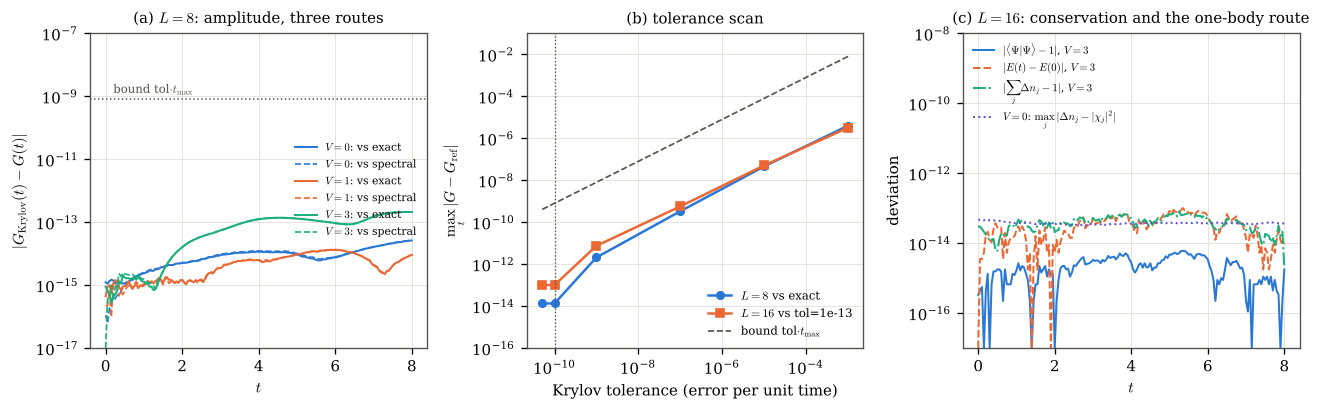

In [52]:
SCAN_ROWS = []
p8 = TRAJ[traj_key(8, -0.30, 1.0, 0)]["prep"]
e8 = evolve_exact(p8)
for tol in TOLS_SCAN:
    k = evolve(p8, tol=tol)
    c = compare(k, e8)
    SCAN_ROWS.append({"L": 8, "V": 1.0, "tol": tol, "reference": "exact", "err_G": c["G"], "err_dn": c["dn"],
                      "krylov_vectors": k["vectors"]})
p16 = TRAJ[traj_key(16, -0.30, 1.0, 0)]["prep"]
ref16 = evolve(p16, tol=1e-13)
for tol in TOLS_SCAN:
    k = evolve(p16, tol=tol)
    c = compare(k, ref16)
    SCAN_ROWS.append({"L": 16, "V": 1.0, "tol": tol, "reference": "tol=1e-13", "err_G": c["G"], "err_dn": c["dn"],
                      "krylov_vectors": k["vectors"]})
scan = pd.DataFrame(SCAN_ROWS)
display(scan)

s8 = scan[scan.L == 8].sort_values("tol", ascending=False)
check("S4 A4: tolerance scan: the error falls with the tolerance and stays below tol * t_max (L = 8 vs exact)",
      bool(np.all(np.diff(s8.err_G.iloc[:4]) < 0)) and bool(np.all(scan.err_G <= scan.tol * T_MAX)),
      (scan.err_G / (scan.tol * T_MAX)).max())

a, b = evolve(TRAJ[traj_key(12, -0.30, 1.0, 0)]["prep"]), evolve(TRAJ[traj_key(12, -0.30, 1.0, 0)]["prep"])
check("S4 A5: a rerun is bit-for-bit identical", np.array_equal(a["G"], b["G"]) and np.array_equal(a["dn"], b["dn"]))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.5))
ax = axes[0]
for i, V in enumerate(V_BIG):
    tr = TRAJ[traj_key(8, -0.30, V, 0)]
    ex = evolve_exact(tr["prep"])
    G = spectral_amplitude(step3_lines(8, -0.30, V, 0), tr["t"])
    ax.semilogy(tr["t"], np.maximum(np.abs(tr["G"] - ex["G"]), 1e-17), color=S4_COLORS[i], lw=1.2,
                label=rf"$V={V:g}$: vs exact")
    ax.semilogy(tr["t"], np.maximum(np.abs(tr["G"] - G), 1e-17), "--", color=S4_COLORS[i], lw=1.0,
                label=rf"$V={V:g}$: vs spectral")
ax.axhline(BOUND, color=GRAY, lw=0.9, ls=":")
ax.text(0.2, BOUND * 1.6, r"bound tol$\cdot t_{\max}$", fontsize=7, color=GRAY)
ax.set_ylim(1e-17, 1e-7)
ax.set_xlabel("$t$")
ax.set_ylabel(r"$|G_{\rm Krylov}(t)-G(t)|$")
ax.set_title(r"(a) $L=8$: amplitude, three routes", fontsize=9)
ax.legend(fontsize=6.5, loc="center right")

ax = axes[1]
for i, L in enumerate((8, 16)):
    s = scan[scan.L == L].sort_values("tol")
    ax.loglog(s.tol, np.maximum(s.err_G, 1e-17), "-", marker=S4_MARKERS[i], color=S4_COLORS[i],
              label=f"$L={L}$ vs {s.reference.iloc[0]}")
tt = np.array(TOLS_SCAN)
ax.loglog(tt, tt * T_MAX, "--", color=GRAY, lw=1.0, label=r"bound tol$\cdot t_{\max}$")
ax.axvline(KRYLOV_TOL, color=GRAY, lw=0.8, ls=":")
ax.set_ylim(1e-16, 1e-1)
ax.set_xlabel("Krylov tolerance (error per unit time)")
ax.set_ylabel(r"$\max_t|G-G_{\rm ref}|$")
ax.set_title("(b) tolerance scan", fontsize=9)
ax.legend(fontsize=7, loc="lower right")

ax = axes[2]
tr = TRAJ[traj_key(16, -0.30, 3.0, 0)]
for i, (lab, y) in enumerate(((r"$|\langle\Psi|\Psi\rangle-1|$", np.abs(tr["norm"] - 1)),
                              (r"$|E(t)-E(0)|$", np.abs(tr["energy"] - tr["energy"][0])),
                              (r"$|\sum_j\Delta n_j-1|$", np.abs(tr["dn"].sum(axis=1) - 1)))):
    ax.semilogy(tr["t"], np.maximum(y, 1e-17), ls=S4_LS[i], color=S4_COLORS[i], lw=1.2, label=lab + ", $V=3$")
tr0 = TRAJ[traj_key(16, -0.30, 0.0, 0)]
dn_free = free_trajectory(16, -0.30, 0, tr0["t"])[1]
ax.semilogy(tr0["t"], np.maximum(np.abs(tr0["dn"] - dn_free).max(axis=1), 1e-17), ls=S4_LS[3], color=S4_COLORS[3],
            lw=1.2, label=r"$V=0$: $\max_j|\Delta n_j-|\chi_j|^2|$")
ax.set_ylim(1e-17, 1e-8)
ax.set_xlabel("$t$")
ax.set_ylabel("deviation")
ax.set_title(r"(c) $L=16$: conservation and the one-body route", fontsize=9)
ax.legend(fontsize=6.5, loc="upper left")
fig.tight_layout()
savefig(fig, "step4_validation")
plt.show()

### 4.4 Larger chains, $L=18$ and $20$ (guide item 4)

These runs serve one purpose: to certify for how long each smaller chain is free of finite-size returns. $L=18$ repeats the whole grid, to $t=16$ for edge injection at $\delta=-0.30$, $V=0,1,3$. $L=20$ ($167\,960$ states in sector $N+1$) runs edge injection at $\delta=-0.30$, $V=0,1,3$, to $t=16$. The tolerance is halved at $V=1$ only, and the filtered preparation is built without evolving it (for $z_0(\mathcal W)$). $\Omega_N$ at $L=20$ is new: it is selected by the Step 2 rule here, and its $\Delta_+$ comes from Step 2's `ring_gap` at $L=20$.

In [53]:
start = time.time()
ladder_rows, ladder_filtered = [], []
for d in DELTA_S4:
    for V in V_S4:
        for site in (0, centre_site(18)):
            long = d < 0 and site == 0 and V in V_BIG
            row, tr = run_one(18, d, V, site, t_max=T_EXT if long else T_MAX,
                              halve=(d < 0 and site == 0 and V == 1.0), spectral=False)
            RUNS.append(row)
            ladder_rows.append(row)
            TRAJ[traj_key(18, d, V, site)] = tr
            if long:
                frow, _ = run_filtered(tr["prep"], evolve_it=False)
                FILTERED.append(frow)
                ladder_filtered.append(frow)
print(f"L = 18 done ({time.time() - start:.0f} s)")
for V in V_BIG:
    row, tr = run_one(20, -0.30, V, 0, t_max=T_EXT, halve=(V == 1.0), spectral=False)
    RUNS.append(row)
    ladder_rows.append(row)
    TRAJ[traj_key(20, -0.30, V, 0)] = tr
    frow, _ = run_filtered(tr["prep"], evolve_it=False)
    FILTERED.append(frow)
    ladder_filtered.append(frow)
    print(f"L = 20, V = {V:g}: dim {row['dim_Np1']}, norm drift {row['norm_drift']:.1e}, "
          f"energy drift {row['energy_drift']:.1e} ({time.time() - start:.0f} s)")

check_runs(L_LADDER, "L=18, 20")
display(pd.DataFrame(ladder_filtered)[["L", "V", "window_factor", "window_lines", "z0W", "z0W_step3", "q2", "q4"]])

L = 18 done (111 s)


L = 20, V = 0: dim 167960, norm drift 4.1e-14, energy drift 5.3e-13 (157 s)


L = 20, V = 1: dim 167960, norm drift 2.8e-14, energy drift 4.1e-13 (253 s)


L = 20, V = 3: dim 167960, norm drift 1.5e-14, energy drift 2.7e-13 (314 s)
[pass] S4 A0 [L=18, 20]: Omega_N = Step 2's state: C = +1, residual < 1e-9, E_0^N = step2_grid.csv   [7.94e-14]
[pass] S4 A3 [L=18, 20]: halving the Krylov tolerance changes G and Delta n_j by less than BOUND   [0.00e+00]
[pass] S4 B1 [L=18, 20]: norm, <H_(N+1)> and sum_j Delta n_j = 1 conserved, every run   [1.46e-12]
[pass] S4 B2 [L=18, 20]: t = 0 identities Delta n_j(0) = 1 - <n_j>, Delta n_k(0) = -<dn_j dn_k>_c/(1 - <n_j>)   [1.90e-14]
[pass] S4 B3 [L=18, 20]: V = 0: G and Delta n_j = one-body route from Step 1's h (no Fock space)   [2.85e-12]
[pass] S4 C1 [L=18, 20]: filtered preparation probability = Step 3 z_0(W) at the same f   [5.11e-15]


,L,V,window_factor,window_lines,z0W,z0W_step3,q2,q4
0,18,0,0.8,1,0.710171,0.710171,0.355095,0.458095
1,18,1,0.8,1,0.680936,0.680936,0.294016,0.422962
2,18,3,0.7,1,0.4561,0.4561,0.173961,0.298809
3,20,0,0.8,1,0.710096,NaN,0.355051,0.458007
4,20,1,0.8,1,0.681454,NaN,0.293897,0.422652
5,20,3,0.7,1,0.455568,NaN,0.171659,0.292288


### 4.5 The interval free of finite-size returns (guide item 4)

Each run is compared with the next larger chain that has the same $(\delta,V)$ and injection: $8\to12\to16\to18\to20$. $L=20$ has no larger partner; its interval is $L=18$'s certified time scaled by the ratio of the round-trip distances $2(L-1)-(\ell_e-1)$, i.e. the same speed is assumed (marked as scaled). The speed implied by the $L=18$ return, round trip$/t_{\rm fs}$, is an effective upper-side speed, not a group velocity: precursors enter the observation region linearly, through interference with the large static edge amplitude.

Checks:
- **D1:** a run compared with itself never departs.
- **D2:** $L=8$ against $12$ is flagged: the initial states already differ by more than $\varepsilon$ (the far edge is only $2.5\,\xi$ away).
- **D3:** $L=16$ against $18$ at $V=3$ has a transient just above $\varepsilon$ at $t\approx1.85$, the relaxation of the static offset; it must be ignored, and the genuine return later must be found.
- **D4:** $L=16$ gets an explicit interval against $L=18$ at $V=0,1,3$, with a converged initial state.
- **D5:** the late-time window logic: the second half of the certified interval, from $t\ge2$, and nothing if that is shorter than 1.

In [54]:
FS_ROWS = []
ladder = sorted({k[0] for k in TRAJ})
for (L, d, V, inj, kind), tr in TRAJ.items():
    if kind != "electron":
        continue
    bigger = [Lb for Lb in ladder if Lb > L and (Lb, d, V, inj, kind) in TRAJ]
    if not bigger:
        continue
    for eps in (EPS_VISIBLE, EPS_TIGHT):
        r = finite_size_time(tr, TRAJ[(bigger[0], d, V, inj, kind)], eps)
        FS_ROWS.append({"L": L, "L_ref": bigger[0], "delta": d, "V": V, "injection": inj, "eps": eps,
                        "t_fs": r["t_fs"], "reached": r["reached"], "t_common_max": r["t_common_max"],
                        "first_by_P": r["first"]["P"], "first_by_Q2": r["first"]["Q2"], "first_by_Q4": r["first"]["Q4"],
                        "static_offset_Q2": r["offset"]["Q2"], "static_offset_Q4": r["offset"]["Q4"],
                        "static_offset_max": r["static_offset_max"], "initial_state_ok": r["initial_state_ok"],
                        "extrapolated": False})

FS_LOOKUP, FS_META, SPEEDS = {}, {}, {}
for r in FS_ROWS:
    if r["eps"] == EPS_VISIBLE:
        k4 = (r["L"], r["delta"], r["V"], r["injection"])
        FS_LOOKUP[k4] = r["t_fs"] if r["reached"] else np.inf
        FS_META[k4] = r
for V in V_BIG:                                    # L = 20: L = 18's interval scaled by the round-trip distance
    r18 = FS_META[(18, -0.30, V, "edge")]
    no_return = not r18["reached"]
    t18 = r18["t_common_max"] if no_return else r18["t_fs"]
    t20 = t18 * round_trip(20) / round_trip(18)
    SPEEDS[V] = {"v": round_trip(18) / t18, "upper_bound": no_return, "t18": t18, "t20": t20}
    FS_LOOKUP[(20, -0.30, V, "edge")] = np.inf if no_return else t20
    row20 = {"L": 20, "L_ref": "scaled from L=18", "delta": -0.30, "V": V, "injection": "edge", "eps": EPS_VISIBLE,
             "t_fs": t20, "reached": not no_return, "t_common_max": T_EXT, "static_offset_max": np.nan,
             "initial_state_ok": r18["initial_state_ok"], "extrapolated": True}
    FS_ROWS.append(row20)
    FS_META[(20, -0.30, V, "edge")] = row20
V_FREE = free_front_velocity(-0.30)

cells = {}
for L in L_S4 + L_LADDER:
    for V in V_S4:
        x = FS_META.get((L, -0.30, V, "edge"))
        if x is None:
            cells[(L, V)] = "-"
        elif not x["initial_state_ok"]:
            cells[(L, V)] = f"s = {x['static_offset_max']:.3f} (not converged)"
        elif x["extrapolated"]:
            cells[(L, V)] = f"t < {x['t_fs']:.1f} (scaled)" + (" or longer" if not x["reached"] else "")
        elif x["reached"]:
            cells[(L, V)] = f"t < {x['t_fs']:.2f}"
        else:
            cells[(L, V)] = f"t <= {x['t_common_max']:g}, no return"
print("Certified finite-size-free interval, edge injection, delta = -0.30 (eps = 0.01 + 2 x static offset)")
display(pd.DataFrame([{"L": L, **{f"V={V:g}": cells[(L, V)] for V in V_S4}} for L in L_S4 + L_LADDER]).set_index("L"))
print("speed implied by the L = 18 return: " + ", ".join(
    f"V = {V:g}: {'<= ' if s['upper_bound'] else ''}{s['v']:.2f}" for V, s in SPEEDS.items())
      + f"  (free maximal group velocity 2 min(J_w, J_s) = {V_FREE:.2f})")

a = TRAJ[traj_key(16, -0.30, 1.0, 0)]
check("S4 D1: a run compared with itself never departs", not finite_size_time(a, a)["reached"])
r8 = finite_size_time(TRAJ[traj_key(8, -0.30, 1.0, 0)], TRAJ[traj_key(12, -0.30, 1.0, 0)])
check("S4 D2: L = 8 vs 12 is flagged: the initial states differ by more than eps",
      not r8["initial_state_ok"] and r8["static_offset_max"] > EPS_VISIBLE, r8["static_offset_max"])
a3, b3 = TRAJ[traj_key(16, -0.30, 3.0, 0)], TRAJ[traj_key(18, -0.30, 3.0, 0)]
i = int(round(1.85 / DT))
blip = abs((Q_edge(a3, 4)[i] - Q_edge(a3, 4)[0]) - (Q_edge(b3, 4)[i] - Q_edge(b3, 4)[0]))
r3 = finite_size_time(a3, b3)
print(f"    L = 16 vs 18, V = 3: transient {blip:.4f} at t = 1.85 (static offset {r3['static_offset_max']:.4f}); "
      f"return at t = {r3['t_fs']:.2f}")
check("S4 D3: L = 16 vs 18, V = 3: the transient above eps is ignored, the later return is found",
      blip > EPS_VISIBLE and r3["initial_state_ok"] and r3["reached"] and r3["t_fs"] > 3.0, r3["t_fs"])
ok = all(FS_META[(16, -0.30, V, "edge")]["initial_state_ok"] and FS_META[(16, -0.30, V, "edge")]["t_fs"] > 0
         for V in V_BIG)
check("S4 D4: L = 16 has an explicit certified interval against L = 18 at V = 0, 1, 3", ok)
w1, w2, w3 = late_window(5.3, 8.0, True), late_window(np.inf, 8.0, False), late_window(1.5, 8.0, True)
check("S4 D5: late window = second half of the certified interval, from t >= 2; none if shorter than 1",
      np.allclose(w1, (2.65, 5.3)) and np.allclose(w2, (4.0, 8.0)) and np.isnan(w3[0]))

Certified finite-size-free interval, edge injection, delta = -0.30 (eps = 0.01 + 2 x static offset)


,V=0,V=0.5,V=1,V=2,V=3
L,,,,,
8,s = 0.053 (not converged),s = 0.067 (not converged),s = 0.080 (not converged),s = 0.086 (not converged),s = 0.062 (not converged)
12,s = 0.014 (not converged),s = 0.016 (not converged),s = 0.020 (not converged),s = 0.030 (not converged),s = 0.031 (not converged)
16,"t <= 8, no return","t <= 8, no return","t <= 8, no return","t <= 8, no return",t < 4.90
18,"t <= 16, no return",-,t < 14.45,-,t < 6.50
20,t < 18.1 (scaled) or longer,-,t < 16.3 (scaled),-,t < 7.3 (scaled)


speed implied by the L = 18 return: V = 0: <= 1.94, V = 1: 2.15, V = 3: 4.77  (free maximal group velocity 2 min(J_w, J_s) = 1.40)
[pass] S4 D1: a run compared with itself never departs
[pass] S4 D2: L = 8 vs 12 is flagged: the initial states differ by more than eps   [7.96e-02]
    L = 16 vs 18, V = 3: transient 0.0108 at t = 1.85 (static offset 0.0081); return at t = 4.90
[pass] S4 D3: L = 16 vs 18, V = 3: the transient above eps is ignored, the later return is found   [4.90e+00]
[pass] S4 D4: L = 16 has an explicit certified interval against L = 18 at V = 0, 1, 3
[pass] S4 D5: late window = second half of the certified interval, from t >= 2; none if shorter than 1


### 4.6 Two-edge beating (guide item 4)

At finite $L$ the $N$-sector doublet is split by $E_1^N-E_0^N\sim e^{-L/\xi}$, and a two-edge beat would oscillate at that frequency, with period $2\pi/(E_1^N-E_0^N)$: about 34-40 at $L=8$, but 480-660 at $L=16$ and thousands at $L=20$, far beyond every run. The test is therefore done at $L=8$, by exact evolution to $t=300$ (`T_BEAT`).

A beat at the splitting needs a second line at $\omega_{\rm edge}\pm(E_1^N-E_0^N)$ that the electron also reaches. **E1:** the weight of such partners is below $10^{-3}$ of the edge line, and the Fourier amplitude of $Q_{\rm edge}(t)$ ($\ell_e=4$) at the splitting is below 5% of its largest value. **E2:** the infinite-time average (diagonal ensemble, with degenerate eigenspaces of sector $N+1$ projected as blocks) puts exactly $\tfrac12$ of the excess charge in each half of the chain.

In [55]:
BEAT, PERIODS = [], []
ok_partner, ok_fourier, worst_partner, worst_fourier = True, True, 0.0, 0.0
for V in V_BIG:
    prep = TRAJ[traj_key(8, -0.30, V, 0)]["prep"]
    ex = evolve_exact(prep, T_BEAT)
    E, U = np.linalg.eigh(prep["H"].toarray())
    z = np.abs(U.T @ prep["psi0"]) ** 2
    om = E - prep["E0"]
    split = prep["gs_gap"]
    ie = int(np.argmax(z))                                     # the edge line
    partner = sum(z[m] for m in range(len(om))
                  if m != ie and min(abs(om[m] - om[ie] - split), abs(om[m] - om[ie] + split)) < 0.02)
    q = Q_edge(ex, 4) - Q_edge(ex, 4).mean()
    freqs = np.linspace(0.005, 3.0, 3000)
    phase = np.exp(1j * np.outer(freqs, ex["t"]))
    plain = 2 * np.abs(phase @ q) / len(q)
    hann = np.hanning(len(q))
    spec_h = 2 * np.abs(phase @ (q * hann)) / hann.sum()
    at_split = 2 * abs(np.mean(q * np.exp(1j * split * ex["t"])))
    ok_partner &= partner < 1e-3 * z[ie]
    ok_fourier &= at_split < 0.05 * plain.max()
    worst_partner = max(worst_partner, partner / z[ie])
    worst_fourier = max(worst_fourier, at_split / plain.max())
    BEAT.append({"V": V, "splitting": split, "period": 2 * np.pi / split, "edge_line_omega": om[ie],
                 "partner_weight": partner, "fourier_at_split": at_split,
                 "fourier_at_split_hann": 2 * abs(np.sum(q * hann * np.exp(1j * split * ex["t"]))) / hann.sum(),
                 "fourier_max": plain.max(), "fourier_max_at": freqs[np.argmax(plain)],
                 "fourier_max_hann": spec_h.max(), "Q_left4_mean": Q_edge(ex, 4).mean(),
                 "Q_right4_mean": Q_far(ex, 4).mean(), "freqs": freqs, "spectrum_hann": spec_h})
for L in L_S4 + L_LADDER:
    for V in V_BIG:
        if traj_key(L, -0.30, V, 0) in TRAJ:
            g = TRAJ[traj_key(L, -0.30, V, 0)]["prep"]["gs_gap"]
            PERIODS.append({"L": L, "V": V, "splitting": g, "beat_period": 2 * np.pi / g})
display(pd.DataFrame([{k: v for k, v in b.items() if k not in ("freqs", "spectrum_hann")} for b in BEAT]))
display(pd.DataFrame(PERIODS).pivot(index="L", columns="V", values="beat_period"))
check("S4 E1: L = 8, t <= 300: no beat at the N-sector splitting (partner weight < 1e-3, Fourier < 5% of max)",
      ok_partner and ok_fourier, worst_fourier)

dev, n_blocks = 0.0, 0
for V in V_BIG:
    prep = TRAJ[traj_key(8, -0.30, V, 0)]["prep"]
    E, U = np.linalg.eigh(prep["H"].toarray())
    dens = np.zeros(8)
    for block in np.split(np.arange(len(E)), np.flatnonzero(np.diff(E) > 1e-9) + 1):
        n_blocks += len(block) > 1
        phi = U[:, block] @ (U[:, block].T @ prep["psi0"])
        dens += prep["occ"].T @ np.abs(phi) ** 2
    dev = max(dev, abs((dens - prep["n_ref"])[:4].sum() - 0.5))
print(f"    {n_blocks} degenerate blocks of sector N+1 projected as blocks")
check("S4 E2: diagonal ensemble puts exactly 1/2 of the excess charge in each half (L = 8, V = 0, 1, 3)", dev < 1e-10, dev)

,V,splitting,period,edge_line_omega,partner_weight,fourier_at_split,fourier_at_split_hann,fourier_max,fourier_max_at,fourier_max_hann,Q_left4_mean,Q_right4_mean
0,0,0.158143,39.7311,0.0790713,0,0.00211465,2.65048e-05,0.13885,0.96372,0.138903,0.500309,0.499691
1,1,0.183795,34.1858,0.131175,0,0.00314323,0.000512413,0.161245,1.24934,0.161601,0.500127,0.499873
2,3,0.17666,35.5666,0.42272,0,0.00532977,0.00735555,0.260922,1.61086,0.261039,0.499511,0.500489


V,0,1,3
L,,,
8,39.7311,34.1858,35.5666
12,139.301,140.884,143.709
16,481.457,609.672,658.415
18,894.296,1274.72,1458.76
20,1660.94,2667.67,3282.6


[pass] S4 E1: L = 8, t <= 300: no beat at the N-sector splitting (partner weight < 1e-3, Fourier < 5% of max)   [2.04e-02]
    8 degenerate blocks of sector N+1 projected as blocks
[pass] S4 E2: diagonal ensemble puts exactly 1/2 of the excess charge in each half (L = 8, V = 0, 1, 3)   [8.22e-15]


### 4.7 The far edge at $t=0$

$\Delta n_{L-1}(0)=-\langle\delta n_0\,\delta n_{L-1}\rangle_c/(1-\langle n_0\rangle)$ is a ground-state correlation, not transport. In the selected $\Omega_N$ (Step 2: $C=+1$, $\langle n_j\rangle=\tfrac12$) the two end modes share one fermion, so it is of order one and does not decay with $L$; at $V=0$ it tends to $(1-r^2)^2/2$. In a left- or right-loaded combination of the doublet it is small. Which of these is "the" ground state is exactly Step 2's state-selection question, because the doublet is split only by $e^{-L/\xi}$. **E3:** at $V=0$ the selected value approaches $(1-r^2)^2/2$ monotonically ($L=8,12,16$, within 0.01 at $L=16$), and both broken states give less than 0.01 at $L=16$.

In [56]:
FAR_ROWS = []
for L in L_S4 + L_LADDER:
    for V in V_BIG:
        r = far_edge_response(L, -0.30, V)
        FAR_ROWS.append({"L": L, "V": V, "selected": r["selected"]["dn_far"], "left_loaded": r["left_loaded"]["dn_far"],
                         "right_loaded": r["right_loaded"]["dn_far"], "n0_selected": r["selected"]["n0"],
                         "n0_left_loaded": r["left_loaded"]["n0"], "n0_right_loaded": r["right_loaded"]["n0"],
                         "doublet_splitting": r["doublet_splitting"]})
far = pd.DataFrame(FAR_ROWS)
display(far.pivot(index="L", columns="V", values=["selected", "left_loaded"]))

FAR_LIMIT = (1 - ratio(-0.30) ** 2) ** 2 / 2
gaps = [abs(far.query("L == @L and V == 0").selected.item() - FAR_LIMIT) for L in L_S4]
f16 = far.query("L == 16 and V == 0").iloc[0]
print(f"    |Delta n_far - (1-r^2)^2/2| at V = 0: " + ", ".join(f"L = {L}: {g:.4f}" for L, g in zip(L_S4, gaps)))
check("S4 E3: V = 0 far-edge excess -> (1-r^2)^2/2 = 0.252; broken states from the doublet < 0.01 (L = 16)",
      all(b < a for a, b in zip(gaps, gaps[1:])) and gaps[-1] < 0.01
      and f16.left_loaded < 0.01 and f16.right_loaded < 0.01, gaps[-1])

selected                   left_loaded                        
V         0        1        3           0           1           3
L                                                                
8  0.212603 0.228424  0.28444   0.0115476   0.0166877  0.00632849
12 0.232355 0.263306 0.314782  0.00169504  0.00327289   0.0025264
16 0.244456 0.278582 0.331764 0.000215547 0.000445393 0.000874381
18 0.247556 0.281486 0.335656 7.35502e-05 0.000155323 0.000526193
20 0.249445 0.282977 0.337899 2.45643e-05 5.33173e-05 0.000323623

    |Delta n_far - (1-r^2)^2/2| at V = 0: L = 8: 0.0395, L = 12: 0.0197, L = 16: 0.0076
[pass] S4 E3: V = 0 far-edge excess -> (1-r^2)^2/2 = 0.252; broken states from the doublet < 0.01 (L = 16)   [7.64e-03]


### 4.8 Lines below the bulk threshold: the charge that cannot leave

Every line of sector $N+1$ below the ring threshold $\Delta_+$ that the edge electron reaches, at $L=16$, with its share $z$ and the excess charge it carries on the first 2 and 4 sites. $\sum z\,q_4$ over these lines is the edge charge that the diagonal ensemble keeps at the edge; it is compared with the late $Q_{\rm edge}$ in 4.9.

In [57]:
LINE_ROWS, BOUND_Q = [], {}
for d in DELTA_S4:
    for V in V_S4:
        prep = TRAJ[traj_key(16, d, V, 0)]["prep"]
        dp = delta_plus(16, d, V)
        lines = bound_lines(prep, dp)
        LINE_ROWS += [{"L": 16, "delta": d, "V": V, "delta_plus": dp, **x} for x in lines]
        BOUND_Q[(d, V)] = {"zq4": sum(x["z"] * x["q4"] for x in lines), "zq2": sum(x["z"] * x["q2"] for x in lines),
                           "n": len(lines)}
display(pd.DataFrame(LINE_ROWS))
print(pd.DataFrame([{"delta": d, "V": V, "lines below Delta_+": b["n"], "sum z q2": b["zq2"], "sum z q4": b["zq4"]}
                    for (d, V), b in BOUND_Q.items()]).to_string(index=False, float_format=lambda x: f"{x:.4f}"))

,L,delta,V,delta_plus,omega,z,q2,q4,q_far4,q_left_half
0,16,-0.3,0,0.6,0.00652518,0.710396,0.355229,0.458375,0.458375,0.5
1,16,-0.3,0.5,0.758533,0.00585742,0.701724,0.325356,0.443961,0.443961,0.5
2,16,-0.3,1,0.910621,0.00604813,0.679899,0.294347,0.423834,0.423834,0.5
3,16,-0.3,2,1.19692,0.0141521,0.595148,0.232677,0.370034,0.370034,0.5
4,16,-0.3,3,1.48057,0.0643639,0.457134,0.177669,0.309293,0.309293,0.5
5,16,-0.3,3,1.48057,1.25533,0.104492,0.21669,0.386464,0.386464,0.5


  delta      V  lines below Delta_+  sum z q2  sum z q4
-0.3000 0.0000                    1    0.2524    0.3256
-0.3000 0.5000                    1    0.2283    0.3115
-0.3000 1.0000                    1    0.2001    0.2882
-0.3000 2.0000                    1    0.1385    0.2202
-0.3000 3.0000                    2    0.1039    0.1818
 0.3000 0.0000                    0    0.0000    0.0000
 0.3000 0.5000                    0    0.0000    0.0000
 0.3000 1.0000                    0    0.0000    0.0000
 0.3000 2.0000                    0    0.0000    0.0000
 0.3000 3.0000                    0    0.0000    0.0000


### 4.9 Late-time averages inside the certified interval, against Step 3

For each run with a certified interval, $\langle P_{\rm return}\rangle_{\rm late}$ and $\langle Q_{\rm edge}\rangle_{\rm late}$ are averaged over the second half of it (from $t\ge2$; 4.5). What the edge eigenstate alone predicts: if the edge line keeps weight $z_0(\mathcal W)$ and the rest dephases or leaves, $\langle P_{\rm return}\rangle\to z_0(\mathcal W)^2$ and $\langle Q_4\rangle\to z_0(\mathcal W)\,q_4$, with $q_4$ the charge of the filtered state on the first four sites. **E4:** at $L=16$, $V=0,1,3$, the late return probability of edge injection is within 0.05 of $z_0(\mathcal W)^2$, and below 0.05 for $\delta=+0.30$.

In [58]:
filt_lookup = {(r["L"], r["delta"], r["V"]): r for r in FILTERED}
for r in RUNS:
    k4 = (r["L"], r["delta"], r["V"], r["injection"])
    tr = TRAJ[traj_key(r["L"], r["delta"], r["V"], r["site"])]
    meta = FS_META.get(k4)
    r["initial_state_ok"] = bool(meta["initial_state_ok"]) if meta else False
    r["static_offset_max"] = meta["static_offset_max"] if meta else np.nan
    r["t_fs_extrapolated"] = bool(meta["extrapolated"]) if meta else False
    if meta is None or not r["initial_state_ok"]:
        t_a, t_b = np.nan, np.nan                                  # nothing to certify against, or not converged
        r["t_fs_visible"] = np.nan if meta is None else meta["t_fs"]
    else:
        t_fs = FS_LOOKUP[k4]
        t_a, t_b = late_window(t_fs, r["t_max"], np.isfinite(t_fs))
        r["t_fs_visible"] = t_fs if np.isfinite(t_fs) else r["t_max"]
    r["late_from"], r["late_to"] = t_a, t_b
    if np.isfinite(t_a):
        m = (tr["t"] >= t_a) & (tr["t"] <= t_b + 1e-9)
        r.update(P_late=P_return(tr)[m].mean(), Q2_late=Q_local(tr, 2)[m].mean(), Q4_late=Q_local(tr, 4)[m].mean(),
                 Qfar4_late=Q_far(tr, 4)[m].mean())
    else:
        r.update(P_late=np.nan, Q2_late=np.nan, Q4_late=np.nan, Qfar4_late=np.nan)
    f = filt_lookup.get((r["L"], r["delta"], r["V"]))
    if f is not None and r["injection"] == "edge":
        r["z0W"] = f["z0W"]
        r["pred_P_late"] = f["z0W"] ** 2
        if not f["window_empty"]:
            r["pred_Q2_late"], r["pred_Q4_late"] = f["z0W"] * f["q2"], f["z0W"] * f["q4"]
    b = BOUND_Q.get((r["delta"], r["V"]))                          # L = 16 lines, converged in L
    if b is not None and r["injection"] == "edge":
        r.update(bound_Q4=b["zq4"], bound_Q2=b["zq2"], n_bound_lines=b["n"])
runs = pd.DataFrame(RUNS)


def run_row(L, d, V, inj):
    return runs.query("L == @L and delta == @d and V == @V and injection == @inj").iloc[0]


late = []
for L in (16, 20):
    for V in V_S4 if L == 16 else V_BIG:
        e = run_row(L, -0.30, V, "edge")
        rec = {"L": L, "V": V, "late window": f"[{e.late_from:.2f}, {e.late_to:.2f}]", "z0(W)": e.z0W,
               "<P>late": e.P_late, "z0^2": e.pred_P_late, "<Q4>late": e.Q4_late, "z0 q4": e.pred_Q4_late,
               "sum z q4 (L=16 lines)": e.bound_Q4}
        if L == 16:
            rec["centre <Q4>late"] = run_row(16, -0.30, V, "centre").Q4_late
            rec["delta=+0.30 <Q4>late"] = run_row(16, 0.30, V, "edge").Q4_late
            rec["delta=+0.30 <P>late"] = run_row(16, 0.30, V, "edge").P_late
        late.append(rec)
late = pd.DataFrame(late)
display(late)

l16 = late[(late.L == 16) & late.V.isin(V_BIG)]
dev = np.max(np.abs(l16["<P>late"] - l16["z0^2"]))
check("S4 E4: L = 16, V = 0, 1, 3: late <P_return> within 0.05 of z_0(W)^2; delta = +0.30 below 0.05",
      dev < 0.05 and bool(np.all(l16["delta=+0.30 <P>late"] < 0.05)), dev)

,L,V,late window,z0(W),<P>late,z0^2,<Q4>late,z0 q4,sum z q4 (L=16 lines),centre <Q4>late,delta=+0.30 <Q4>late,delta=+0.30 <P>late
0,16,0,"[4.00, 8.00]",0.710396,0.540168,0.504663,0.365921,0.325628,0.325628,0.180676,0.164309,0.0195032
1,16,0.5,"[4.00, 8.00]",0.701724,0.521592,0.492416,0.355872,0.311538,0.311538,0.186687,0.116016,0.0131174
2,16,1,"[4.00, 8.00]",0.679899,0.486727,0.462262,0.331737,0.288164,0.288164,0.254449,0.0850409,0.00972624
3,16,2,"[4.00, 8.00]",0.595148,0.365816,0.354201,0.274928,0.220225,0.220225,0.256234,0.0527245,0.0077212
4,16,3,"[2.45, 4.90]",0.457134,0.219973,0.208972,0.277664,0.141389,0.181771,NaN,0.0428927,0.00772648
5,20,0,"[8.00, 16.00]",0.710096,0.498956,0.504236,0.327263,0.325229,0.325628,NaN,NaN,NaN
6,20,1,"[8.00, 16.00]",0.681454,0.46019,0.464379,0.280405,0.288017,0.288164,NaN,NaN,NaN
7,20,3,"[3.67, 7.34]",0.455568,0.227764,0.207542,0.26954,0.133157,0.181771,NaN,NaN,NaN


[pass] S4 E4: L = 16, V = 0, 1, 3: late <P_return> within 0.05 of z_0(W)^2; delta = +0.30 below 0.05   [3.55e-02]


### 4.10 Energy moments of the added particle

For a particle added on the end site, $[H,c_0^\dagger]=-J_0c_1^\dagger+Vc_0^\dagger(n_1-\tfrac12)$ and $\langle n_j\rangle=\tfrac12$ give closed forms for the first two moments of the addition spectrum, at any $V$:
$$m_1=\langle\Psi(0)|H-E_0^N|\Psi(0)\rangle=2\big[J_0\langle c_0^\dagger c_1\rangle-V\langle\delta n_0\delta n_1\rangle_c\big],\qquad m_2=\langle\Psi(0)|(H-E_0^N)^2|\Psi(0)\rangle=J_0^2+2J_0V\langle c_0^\dagger c_1\rangle+\tfrac{V^2}{4},$$
so $P_{\rm return}(t)=1-(m_2-m_1^2)t^2+O(t^4)$: the initial decay is set by ground-state correlators that Step 2's `corr_matrix` gives. **B4:** both formulas hold at $L=8,12,16$, $\delta=\pm0.30$, every $V$.

In [59]:
rows = []
for L in L_S4:
    for d in DELTA_S4:
        for V in V_S4:
            prep = TRAJ[traj_key(L, d, V, 0)]["prep"]
            psi = ground_state_N(L, d, V)
            C01 = corr_matrix(psi, L, L // 2)[0, 1]                   # <c_0^dag c_1>, Step 2
            J0 = bonds(L, d)[0]
            Hp = prep["H"] @ prep["psi0"] - prep["E0"] * prep["psi0"]
            m1, m2 = np.vdot(prep["psi0"], Hp).real, np.vdot(Hp, Hp).real
            rows.append({"L": L, "delta": d, "V": V, "m1": m1, "m2": m2, "Delta E": np.sqrt(m2 - m1**2),
                         "|m1 - formula|": abs(m1 - 2 * (J0 * C01 - V * prep["corr"][1])),
                         "|m2 - formula|": abs(m2 - (J0**2 + 2 * J0 * V * C01 + V**2 / 4))})
moments = pd.DataFrame(rows)
display(moments[moments.L == 16])
dev = moments[["|m1 - formula|", "|m2 - formula|"]].to_numpy().max()
check("S4 B4: energy moments m1, m2 of c_0^dag|Omega> = closed forms from <c_0^dag c_1> and <dn_0 dn_1>_c, any V",
      dev < 1e-9, dev)

,L,delta,V,m1,m2,Delta E,|m1 - formula|,|m2 - formula|
20,16,-0.3,0,0.367239,0.49,0.595933,3.88578e-16,2.07057e-14
21,16,-0.3,0.5,0.453778,0.736671,0.72853,1.32894e-13,2.22378e-13
22,16,-0.3,1,0.572069,1.10784,0.883505,2.41807e-13,4.95382e-13
23,16,-0.3,2,0.907433,2.21727,1.18061,1.89759e-12,5.6426e-12
24,16,-0.3,3,1.37684,3.80833,1.38298,2.17493e-12,8.79385e-12
25,16,0.3,0,1.251,1.69,0.353554,1.57652e-14,4.68514e-14
26,16,0.3,0.5,1.49172,2.38085,0.394483,9.76996e-15,3.4639e-14
27,16,0.3,1,1.73231,3.19719,0.443045,1.5099e-14,5.90639e-14
28,16,0.3,2,2.20858,5.1797,0.549417,5.50671e-14,2.71783e-13
29,16,0.3,3,2.67378,7.58714,0.661831,4.44089e-15,3.55271e-14


[pass] S4 B4: energy moments m1, m2 of c_0^dag|Omega> = closed forms from <c_0^dag c_1> and <dn_0 dn_1>_c, any V   [8.79e-12]


### 4.11 Figures

`step4_spacetime_density`. Top: where the charge goes. Change of the excess charge per two-site cell since $t=0$ (cells remove the sublattice stripes), edge injection at $L=20$ to $t=16$; the injection cell's own depletion saturates the colour scale on purpose. Dashed: a front and its reflection at the free maximal group velocity $2\min(J_w,J_s)$ ($V=0$) or at the speed implied by the certified return ($V>0$); solid: the end of the certified interval. Bottom: the density profile itself, $\Delta n_j(t)$, at $L=16$, $V=1$, for edge injection (dashed: the filtered state, which does not move), centre injection, and the opposite dimerisation. Note the excess already at the far end at $t=0$ (4.7) and the negative $\Delta n_j$ where the background rearranges.

saved figures/step4_spacetime_density.pdf


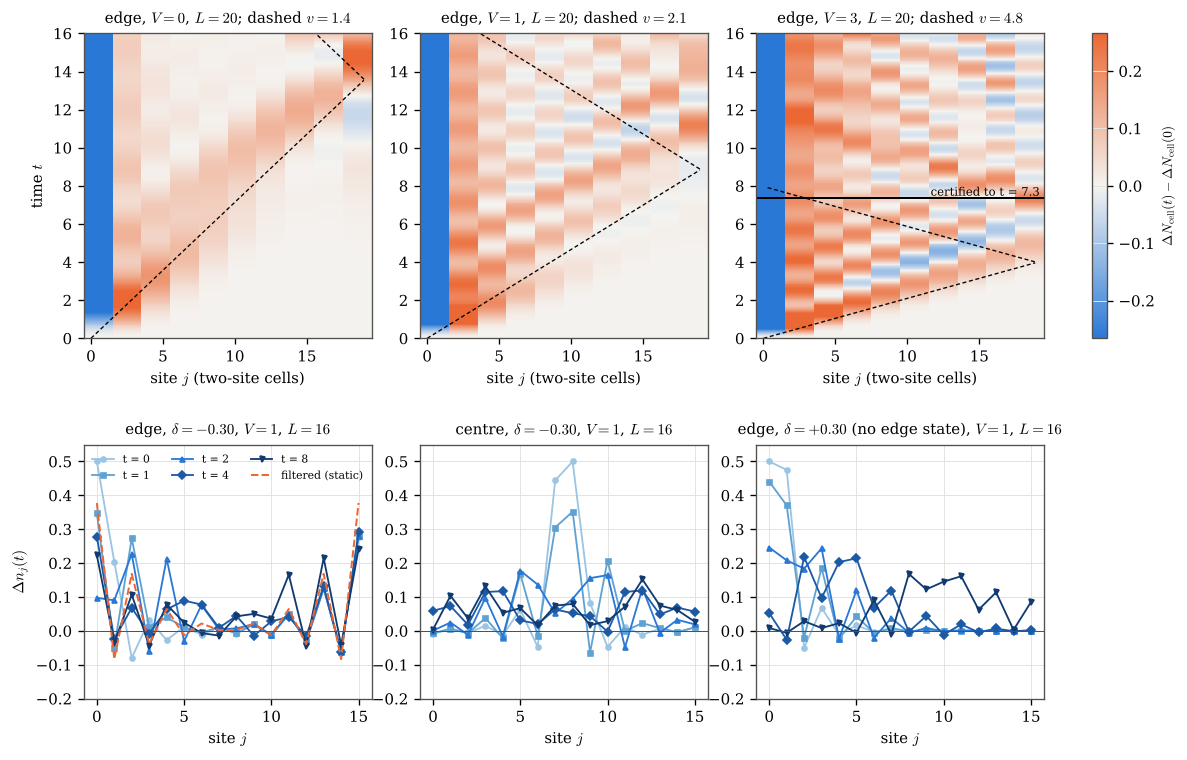

In [60]:
def cells_of(tr):
    return tr["dn"][:, 0::2] + tr["dn"][:, 1::2]


fig = plt.figure(figsize=(11, 7.2))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.05], height_ratios=[1.2, 1.0], hspace=0.38, wspace=0.22)
tops = [(V, TRAJ[traj_key(20, -0.30, V, 0)]) for V in V_BIG]
changes = [cells_of(tr) - cells_of(tr)[0] for _, tr in tops]
vmax = np.percentile(np.abs(np.concatenate([c[:, 1:].ravel() for c in changes])), 99)
norm = TwoSlopeNorm(vcenter=0.0, vmin=-vmax, vmax=vmax)
for col, ((V, tr), ch) in enumerate(zip(tops, changes)):
    ax = fig.add_subplot(gs[0, col])
    L = tr["prep"]["L"]
    im = ax.pcolormesh(2.0 * np.arange(L // 2 + 1) - 0.5, np.append(tr["t"], tr["t"][-1] + DT) - DT / 2, ch,
                       cmap=S4_DIVERGING, norm=norm, shading="flat", rasterized=True)
    v_line = SPEEDS[V]["v"] if V in SPEEDS and not SPEEDS[V]["upper_bound"] else V_FREE
    tt = np.linspace(0, tr["t"][-1], 300)
    out = v_line * tt
    ax.plot(np.where(out <= L - 1, out, np.nan), tt, color="k", lw=0.8, ls=(0, (3, 2)))
    back = 2 * (L - 1) - out
    ax.plot(np.where((out > L - 1) & (back >= 0), back, np.nan), tt, color="k", lw=0.8, ls=(0, (3, 2)))
    t_fs = FS_LOOKUP.get((L, -0.30, V, "edge"))
    if t_fs is not None and np.isfinite(t_fs) and t_fs < tr["t"][-1]:
        ax.axhline(t_fs, color="k", lw=1.2)
        ax.text(L - 0.8, t_fs, f"certified to t = {t_fs:.1f}", fontsize=7, ha="right", va="bottom")
    ax.grid(False)
    ax.set_xlim(-0.5, L - 0.5)
    ax.set_ylim(0, tr["t"][-1])
    ax.set_title(rf"edge, $V={V:g}$, $L={L}$; dashed $v={v_line:.1f}$", fontsize=9)
    ax.set_xlabel("site $j$ (two-site cells)")
    if col == 0:
        ax.set_ylabel("time $t$")
cb = fig.colorbar(im, cax=fig.add_subplot(gs[0, 3]))
cb.set_label(r"$\Delta N_{\rm cell}(t)-\Delta N_{\rm cell}(0)$", fontsize=8)

snaps = (0.0, 1.0, 2.0, 4.0, 8.0)
ramp = ["#9cc5e3", "#5fa2d1", "#2a78d6", "#1d5aa6", "#103a70"]
for col, (k, title) in enumerate(((traj_key(16, -0.30, 1.0, 0), r"edge, $\delta=-0.30$"),
                                  (traj_key(16, -0.30, 1.0, centre_site(16)), r"centre, $\delta=-0.30$"),
                                  (traj_key(16, 0.30, 1.0, 0), r"edge, $\delta=+0.30$ (no edge state)"))):
    ax = fig.add_subplot(gs[1, col])
    tr = TRAJ[k]
    for i, t in enumerate(snaps):
        ax.plot(np.arange(16), tr["dn"][int(round(t / DT))], marker=S4_MARKERS[i % 5], ms=3, lw=1.1, color=ramp[i],
                label=f"t = {t:g}")
    if col == 0:
        f = TRAJ[traj_key(16, -0.30, 1.0, 0, "filtered")]
        ax.plot(np.arange(16), f["dn"][0], "--", color=S4_COLORS[1], lw=1.2, label="filtered (static)")
        ax.legend(fontsize=6.5, ncol=3, loc="upper center")
    ax.axhline(0, color=GRAY, lw=0.6)
    ax.set_ylim(-0.2, 0.55)
    ax.set_title(title + r", $V=1$, $L=16$", fontsize=9)
    ax.set_xlabel("site $j$")
    if col == 0:
        ax.set_ylabel(r"$\Delta n_j(t)$")
savefig(fig, "step4_spacetime_density")
plt.show()

`step4_time_traces`, $\delta=-0.30$ unless stated. Top: $P_{\rm return}(t)$; bottom: excess charge. Edge injection at $L=16$ (thick) and $L=20$ to $t=16$ (thin), centre injection (four central sites), the opposite dimerisation, and the filtered state. Grey dashed: what the edge eigenstate alone predicts, $z_0(\mathcal W)^2$ for the return and $z_0(\mathcal W)\,q_4$ for the edge charge. Shaded: outside $L=16$'s certified interval (darker) and $L=20$'s (lighter).

saved figures/step4_time_traces.pdf


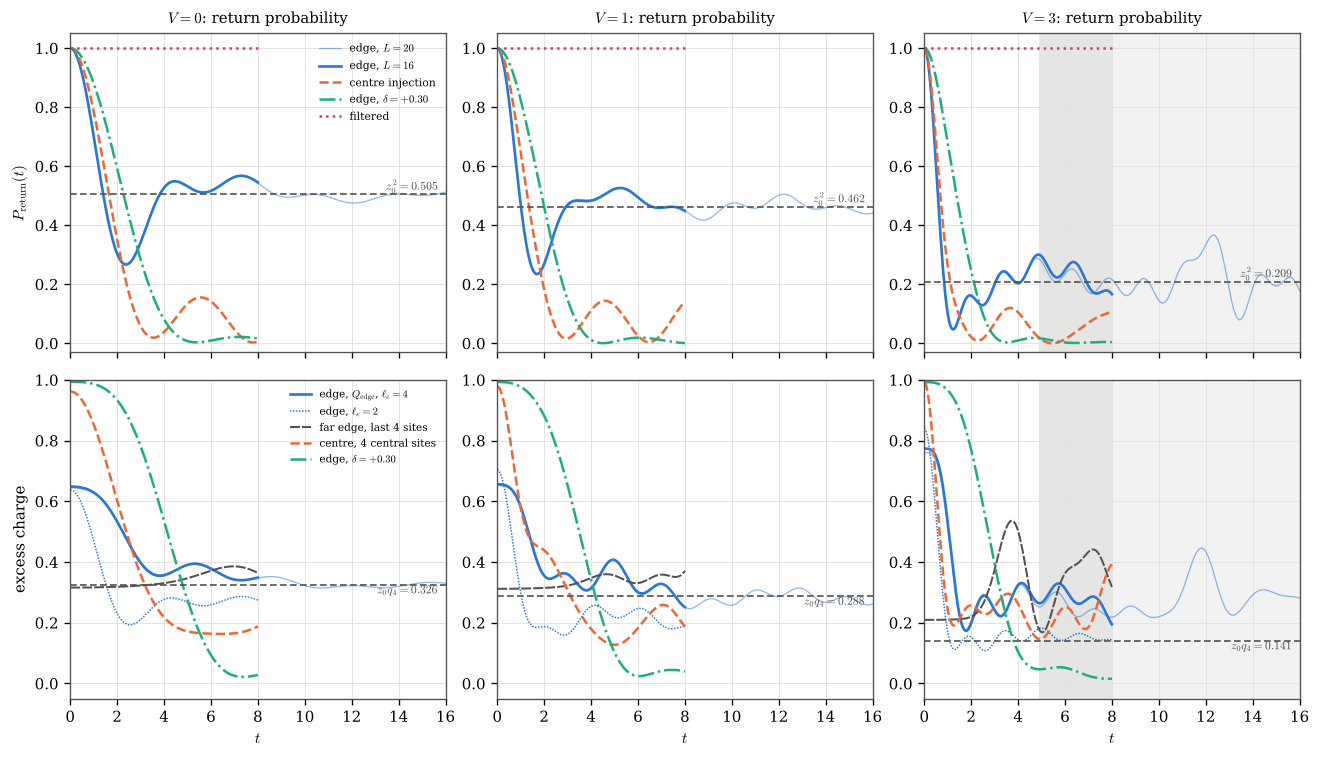

In [61]:
fig, axes = plt.subplots(2, 3, figsize=(11, 6.4), sharex=True)
for col, V in enumerate(V_BIG):
    e16, c16 = TRAJ[traj_key(16, -0.30, V, 0)], TRAJ[traj_key(16, -0.30, V, centre_site(16))]
    t16, f16 = TRAJ[traj_key(16, 0.30, V, 0)], TRAJ[traj_key(16, -0.30, V, 0, "filtered")]
    e20 = TRAJ[traj_key(20, -0.30, V, 0)]
    fr = filt_lookup[(16, -0.30, V)]
    ax = axes[0, col]
    ax.plot(e20["t"], P_return(e20), color=S4_COLORS[0], lw=0.8, alpha=0.5, label="edge, $L=20$")
    ax.plot(e16["t"], P_return(e16), color=S4_COLORS[0], lw=1.6, label="edge, $L=16$")
    ax.plot(c16["t"], P_return(c16), "--", color=S4_COLORS[1], label="centre injection")
    ax.plot(t16["t"], P_return(t16), "-.", color=S4_COLORS[2], label=r"edge, $\delta=+0.30$")
    ax.plot(f16["t"], P_return(f16), ":", color=S4_COLORS[4], label="filtered")
    ax.axhline(fr["z0W"] ** 2, color=GRAY, lw=1.0, ls=(0, (4, 2)))
    ax.text(T_EXT * 0.98, fr["z0W"] ** 2, rf"$z_0^2={fr['z0W']**2:.3f}$", fontsize=7, color=GRAY, ha="right", va="bottom")
    ax.set_ylim(-0.03, 1.05)
    ax.set_title(rf"$V={V:g}$: return probability", fontsize=9)
    ax = axes[1, col]
    ax.plot(e20["t"], Q_edge(e20, 4), color=S4_COLORS[0], lw=0.8, alpha=0.5)
    ax.plot(e16["t"], Q_edge(e16, 4), color=S4_COLORS[0], lw=1.6, label=r"edge, $Q_{\rm edge}$, $\ell_e=4$")
    ax.plot(e16["t"], Q_edge(e16, 2), color=S4_COLORS[0], lw=0.9, ls=(0, (1, 1)), label=r"edge, $\ell_e=2$")
    ax.plot(e16["t"], Q_far(e16, 4), color=S4_COLORS[5], lw=1.2, ls=(0, (5, 1)), label="far edge, last 4 sites")
    ax.plot(c16["t"], Q_local(c16, 4), "--", color=S4_COLORS[1], label="centre, 4 central sites")
    ax.plot(t16["t"], Q_edge(t16, 4), "-.", color=S4_COLORS[2], label=r"edge, $\delta=+0.30$")
    ax.axhline(fr["z0W"] * fr["q4"], color=GRAY, lw=1.0, ls=(0, (4, 2)))
    ax.text(T_EXT * 0.98, fr["z0W"] * fr["q4"], rf"$z_0q_4={fr['z0W'] * fr['q4']:.3f}$", fontsize=7, color=GRAY,
            ha="right", va="top")
    ax.set_ylim(-0.05, 1.0)
    ax.set_xlabel("$t$")
    t_16, t_20 = FS_LOOKUP.get((16, -0.30, V, "edge"), np.nan), FS_LOOKUP.get((20, -0.30, V, "edge"), np.nan)
    for a in axes[:, col]:
        if np.isfinite(t_16) and t_16 < T_MAX:
            a.axvspan(t_16, T_MAX, color=GRAY, alpha=0.15, lw=0)
        if np.isfinite(t_20) and t_20 < T_EXT:
            a.axvspan(max(t_20, T_MAX), T_EXT, color=GRAY, alpha=0.07, lw=0)
        a.set_xlim(0, T_EXT)
axes[0, 0].set_ylabel(r"$P_{\rm return}(t)$")
axes[1, 0].set_ylabel("excess charge")
axes[0, 0].legend(fontsize=6.5, loc="upper right")
axes[1, 0].legend(fontsize=6.3, loc="upper right")
fig.tight_layout()
savefig(fig, "step4_time_traces")
plt.show()

`step4_finite_size_beating`. Left: departure between consecutive sizes ($V=1$): $|\Delta P_{\rm return}|$ or the change of $Q_4$ since $t=0$, whichever is larger; $\varepsilon=0.01$ is the visibility line. Middle: certified return time against $L$ for edge injection (filled: return seen; triangle: none by the end of the run; cross: initial state not converged; open: $L=20$, scaled from $L=18$); dotted: the round trip at the implied speed. Right: spectrum of $Q_{\rm edge}(t)$ ($\ell_e=4$, Hann window) from the exact $L=8$ run to $t=300$; dotted: the $N$-sector splitting, where a two-edge beat would sit.

saved figures/step4_finite_size_beating.pdf


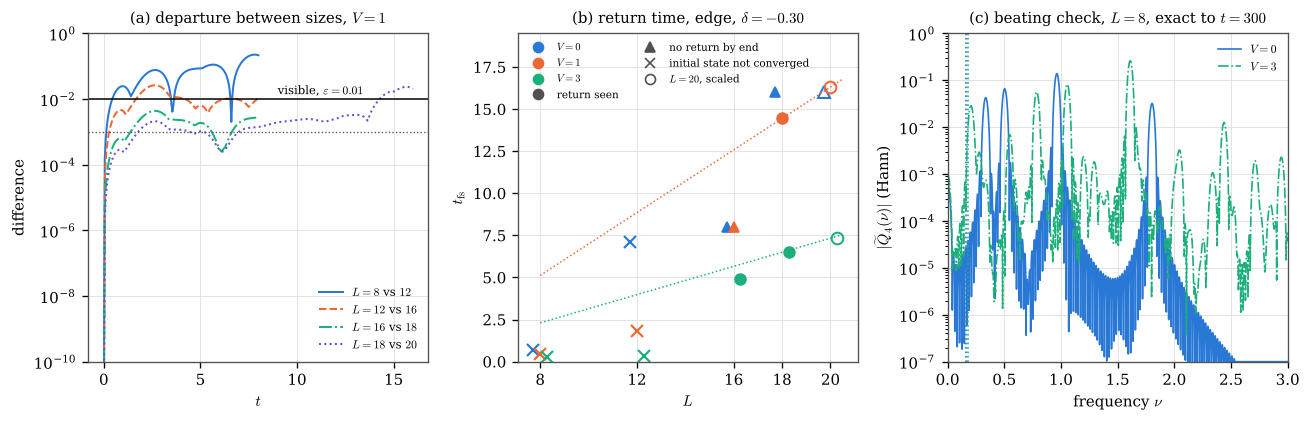

In [62]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.6))
ax = axes[0]
for i, (a, b) in enumerate([(8, 12), (12, 16), (16, 18), (18, 20)]):
    A, B = TRAJ[traj_key(a, -0.30, 1.0, 0)], TRAJ[traj_key(b, -0.30, 1.0, 0)]
    n = min(len(A["t"]), len(B["t"]))
    qa, qb = Q_edge(A, 4)[:n], Q_edge(B, 4)[:n]
    diff = np.maximum(np.abs(P_return(A)[:n] - P_return(B)[:n]), np.abs((qa - qa[0]) - (qb - qb[0])))
    ax.semilogy(A["t"][:n], np.maximum(diff, 1e-12), ls=S4_LS[i], color=S4_COLORS[i], lw=1.2, label=f"$L={a}$ vs ${b}$")
ax.axhline(EPS_VISIBLE, color="k", lw=0.9)
ax.text(9.0, EPS_VISIBLE * 1.4, r"visible, $\varepsilon=0.01$", fontsize=7)
ax.axhline(EPS_TIGHT, color=GRAY, lw=0.8, ls=":")
ax.set_ylim(1e-10, 1)
ax.set_xlabel("$t$")
ax.set_ylabel("difference")
ax.set_title(r"(a) departure between sizes, $V=1$", fontsize=9)
ax.legend(fontsize=7, loc="lower right")

ax = axes[1]
for i, V in enumerate(V_BIG):
    dx = (i - 1) * 0.28
    for r in sorted([r for r in FS_ROWS if r["delta"] == -0.30 and r["V"] == V and r["injection"] == "edge"
                     and r["eps"] == EPS_VISIBLE], key=lambda r: r["L"]):
        x, y = r["L"] + dx, r["t_fs"] if r["reached"] else r["t_common_max"]
        if r["extrapolated"]:
            ax.plot([x], [min(y, 17.6)], "o" if r["reached"] else "^", ms=7, mfc="none", mew=1.2, color=S4_COLORS[i])
        elif not r["initial_state_ok"]:
            ax.plot([x], [y], "x", ms=7, mew=1.3, color=S4_COLORS[i])
        else:
            ax.plot([x], [y], "o" if r["reached"] else "^", ms=6.5, color=S4_COLORS[i])
    if V in SPEEDS and not SPEEDS[V]["upper_bound"]:
        xx = np.linspace(8, 20.5, 60)
        ax.plot(xx, (2 * (xx - 1) - 3) / SPEEDS[V]["v"], ":", color=S4_COLORS[i], lw=0.9)
handles = [Line2D([], [], color=S4_COLORS[i], marker="o", lw=0, ms=6, label=f"$V={V:g}$") for i, V in enumerate(V_BIG)]
handles += [Line2D([], [], color=GRAY, marker=m, lw=0, ms=6, mfc=fc, label=lab) for m, fc, lab in
            (("o", None, "return seen"), ("^", None, "no return by end"), ("x", None, "initial state not converged"),
             ("o", "none", "$L=20$, scaled"))]
ax.legend(handles=handles, fontsize=6.3, ncol=2, loc="upper left")
ax.set_xticks([8, 12, 16, 18, 20])
ax.set_ylim(0, 19.5)
ax.set_xlabel("$L$")
ax.set_ylabel(r"$t_{\rm fs}$")
ax.set_title(r"(b) return time, edge, $\delta=-0.30$", fontsize=9)

ax = axes[2]
for i, b in enumerate(BEAT):
    if b["V"] in (0.0, 3.0):
        ax.semilogy(b["freqs"], np.maximum(b["spectrum_hann"], 1e-7), ls=S4_LS[i], color=S4_COLORS[i], lw=1.0,
                    label=f"$V={b['V']:g}$")
        ax.axvline(b["splitting"], color=S4_COLORS[i], lw=1.0, ls=":")
ax.set_xlim(0, 3.0)
ax.set_ylim(1e-7, 1)
ax.set_xlabel(r"frequency $\nu$")
ax.set_ylabel(r"$|\widetilde Q_4(\nu)|$ (Hann)")
ax.set_title(r"(c) beating check, $L=8$, exact to $t=300$", fontsize=9)
ax.legend(fontsize=7, loc="upper right")
fig.tight_layout()
savefig(fig, "step4_finite_size_beating")
plt.show()

`step4_summary_vs_V`. Left, coherence: the late return probability against $V$, with $z_0(\mathcal W)^2$ from Step 3 (stars). Middle, localisation: the late excess charge on four sites, with $z_0(\mathcal W)\,q_4$ (stars) and $\sum z\,q_4$ over all lines below $\Delta_+$ (crosses). Right: the far-edge excess at $t=0$ against $L$ for the selected $\Omega_N$ (filled) and a left-loaded state from the same doublet (open); dashed: the $V=0$, $L\to\infty$ value $(1-r^2)^2/2$.

saved figures/step4_summary_vs_V.pdf


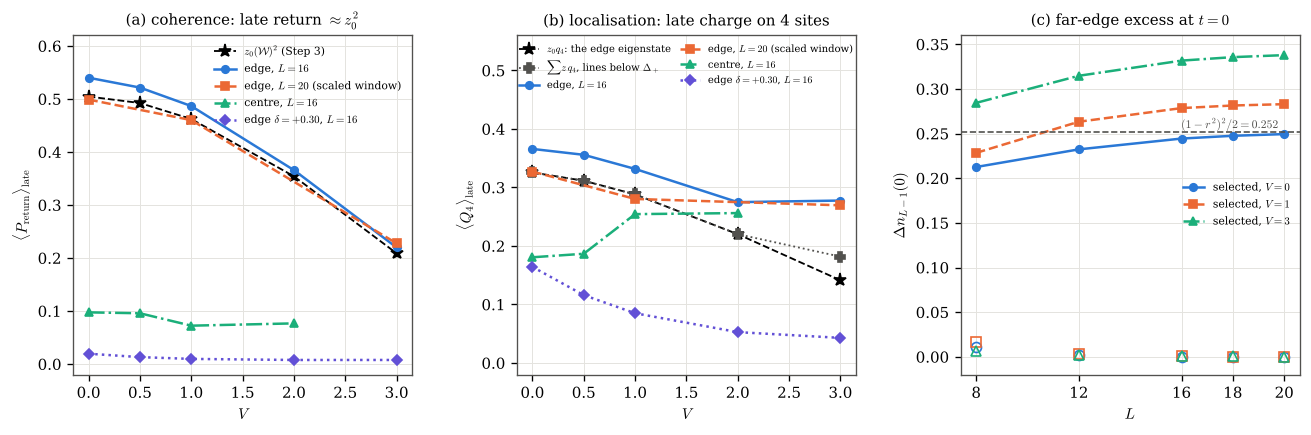

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.7))
fz = sorted([r for r in FILTERED if r["L"] == 16 and r["delta"] == -0.30 and not r["window_empty"]], key=lambda r: r["V"])
Vz, z0, q4 = (np.array([r[k] for r in fz]) for k in ("V", "z0W", "q4"))
curves = ((16, "edge", -0.30, "edge, $L=16$"), (20, "edge", -0.30, "edge, $L=20$ (scaled window)"),
          (16, "centre", -0.30, "centre, $L=16$"), (16, "edge", 0.30, r"edge $\delta=+0.30$, $L=16$"))


def late_curve(L, inj, d, col):
    s = runs.query("L == @L and injection == @inj and delta == @d and kind == 'electron'").sort_values("V")
    s = s[np.isfinite(s[col])]
    return s.V.to_numpy(), s[col].to_numpy()


ax = axes[0]
ax.plot(Vz, z0**2, "--", marker="*", ms=8, color="k", lw=1.1, label=r"$z_0(\mathcal{W})^2$ (Step 3)")
for i, (L, inj, d, lab) in enumerate(curves):
    x, y = late_curve(L, inj, d, "P_late")
    ax.plot(x, y, ls=S4_LS[i], marker=S4_MARKERS[i], color=S4_COLORS[i], label=lab)
ax.set_ylim(-0.02, 0.62)
ax.set_xlabel("$V$")
ax.set_ylabel(r"$\langle P_{\rm return}\rangle_{\rm late}$")
ax.set_title(r"(a) coherence: late return $\approx z_0^2$", fontsize=9)
ax.legend(fontsize=6.5, loc="upper right")

ax = axes[1]
ax.plot(Vz, z0 * q4, "--", marker="*", ms=8, color="k", lw=1.1, label=r"$z_0q_4$: the edge eigenstate")
Vb = sorted(V for (d, V) in BOUND_Q if d == -0.30)
ax.plot(Vb, [BOUND_Q[(-0.30, V)]["zq4"] for V in Vb], ":", marker="P", ms=6, color=GRAY, lw=1.1,
        label=r"$\sum z\,q_4$, lines below $\Delta_+$")
for i, (L, inj, d, lab) in enumerate(curves):
    x, y = late_curve(L, inj, d, "Q4_late")
    ax.plot(x, y, ls=S4_LS[i], marker=S4_MARKERS[i], color=S4_COLORS[i], label=lab)
ax.set_ylim(-0.02, 0.56)
ax.set_xlabel("$V$")
ax.set_ylabel(r"$\langle Q_4\rangle_{\rm late}$")
ax.set_title("(b) localisation: late charge on 4 sites", fontsize=9)
ax.legend(fontsize=6, loc="upper center", ncol=2, columnspacing=0.8)

ax = axes[2]
for i, V in enumerate(V_BIG):
    s = far[far.V == V].sort_values("L")
    ax.plot(s.L, s.selected, ls=S4_LS[i], marker=S4_MARKERS[i], color=S4_COLORS[i], label=f"selected, $V={V:g}$")
    ax.plot(s.L, s.left_loaded, lw=0, marker=S4_MARKERS[i], mfc="none", ms=6, color=S4_COLORS[i])
ax.axhline(FAR_LIMIT, color=GRAY, lw=1.0, ls="--")
ax.text(19.8, FAR_LIMIT, rf"$(1-r^2)^2/2={FAR_LIMIT:.3f}$", fontsize=7, color=GRAY, ha="right", va="bottom")
ax.set_ylim(-0.02, 0.36)
ax.set_xticks([8, 12, 16, 18, 20])
ax.set_xlabel("$L$")
ax.set_ylabel(r"$\Delta n_{L-1}(0)$")
ax.set_title("(c) far-edge excess at $t=0$", fontsize=9)
ax.legend(fontsize=6.5, loc="center right")
fig.tight_layout()
savefig(fig, "step4_summary_vs_V")
plt.show()

### 4.12 Saved data

`data/step4_runs.csv` (one row per run and per filtered preparation: checks, windows, late means), `step4_finite_size.csv`, `step4_tolerance_scan.csv`, `step4_beating.csv`, `step4_far_edge.csv`, `step4_bound_lines.csv`, `step4_moments.csv`, `step4_trajectories.npz` (every trajectory: columns $t$, Re $G$, Im $G$, norm, energy, $\Delta n_0\dots\Delta n_{L-1}$), `step4_traces_*.csv` (representative time series) and `step4_run_info.json`.

In [64]:
def npz_key(k):
    return "_".join(str(x) for x in k).replace(".", "p").replace("-", "m").replace("+", "p")


pd.concat([runs, pd.DataFrame(FILTERED)], ignore_index=True).to_csv(DATA_DIR / "step4_runs.csv", index=False,
                                                                      float_format="%.12g")
pd.DataFrame(FS_ROWS).to_csv(DATA_DIR / "step4_finite_size.csv", index=False, float_format="%.12g")
scan.to_csv(DATA_DIR / "step4_tolerance_scan.csv", index=False, float_format="%.12g")
pd.concat([pd.DataFrame([{k: v for k, v in b.items() if k not in ("freqs", "spectrum_hann")} for b in BEAT]),
           pd.DataFrame(PERIODS)], ignore_index=True).to_csv(DATA_DIR / "step4_beating.csv", index=False, float_format="%.12g")
far.to_csv(DATA_DIR / "step4_far_edge.csv", index=False, float_format="%.12g")
pd.DataFrame(LINE_ROWS).to_csv(DATA_DIR / "step4_bound_lines.csv", index=False, float_format="%.12g")
moments.to_csv(DATA_DIR / "step4_moments.csv", index=False, float_format="%.12g")
np.savez_compressed(DATA_DIR / "step4_trajectories.npz",
                    **{npz_key(k): np.column_stack([tr["t"], tr["G"].real, tr["G"].imag, tr["norm"], tr["energy"], tr["dn"]])
                       for k, tr in TRAJ.items()})
n_traces = 0
for V in V_BIG:
    for k in (traj_key(16, -0.30, V, 0), traj_key(16, -0.30, V, centre_site(16)), traj_key(16, 0.30, V, 0),
              traj_key(16, -0.30, V, 0, "filtered"), traj_key(20, -0.30, V, 0)):
        tr = TRAJ[k]
        pd.DataFrame({"t": tr["t"], "P_return": P_return(tr), "ReG": tr["G"].real, "ImG": tr["G"].imag,
                      "Q2": Q_local(tr, 2), "Q4": Q_local(tr, 4), "Qfar2": Q_far(tr, 2), "Qfar4": Q_far(tr, 4),
                      "sum_dn": tr["dn"].sum(axis=1), "norm": tr["norm"], "energy": tr["energy"]}).to_csv(
            DATA_DIR / f"step4_traces_{'_'.join(str(x) for x in k).replace('.', 'p')}.csv", index=False, float_format="%.12g")
        n_traces += 1
run_info = {"preparation": "|Psi(0)> = c_j^dag |Omega_N> / sqrt(1 - <n_j>), Omega_N by the Step 2 rule (STATES)",
            "evolution": "exp(-i (H_{N+1} - E_0^N) t); E_0^N kept so G(t) is compared with Step 3 as a complex amplitude",
            "centre_site": "2 * (L // 4)", "Q_edge": "sum_{j < l_e} Delta n_j, l_e = 2, 4",
            "krylov": f"short-iterative Lanczos, full reorthogonalisation, error estimate <= tol * dt, tol = {KRYLOV_TOL} "
                      f"per unit time, halved to {KRYLOV_TOL / 2}; dimension cap {KRYLOV_M_MAX}",
            "dt": DT, "t_max": T_MAX, "t_extended": T_EXT, "L": L_S4, "L_ladder": L_LADDER, "delta": DELTA_S4,
            "V": V_S4, "V_ladder": V_BIG,
            "finite_size_window": f"first t where P_return or Q_l (l = 2, 4) departs from the next larger L by more than "
                                  f"{EPS_VISIBLE} + 2 x static offset; {EPS_TIGHT} also recorded",
            "late_window": "second half of the certified interval, from t >= 2",
            "filtered": "projection onto Step 3's window: F_WINDOW, or the widest f in F_SCAN holding one line",
            "spectral_reference": f"Step 3 site_spectra (L <= 12), Lanczos measure with {K_SPEC} vectors (L = 16)",
            "implied_return_speed": {str(V): {"v": s["v"], "upper_bound": s["upper_bound"]} for V, s in SPEEDS.items()},
            "free_max_group_velocity": V_FREE, "reproduce_command": "jupyter nbconvert --to notebook --execute --inplace <notebook>",
            "python": platform.python_version(), "numpy": np.__version__, "scipy": scipy.__version__,
            "pandas": pd.__version__, "matplotlib": plt.matplotlib.__version__}
(DATA_DIR / "step4_run_info.json").write_text(json.dumps(run_info, indent=2, default=float) + "\n")
print(f"saved {DATA_DIR}/step4_runs.csv ({len(runs) + len(FILTERED)} rows), step4_finite_size.csv, step4_tolerance_scan.csv, "
      f"step4_beating.csv, step4_far_edge.csv, step4_bound_lines.csv, step4_moments.csv, "
      f"step4_trajectories.npz ({len(TRAJ)} trajectories), {n_traces} step4_traces_*.csv, step4_run_info.json")

saved data/step4_runs.csv (119 rows), step4_finite_size.csv, step4_tolerance_scan.csv, step4_beating.csv, step4_far_edge.csv, step4_bound_lines.csv, step4_moments.csv, step4_trajectories.npz (98 trajectories), 15 step4_traces_*.csv, step4_run_info.json


### 4.13 Figures of the short Step 4 report

The same runs, drawn as in the short report: one figure per guide item.
`step4_s1_validation` (item 1): $P_{\rm return}$ at $L=8$ from Krylov (lines), full diagonalisation (circles) and Step 3's spectral sum (crosses), and the deviations of the complex amplitude.
`step4_s2_density_profile` (item 3): $\Delta n_j(t)$ for edge injection at $L=16$, as a map and at five times.
`step4_s3_return_and_charge` (items 2, 3): $P_{\rm return}$ and $Q_{\rm edge}$, edge against the two controls; shaded after the certified interval.
`step4_s4_reflections_beating` (item 4): $P_{\rm return}$ for growing $L$; the departure of $L=16$ from $L=18$ beyond the static allowance $2s$; the reflection at $L=20$; the beating spectrum.
`step4_s5_filtered` (item 5): filtered against unfiltered preparation.

saved figures/step4_s1_validation.pdf


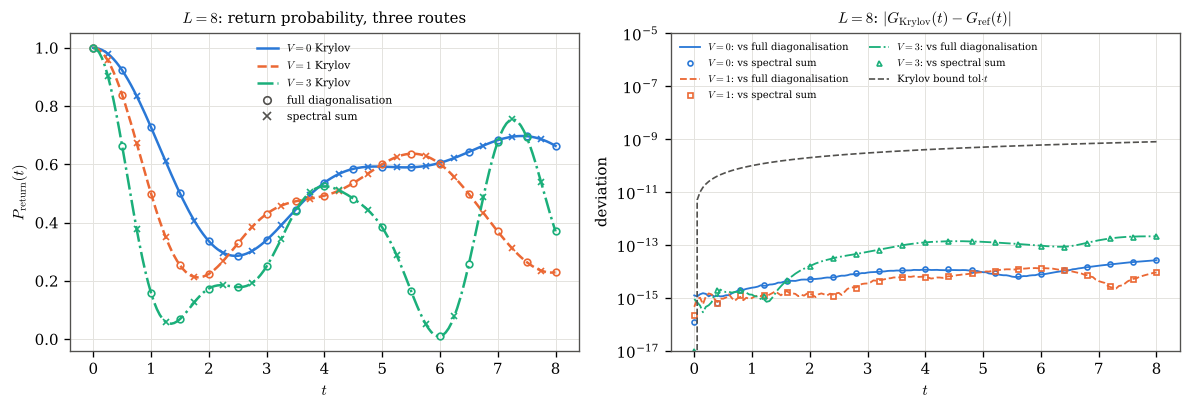

saved figures/step4_s2_density_profile.pdf


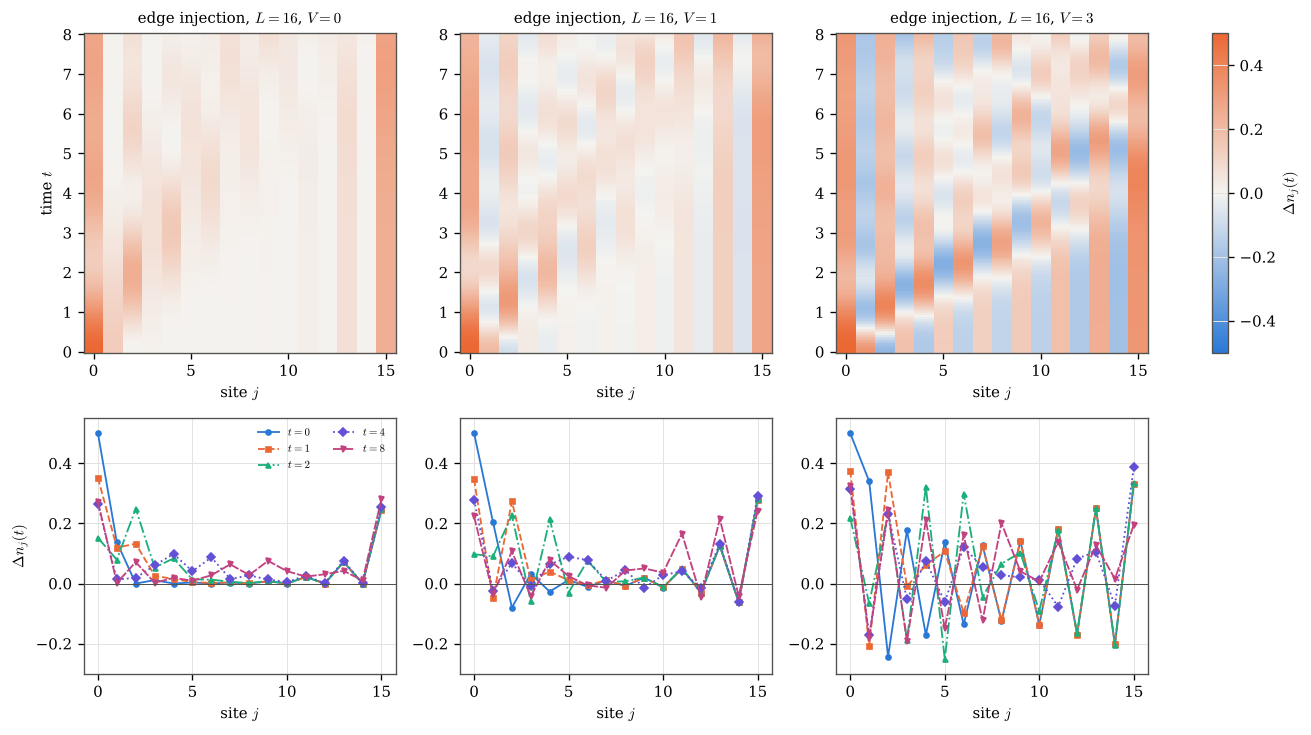

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for i, V in enumerate(V_BIG):
    tr = TRAJ[traj_key(8, -0.30, V, 0)]
    ex = evolve_exact(tr["prep"])
    G = spectral_amplitude(step3_lines(8, -0.30, V, 0), tr["t"])
    axes[0].plot(tr["t"], P_return(tr), ls=S4_LS[i], color=S4_COLORS[i], label=f"$V={V:g}$ Krylov")
    axes[0].plot(ex["t"][::10], P_return(ex)[::10], "o", mfc="none", color=S4_COLORS[i], ms=4)
    axes[0].plot(tr["t"][5::10], np.abs(G[5::10]) ** 2, "x", color=S4_COLORS[i], ms=4)
    axes[1].semilogy(tr["t"], np.abs(tr["G"] - ex["G"]) + 1e-17, ls=S4_LS[i], color=S4_COLORS[i], lw=1.1,
                     label=f"$V={V:g}$: vs full diagonalisation")
    axes[1].semilogy(tr["t"][::8], np.abs(tr["G"] - G)[::8] + 1e-17, S4_MARKERS[i], color=S4_COLORS[i], ms=3,
                     mfc="none", label=f"$V={V:g}$: vs spectral sum")
axes[0].plot([], [], "o", mfc="none", color=GRAY, label="full diagonalisation")
axes[0].plot([], [], "x", color=GRAY, label="spectral sum")
axes[0].set_xlabel("$t$")
axes[0].set_ylabel(r"$P_{\rm return}(t)$")
axes[0].set_title("$L=8$: return probability, three routes", fontsize=9)
axes[0].legend(fontsize=6.5)
tb = time_grid(T_MAX)
axes[1].semilogy(tb, KRYLOV_TOL * tb, "--", color=GRAY, lw=1, label=r"Krylov bound tol$\cdot t$")
axes[1].set_ylim(1e-17, 1e-5)
axes[1].set_xlabel("$t$")
axes[1].set_ylabel("deviation")
axes[1].set_title(r"$L=8$: $|G_{\rm Krylov}(t)-G_{\rm ref}(t)|$", fontsize=9)
axes[1].legend(fontsize=6, ncol=2, loc="upper left")
fig.tight_layout()
savefig(fig, "step4_s1_validation")
plt.show()

fig = plt.figure(figsize=(11, 6.2))
gs = fig.add_gridspec(2, 4, width_ratios=[1, 1, 1, 0.05], height_ratios=[1.25, 1])
for i, V in enumerate(V_BIG):
    tr = TRAJ[traj_key(16, -0.30, V, 0)]
    ax = fig.add_subplot(gs[0, i])
    im = ax.pcolormesh(np.arange(17) - 0.5, np.append(tr["t"], tr["t"][-1] + DT) - DT / 2, tr["dn"], cmap=S4_DIVERGING,
                       vmin=-0.5, vmax=0.5, shading="flat", rasterized=True)
    ax.grid(False)
    ax.set_title(f"edge injection, $L=16$, $V={V:g}$", fontsize=9)
    ax.set_xlabel("site $j$")
    if i == 0:
        ax.set_ylabel("time $t$")
    ax2 = fig.add_subplot(gs[1, i])
    for k, ts in enumerate((0.0, 1.0, 2.0, 4.0, 8.0)):
        ax2.plot(np.arange(16), tr["dn"][int(round(ts / DT))], ls=S4_LS[k], marker=S4_MARKERS[k], ms=3, lw=1.1,
                 color=S4_COLORS[k], label=f"$t={ts:g}$")
    ax2.axhline(0, color=GRAY, lw=0.6)
    ax2.set_ylim(-0.3, 0.55)
    ax2.set_xlabel("site $j$")
    if i == 0:
        ax2.set_ylabel(r"$\Delta n_j(t)$")
        ax2.legend(fontsize=6.5, ncol=2)
fig.colorbar(im, cax=fig.add_subplot(gs[0, 3]), label=r"$\Delta n_j(t)$")
fig.tight_layout()
savefig(fig, "step4_s2_density_profile")
plt.show()

saved figures/step4_s3_return_and_charge.pdf


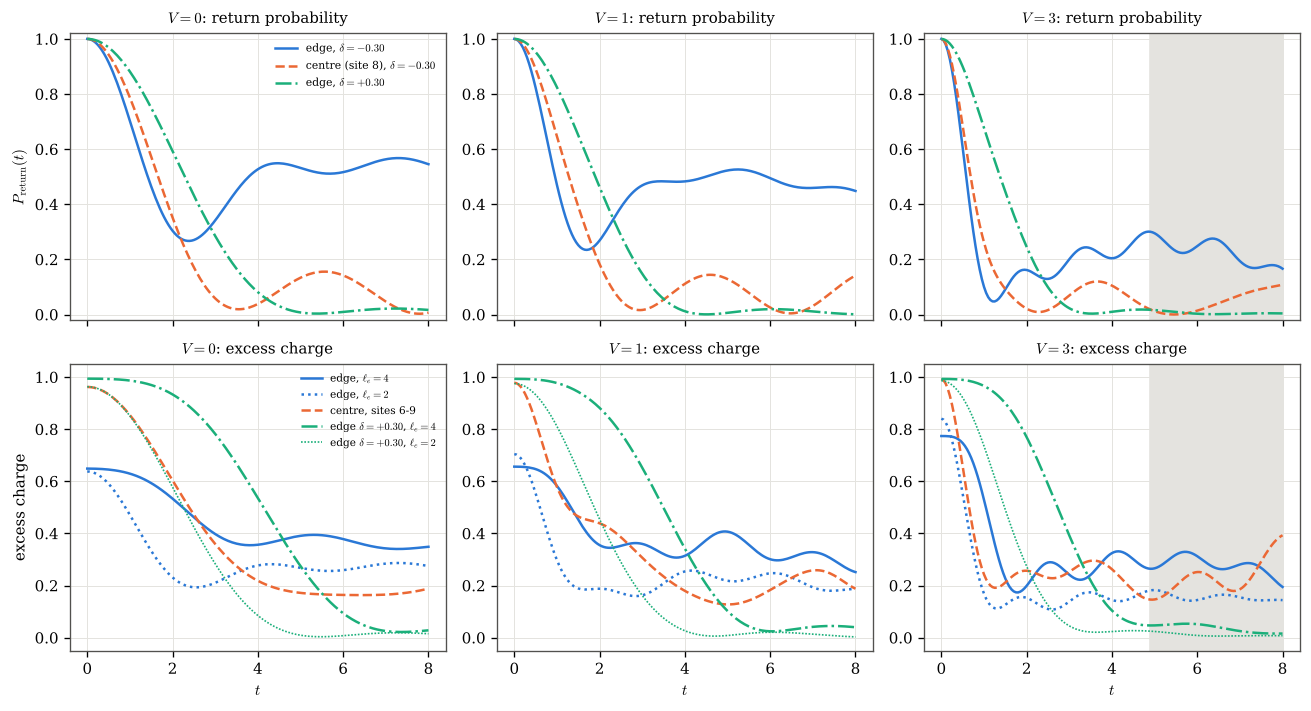

saved figures/step4_s4_reflections_beating.pdf


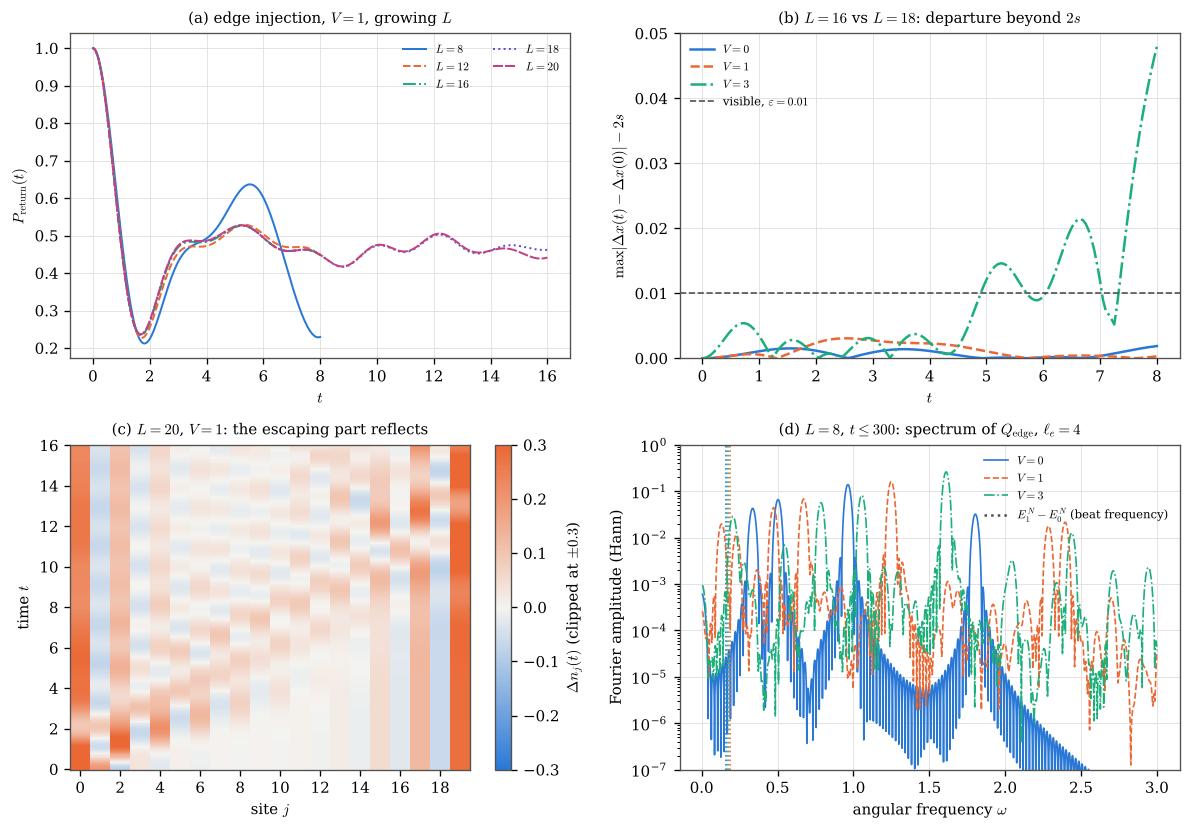

saved figures/step4_s5_filtered.pdf


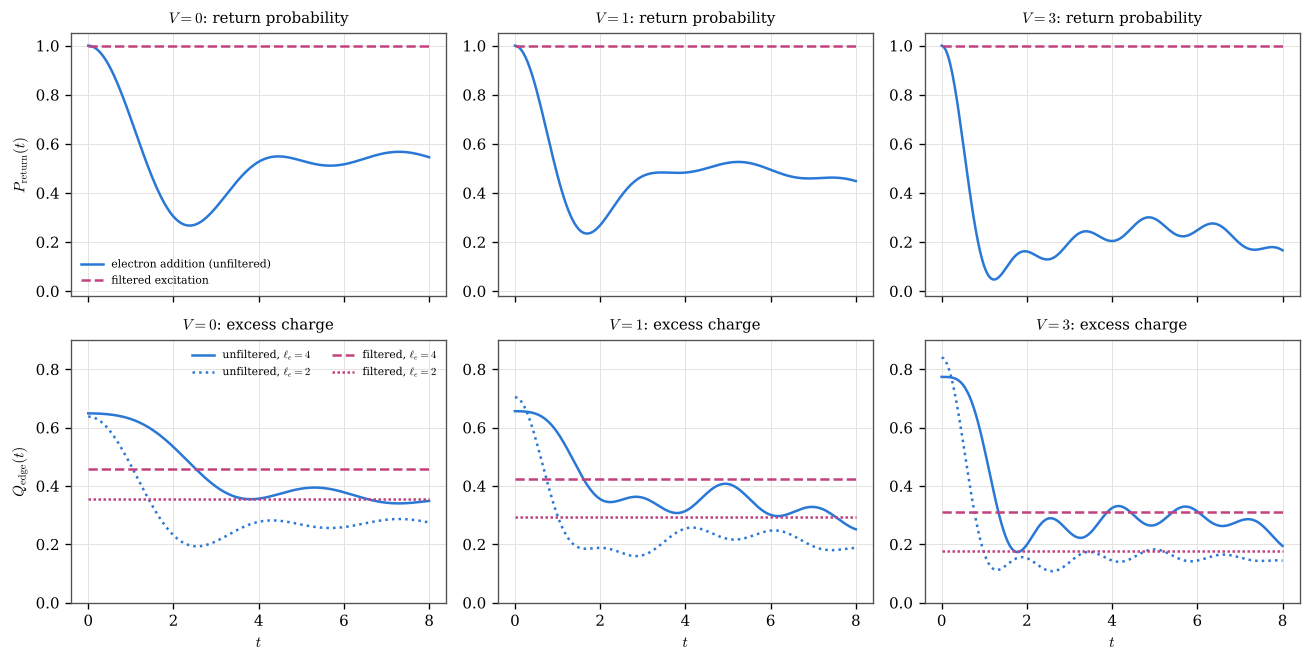

In [66]:
fig, ax = plt.subplots(2, 3, figsize=(11, 6.0), sharex=True)
jc = centre_site(16)
for i, V in enumerate(V_BIG):
    e, c, o = (TRAJ[traj_key(16, d, V, s)] for d, s in ((-0.30, 0), (-0.30, jc), (0.30, 0)))
    t = e["t"]
    ax[0, i].plot(t, P_return(e), color=S4_COLORS[0], label=r"edge, $\delta=-0.30$")
    ax[0, i].plot(t, P_return(c), "--", color=S4_COLORS[1], label=rf"centre (site {jc}), $\delta=-0.30$")
    ax[0, i].plot(t, P_return(o), "-.", color=S4_COLORS[2], label=r"edge, $\delta=+0.30$")
    ax[1, i].plot(t, Q_edge(e, 4), color=S4_COLORS[0], label=r"edge, $\ell_e=4$")
    ax[1, i].plot(t, Q_edge(e, 2), ":", color=S4_COLORS[0], label=r"edge, $\ell_e=2$")
    ax[1, i].plot(t, Q_local(c, 4), "--", color=S4_COLORS[1], label=f"centre, sites {jc - 2}-{jc + 1}")
    ax[1, i].plot(t, Q_edge(o, 4), "-.", color=S4_COLORS[2], label=r"edge $\delta=+0.30$, $\ell_e=4$")
    ax[1, i].plot(t, Q_edge(o, 2), ls=(0, (1, 1)), lw=1.0, color=S4_COLORS[2], label=r"edge $\delta=+0.30$, $\ell_e=2$")
    t_fs = FS_LOOKUP.get((16, -0.30, V, "edge"), np.inf)
    for a in ax[:, i]:
        if np.isfinite(t_fs) and t_fs < T_MAX:
            a.axvspan(t_fs, T_MAX, color=LIGHT, zorder=0)
    ax[0, i].set_ylim(-0.02, 1.02)
    ax[1, i].set_ylim(-0.05, 1.05)
    ax[0, i].set_title(f"$V={V:g}$: return probability", fontsize=9)
    ax[1, i].set_title(f"$V={V:g}$: excess charge", fontsize=9)
    ax[1, i].set_xlabel("$t$")
ax[0, 0].set_ylabel(r"$P_{\rm return}(t)$")
ax[1, 0].set_ylabel("excess charge")
ax[0, 0].legend(fontsize=6.5)
ax[1, 0].legend(fontsize=6.3)
fig.tight_layout()
savefig(fig, "step4_s3_return_and_charge")
plt.show()

fig, ax = plt.subplots(2, 2, figsize=(10, 7.0))
for i, L in enumerate(L_S4 + L_LADDER):
    tr = TRAJ[traj_key(L, -0.30, 1.0, 0)]
    ax[0, 0].plot(tr["t"], P_return(tr), ls=S4_LS[i], color=S4_L_COLORS[L], lw=1.2, label=f"$L={L}$")
ax[0, 0].legend(fontsize=7, ncol=2)
ax[0, 0].set_xlabel("$t$")
ax[0, 0].set_ylabel(r"$P_{\rm return}(t)$")
ax[0, 0].set_title(r"(a) edge injection, $V=1$, growing $L$", fontsize=9)
for i, V in enumerate(V_BIG):
    a, b = TRAJ[traj_key(16, -0.30, V, 0)], TRAJ[traj_key(18, -0.30, V, 0)]
    n = min(len(a["t"]), len(b["t"]))
    excess = np.full(n, -np.inf)
    for f in (P_return, lambda x: Q_edge(x, 2), lambda x: Q_edge(x, 4)):
        x, y = f(a)[:n], f(b)[:n]
        excess = np.maximum(excess, np.abs((x - x[0]) - (y - y[0])) - 2 * abs(x[0] - y[0]))
    ax[0, 1].plot(a["t"][:n], np.clip(excess, 0, None), ls=S4_LS[i], color=S4_COLORS[i], label=f"$V={V:g}$")
ax[0, 1].axhline(EPS_VISIBLE, color=GRAY, ls="--", lw=1, label=r"visible, $\varepsilon=0.01$")
ax[0, 1].set_ylim(0, 0.05)
ax[0, 1].legend(fontsize=7)
ax[0, 1].set_xlabel("$t$")
ax[0, 1].set_ylabel(r"$\max|\Delta x(t)-\Delta x(0)|-2s$")
ax[0, 1].set_title(r"(b) $L=16$ vs $L=18$: departure beyond $2s$", fontsize=9)
tr = TRAJ[traj_key(20, -0.30, 1.0, 0)]
im = ax[1, 0].pcolormesh(np.arange(21) - 0.5, np.append(tr["t"], tr["t"][-1] + DT) - DT / 2, tr["dn"],
                         cmap=S4_DIVERGING, vmin=-0.3, vmax=0.3, shading="flat", rasterized=True)
ax[1, 0].grid(False)
ax[1, 0].set_xticks(range(0, 20, 2))
fig.colorbar(im, ax=ax[1, 0], label=r"$\Delta n_j(t)$ (clipped at $\pm0.3$)")
ax[1, 0].set_xlabel("site $j$")
ax[1, 0].set_ylabel("time $t$")
ax[1, 0].set_title(r"(c) $L=20$, $V=1$: the escaping part reflects", fontsize=9)
for i, b in enumerate(BEAT):
    ax[1, 1].semilogy(b["freqs"], b["spectrum_hann"] + 1e-9, ls=S4_LS[i], color=S4_COLORS[i], lw=1.0, label=f"$V={b['V']:g}$")
    ax[1, 1].axvline(b["splitting"], color=S4_COLORS[i], ls=":", lw=1.0)
ax[1, 1].plot([], [], ":", color=GRAY, label=r"$E^N_1-E^N_0$ (beat frequency)")
ax[1, 1].set_ylim(1e-7, 1)
ax[1, 1].legend(fontsize=7, loc="upper right")
ax[1, 1].set_xlabel(r"angular frequency $\omega$")
ax[1, 1].set_ylabel("Fourier amplitude (Hann)")
ax[1, 1].set_title(r"(d) $L=8$, $t\leq300$: spectrum of $Q_{\rm edge}$, $\ell_e=4$", fontsize=9)
fig.tight_layout()
savefig(fig, "step4_s4_reflections_beating")
plt.show()

fig, ax = plt.subplots(2, 3, figsize=(11, 5.6), sharex=True)
for i, V in enumerate(V_BIG):
    u, f = TRAJ[traj_key(16, -0.30, V, 0)], TRAJ[traj_key(16, -0.30, V, 0, "filtered")]
    ax[0, i].plot(u["t"], P_return(u), color=S4_COLORS[0], label="electron addition (unfiltered)")
    ax[0, i].plot(f["t"], P_return(f), "--", color=S4_COLORS[4], label="filtered excitation")
    ax[1, i].plot(u["t"], Q_edge(u, 4), color=S4_COLORS[0], label=r"unfiltered, $\ell_e=4$")
    ax[1, i].plot(u["t"], Q_edge(u, 2), ":", color=S4_COLORS[0], label=r"unfiltered, $\ell_e=2$")
    ax[1, i].plot(f["t"], Q_edge(f, 4), "--", color=S4_COLORS[4], label=r"filtered, $\ell_e=4$")
    ax[1, i].plot(f["t"], Q_edge(f, 2), ls=(0, (1, 1)), color=S4_COLORS[4], label=r"filtered, $\ell_e=2$")
    ax[0, i].set_ylim(-0.02, 1.05)
    ax[1, i].set_ylim(0, 0.9)
    ax[0, i].set_title(f"$V={V:g}$: return probability", fontsize=9)
    ax[1, i].set_title(f"$V={V:g}$: excess charge", fontsize=9)
    ax[1, i].set_xlabel("$t$")
ax[0, 0].set_ylabel(r"$P_{\rm return}(t)$")
ax[1, 0].set_ylabel(r"$Q_{\rm edge}(t)$")
ax[0, 0].legend(fontsize=6.5, loc="lower left")
ax[1, 0].legend(fontsize=6.5, ncol=2)
fig.tight_layout()
savefig(fig, "step4_s5_filtered")
plt.show()

### 4.14 Results and what they show

**Numerics.** Krylov, full diagonalisation and Step 3's spectral sum agree on the complex amplitude to $1.2\times10^{-12}$ at $L\le16$ (A1, A2), and halving the tolerance changes the results by at most $1.3\times10^{-12}$ (A3). Norm, energy and $\sum_j\Delta n_j=1$ hold to $1.5\times10^{-12}$ at every size up to $L=20$ (B1). These are more than 500 times below the accumulated bound $8\times10^{-10}$, and the tolerance scan shows that the bound is a real control (A4). At $V=0$ the whole calculation equals one-body propagation with Step 1's $h$ to $3\times10^{-12}$ (B3).

**Finite-size-free interval (guide item 4).** $L=8$ and $L=12$ get no interval: their initial states already differ from the next size by $s=0.05$-$0.09$ and $0.014$-$0.031$, more than $\varepsilon=0.01$, because the far edge is only a few $\xi$ away. $L=16$ is free of visible returns for all $t\le8$ at $V\le2$, and for $t<4.90$ at $V=3$. $L=18$: no return to $t=16$ at $V=0$, $t<14.45$ at $V=1$, $t<6.50$ at $V=3$. The returns come faster with $V$: the implied speed is $\le1.94$, $2.15$ and $4.77$ sites per unit time at $V=0,1,3$, against the free maximal group velocity $1.40$. All late-time numbers below are averaged inside these intervals only.

**Coherence.** For edge injection at $\delta=-0.30$ the return probability does not decay to zero; it settles near $z_0(\mathcal W)^2$, the square of the edge line's weight from Step 3:

| $V$ | 0 | 0.5 | 1 | 2 | 3 |
|---|---|---|---|---|---|
| $\langle P_{\rm return}\rangle_{\rm late}$, $L=16$ | 0.540 | 0.522 | 0.487 | 0.366 | 0.220 |
| $z_0(\mathcal W)^2$, $L=16$ | 0.505 | 0.492 | 0.462 | 0.354 | 0.209 |
| $\langle P_{\rm return}\rangle_{\rm late}$, $L=20$ ($t\le16$) | 0.499 | | 0.460 | | 0.228 |

At $L=20$, where the interval reaches $t=16$, the agreement at $V=0,1$ is within 0.006. The controls lose the particle: $\langle P_{\rm return}\rangle_{\rm late}=0.020$ to $0.008$ for $\delta=+0.30$, and $0.07$-$0.10$ for centre injection.

**Localisation.** The late excess charge on the first four sites, against what the edge eigenstate carries ($z_0q_4$) and what all lines below $\Delta_+$ carry ($\sum z\,q_4$, from 4.8):

| $V$ | 0 | 0.5 | 1 | 2 | 3 |
|---|---|---|---|---|---|
| $\langle Q_4\rangle_{\rm late}$, $L=16$ | 0.366 | 0.356 | 0.332 | 0.275 | 0.278 |
| $\langle Q_4\rangle_{\rm late}$, $L=20$ ($t\le16$) | 0.327 | | 0.280 | | 0.270 |
| $z_0q_4$, $L=16$ | 0.326 | 0.312 | 0.288 | 0.220 | 0.141 |
| $\sum z\,q_4$ below $\Delta_+$, $L=16$ | 0.326 | 0.312 | 0.288 | 0.220 | 0.182 |

At $L=20$ the retained charge matches $z_0q_4$ to 0.008 at $V=0,1$. At $L=16$ the averaging window ends at $t=8$, before the escaping part has fully left, so the excess there is charge still in transit. At $V=3$ the retained charge, 0.27-0.28 at both sizes, stays above both predictions; the certified interval is short there ($t<4.9$ at $L=16$, $t<7.3$ at $L=20$), so this is a statement about the first few time units, not a stationary value. For $\delta=+0.30$ the edge keeps nothing: $\langle Q_4\rangle_{\rm late}$ falls from 0.164 to 0.043 as $V$ grows.

**Beating.** The doublet splitting gives beat periods of 34-40 at $L=8$, 480-660 at $L=16$ and 1660-3280 at $L=20$, far beyond every run. Even at $L=8$, evolved exactly to $t=300$, $Q_{\rm edge}(t)$ has no Fourier weight at the splitting (about 2% of its largest component at most), and the diagonal ensemble splits the excess charge exactly $\tfrac12:\tfrac12$ between the halves (E1, E2).

**Far edge at $t=0$.** $\Delta n_{L-1}(0)$ is 0.249 at $L=20$, $V=0$ (limit $(1-r^2)^2/2=0.252$), and grows with $V$ to 0.338 at $V=3$. It is a correlation of the selected $\Omega_N$, not transport: for a left- or right-loaded state from the same doublet it is below $10^{-3}$ at $L\ge16$ (E3).

**Filtered excitation (guide item 5).** Projecting onto Step 3's window keeps a fraction $z_0(\mathcal W)$ of the electron (0.710 to 0.457 at $L=16$, equal to Step 3 to $10^{-14}$), and gives a state with $P_{\rm return}=1$ and a static profile that carries exactly half its charge at each end (C1, C2). This is a stationary state by construction, not evidence for a long lifetime; the unfiltered electron is the physical preparation.

**Answer for Steps 1-4.** On these sizes and up to $V=3$, a particle added at the weak-bond edge splits into a coherent part, of weight $z_0(\mathcal W)$, that stays on the edge eigenstate, and a part that leaves into the bulk. Within the certified intervals the late return probability tracks $z_0(\mathcal W)^2$ and the retained edge charge tracks $z_0(\mathcal W)\,q_4$, both decreasing with $V$ but nonzero; the trivial edge ($\delta=+0.30$) and the centre retain much less. A revival in a short chain is not a long lifetime in the infinite system, which is why every late value is restricted to the interval certified against the next larger $L$.

In [67]:
step4 = {name: c for name, c in CHECKS.items() if name.startswith("S4 ")}
n_pass = sum(c["pass"] for c in step4.values())
print(f"Step 4: {n_pass}/{len(step4)} checks passed")
for name, c in step4.items():
    if not c["pass"]:
        print("  FAILED:", name)
pd.DataFrame([{"check": name, "passed": c["pass"], "worst_deviation": c["value"]} for name, c in step4.items()]).to_csv(
    DATA_DIR / "step4_checks.csv", index=False, float_format="%.3e")
print(f"all steps: {sum(c['pass'] for c in CHECKS.values())}/{len(CHECKS)} checks passed")
print(f"python {platform.python_version()}, numpy {np.__version__}, scipy {scipy.__version__}, pandas {pd.__version__}, "
      f"matplotlib {plt.matplotlib.__version__}, mpmath {mpmath.__version__}")

Step 4: 38/38 checks passed
all steps: 159/159 checks passed
python 3.13.18, numpy 2.5.3, scipy 1.18.1, pandas 3.0.5, matplotlib 3.11.2, mpmath 1.4.1
